# Two Tier Autonomous Delivery Network

---


## Setup and Imports

Import all necessary libraries and load the instance data.

In [1]:
# Import required libraries
import gurobipy as gp
from gurobipy import GRB
import json
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import re
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import copy

In [2]:
data_small = {
  "network": {
    "sectors": [0, 1, 2, 3, 4, 5, 6],
    "adjacency": {
      "0": [1, 2, 3],
      "1": [0, 2, 4],
      "2": [0, 1, 3, 5],
      "3": [0, 2, 6],
      "4": [1, 5],
      "5": [2, 4, 6],
      "6": [3, 5]
    },
    "time_steps": 12,
    "hub": 0
  },
  "drop_offs": [
    {"id": 0, "sector": 4, "deadline": 5},
    {"id": 1, "sector": 2, "deadline": 7},
    {"id": 2, "sector": 6, "deadline": 6},
    {"id": 3, "sector": 5, "deadline": 9},
    {"id": 4, "sector": 1, "deadline": 4},
    {"id": 5, "sector": 3, "deadline": 10}
  ],
  "collections": [
    {"id": 0, "sector": 4, "release_time": 3},
    {"id": 1, "sector": 6, "release_time": 4},
    {"id": 2, "sector": 5, "release_time": 6}
  ],
  "parameters": {
    "battery_limit": 4,
    "max_tasks_per_step": 2,
    "van_package_capacity": 3,
    "rover_package_capacity": 1,
    "van_bay_limit": 2,
    "num_vans": 2,
    "num_rovers": 3,
    "van_fixed_cost": 50,
    "rover_energy_cost": 2,
    "van_movement_cost": 1,
    "van_waiting_cost": 0.5
  }
}

data_medium = {
  "network": {
    "sectors": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    "adjacency": {
      "0": [1, 2, 3],
      "1": [0, 2, 4, 7],
      "2": [0, 1, 3, 5, 8],
      "3": [0, 2, 6, 9],
      "4": [1, 5, 7, 10],
      "5": [2, 4, 6, 8, 11],
      "6": [3, 5, 9],
      "7": [1, 4, 8, 10],
      "8": [2, 5, 7, 9, 11],
      "9": [3, 6, 8],
      "10": [4, 7, 11],
      "11": [5, 8, 10]
    },
    "time_steps": 20,
    "hub": 0
  },
  "drop_offs": [
    {"id": 0, "sector": 10, "deadline": 8},
    {"id": 1, "sector": 7, "deadline": 12},
    {"id": 2, "sector": 4, "deadline": 6},
    {"id": 3, "sector": 11, "deadline": 14},
    {"id": 4, "sector": 8, "deadline": 10},
    {"id": 5, "sector": 2, "deadline": 5},
    {"id": 6, "sector": 9, "deadline": 11},
    {"id": 7, "sector": 6, "deadline": 9}
  ],
  "collections": [
    {"id": 0, "sector": 10, "release_time": 6},
    {"id": 1, "sector": 5, "release_time": 8},
    {"id": 2, "sector": 11, "release_time": 10},
    {"id": 3, "sector": 3, "release_time": 4},
    {"id": 4, "sector": 8, "release_time": 7}
  ],
  "parameters": {
    "battery_limit": 5,
    "max_tasks_per_step": 2,
    "van_package_capacity": 4,
    "rover_package_capacity": 1,
    "van_bay_limit": 3,
    "num_vans": 2,
    "num_rovers": 4,
    "van_fixed_cost": 50,
    "rover_energy_cost": 2,
    "van_movement_cost": 1,
    "van_waiting_cost": 0.5
  }
}

data_large = {
  "network": {
    "sectors": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18],
    "adjacency": {
      "0": [1, 2, 3],
      "1": [0, 2, 4, 7],
      "2": [0, 1, 3, 5, 8],
      "3": [0, 2, 6, 9],
      "4": [1, 5, 7, 10],
      "5": [2, 4, 6, 8, 11],
      "6": [3, 5, 9, 12],
      "7": [1, 4, 8, 10, 13],
      "8": [2, 5, 7, 9, 11, 14],
      "9": [3, 6, 8, 12, 15],
      "10": [4, 7, 11, 13],
      "11": [5, 8, 10, 12, 14],
      "12": [6, 9, 11, 15],
      "13": [7, 10, 14, 16],
      "14": [8, 11, 13, 15, 17],
      "15": [9, 12, 14, 18],
      "16": [13, 17],
      "17": [14, 16, 18],
      "18": [15, 17]
    },
    "time_steps": 28,
    "hub": 0
  },
  "drop_offs": [
    {"id": 0, "sector": 10, "deadline": 8},
    {"id": 1, "sector": 15, "deadline": 12},
    {"id": 2, "sector": 4, "deadline": 6},
    {"id": 3, "sector": 18, "deadline": 14},
    {"id": 4, "sector": 7, "deadline": 10},
    {"id": 5, "sector": 13, "deadline": 16},
    {"id": 6, "sector": 2, "deadline": 5},
    {"id": 7, "sector": 16, "deadline": 18},
    {"id": 8, "sector": 9, "deadline": 11},
    {"id": 9, "sector": 11, "deadline": 13},
    {"id": 10, "sector": 6, "deadline": 9},
    {"id": 11, "sector": 14, "deadline": 15}
  ],
  "collections": [
    {"id": 0, "sector": 10, "release_time": 5},
    {"id": 1, "sector": 17, "release_time": 8},
    {"id": 2, "sector": 5, "release_time": 6},
    {"id": 3, "sector": 12, "release_time": 10},
    {"id": 4, "sector": 8, "release_time": 7},
    {"id": 5, "sector": 15, "release_time": 12},
    {"id": 6, "sector": 3, "release_time": 4},
    {"id": 7, "sector": 13, "release_time": 11}
  ],
  "parameters": {
    "battery_limit": 5,
    "max_tasks_per_step": 2,
    "van_package_capacity": 4,
    "rover_package_capacity": 1,
    "van_bay_limit": 3,
    "num_vans": 3,
    "num_rovers": 5,
    "van_fixed_cost": 50,
    "rover_energy_cost": 2,
    "van_movement_cost": 1,
    "van_waiting_cost": 0.5
  }
}

In [3]:
# Helper function to load instances
def load_instance(filename):
    """Load instance from JSON file using updated formulation keys."""
    with open(filename, 'r') as f:
        data = json.load(f)
    
    # Extract network 
    sectors = data['network']['sectors']
    adjacency = {int(k): v for k, v in data['network']['adjacency'].items()}
    time_steps = data['network']['time_steps']
    hub = data['network']['hub']
    
    # Extract requests 
    drop_offs = data['drop_offs']
    collections = data.get('collections', [])
    
    # Extract parameters 
    params = data['parameters']
    
    return sectors, adjacency, time_steps, hub, drop_offs, collections, params

gp.setParam('Seed', 42)
print("Helper functions loaded successfully!")

Set parameter Username
Set parameter LicenseID to value 2884075
Academic license - for non-commercial use only - expires 2027-11-12
Set parameter Seed to value 42
Helper functions loaded successfully!


---

# Phase 1: Core Model – Van-Rover Drop-offs

**Objective:** Minimize the overarching routing and operational costs for vans and rovers fulfilling all drop-off tasks.

**Features:**
- Rovers can be stowed and transported inside vans (consuming zero energy while on board).
- Rovers are restricted by a single, global battery allowance for the entire operational horizon.
- No dynamic recharging (rover batteries cannot be reset or restored mid-route).
- Exclusively processes drop-off tasks (no collection tasks included).

---

### Mathematical Formulation

#### Sets and Indices
- $\mathcal{Z}$: Set of sectors (spatial nodes).
- $\mathcal{T} = \{0, \dots, T_{max}\}$: Set of discretized time steps.
- $\mathcal{N}$: Set of time-space coordinates, where $u = (z, t) \in \mathcal{N}$.
- $\mathcal{A}$: The complete set of directed links in the time-space grid, dictating flow from $t$ to $t+1$.
    * $\mathcal{A}_{Van} \subseteq \mathcal{A}$: Links traversable by Carrier Vans.
    * $\mathcal{A}_{Rover} \subseteq \mathcal{A}$: Links traversable by Rovers (operating autonomously or stowed).
    * $\mathcal{A}_{Del} \subseteq \mathcal{A}$: Virtual links designated for executing drop-off actions.
    * $\mathcal{A}_{Shelf} \subseteq \mathcal{A}$: Virtual links at the Central Hub representing package inventory/storage.
- $\mathcal{K}$: Set of all tracked packages (drop-offs + collections).
- $\mathcal{F}$: Set of all asset types $\{\text{Van}, \text{Rover}, \text{Del\_Van}, \text{Del\_Rv}, \text{Hub\_Shelf}\}$. 
- $\mathcal{E} = \{0, \dots, R\}$: Set of discrete battery levels for rovers.
- $Pred(n)$: Set of predecessor coordinates (incoming links to $n$).
- $Succ(n)$: Set of successor coordinates (outgoing links from $n$).


#### Parameters
- $C_{fix}^{van}$: Fixed dispatch cost for deploying a van.
- $C_{move}^{van}$: Operational cost per link for a van transitioning between sectors.
- $C_{wait}^{van}$: Idling cost per time step for a stationary van.
- $C_{energy}^{rover}$: Cost per unit of battery depleted by a rover.
- $E_{move}, E_{del}$: Battery drain required for a spatial transition and a drop-off action, respectively.
- $R$: Maximum battery capacity of a rover.

#### Decision Variables
- $x_{ij}^{k,f} \in \{0, 1\}$: Binary tracking variable. Equals 1 if package $k$ travels across link $(i,j)$ via asset $f$.
- $y_{ij}^{f} \in \mathbb{Z}_{\geq 0}$: Integer routing variable. Represents the count of assets of type $f$ traversing link $(i,j)$.
- $z_{ij, e}^{fly} \in \mathbb{Z}_{\geq 0}$: Count of rovers operating autonomously (ground transition or idling) on link $(i,j)$, arriving at the next node with battery level $e$.
- $z_{ij, e}^{del} \in \mathbb{Z}_{\geq 0}$: Count of rovers executing a drop-off action on link $(i,j)$, completing the task with battery level $e$.
- $z_{ij, e}^{ride} \in \mathbb{Z}_{\geq 0}$: Count of rovers stowed securely inside a van on link $(i,j)$, maintaining a battery level of $e$.

#### Objective Function
Minimize overarching system costs, balancing van routing expenses, rover battery depletion, and fixed deployment penalties:

$$
\begin{aligned}
\text{Minimize } Z = \quad & \sum_{(i,j) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{van}} y_{ij}^f \cdot C_{ij}^{van} \quad && \text{(Van Variable Routing Cost)} \\
+ & \sum_{(i,j) \in \mathcal{A}} \sum_{e \in \mathcal{E}} C_{energy}^{rover} \left( z_{ij,e}^{fly} \cdot E_{move} + z_{ij,e}^{del} \cdot E_{del} \right) \quad && \text{(Rover Battery Depletion Cost)} \\
+ & \sum_{j \in \mathcal{N}} y_{(\text{Hub}, 0), j}^{\text{Van}} \cdot C_{fix}^{van} \quad && \text{(Van Fixed Dispatch Cost)}
\end{aligned}
$$

Where the van link cost $C_{ij}^{van}$ evaluates to:
$$
C_{ij}^{van} = 
\begin{cases} 
C_{move}^{van} & \text{if } i_{sector} \neq j_{sector} \\
C_{wait}^{van} & \text{if } i_{sector} = j_{sector}
\end{cases}
$$

### Constraints

#### 1. Package Flow Conservation
This guarantees continuous and unbroken package routing through the time-space grid.
- **Source:** The package enters the network at the **Hub** at $t=0$ (Net outbound flow = 1).
- **Intermediate:** Flow entering a coordinate must perfectly match flow leaving it (Net flow = 0).
- **Sink (Implicit):** If a package is routed onto a **Drop-off Link**, it is cleared from the current node but is **not** pushed into the inflow of the subsequent node (effectively terminating its journey).

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \notin \mathcal{F}_{del}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (\text{Hub}, 0) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}
$$

> **Note:** The secondary summation (Inflow) deliberately **omits** drop-off assets ($f \notin \mathcal{F}_{del}$), allowing the package to cleanly exit the grid.

#### 2. Service Mandate (Deadline Satisfaction)
This constraint dictates that for every tracked package $k$, exactly one drop-off action must be executed at its destination sector $z_{target}$ prior to or exactly at its deadline $T_{due}$.

$$
\sum_{t=1}^{T_{due}} \sum_{f \in \{\text{Del\_Rv}, \text{Del\_Van}\}} x_{(z_{target}, t-1), (z_{target}, t)}^{k,f} = 1 \quad \forall k \in \mathcal{K}
$$

### Why Drop-off Timing Triggers Exactly Upon Entering a "Drop-off" State

**1. A Drop-off is a Grid Transition, Not a Node State**
The tracking variable $x_{t, t+1}^{del}$ models the physical act of moving the package out of the logistics network and into the customer's hands. It is a dynamic flow variable, not a static status check.

**2. Traceability of Flow**
To execute a drop-off at a future time step $t+k$, the variable $x_{t+k, t+k+1}^{del}$ must equal 1. However, strict conservation rules dictate that this variable can only trigger if there is **incoming flow** feeding into node $t+k$ (i.e., the package must physically be present at that exact moment).

**3. Flow Termination Constraints**
If a package is successfully handed over to a customer at time $t$ (triggering $x_{t, t+1}^{del}=1$):
- **Journey End:** The package is scrubbed from the active routing grid. Consequently, its flow across all future nodes ($t+1, t+2, \dots$) drops to 0.
- **Broken Chain:** Because the package's presence at $t+k$ is now 0, the future drop-off variable $x_{t+k, t+k+1}^{del}$ is mathematically forced to 0.

**Conclusion:**
You cannot drop off inventory you no longer possess. The moment a package exits the grid, all downstream flow is severed. Therefore, the "Service Mandate" credit ($\sum x = 1$) is always strictly awarded at the exact time step the exit link is traversed.


### 3. Asset Initialization & Global Fleet Limits

These constraints govern the maximum number of assets dispatched from the Hub at $t=0$ and ensure strict flow conservation (vehicles in = vehicles out) across the entire operational timeline.

#### 3.1. Global Van Limit (at $t=0$)
The aggregate count of vans (both standard routing and drop-off types) launching from the Hub at time 0 cannot exceed the physical fleet inventory $N_{van}$.

$$
\sum_{(v) \in \text{neighbors}(\text{Hub},0)} \sum_{f \in \{\text{Van}, \text{Del\_Van}\}} y_{(\text{Hub},0), v}^{f} \leq N_{van}
$$

#### 3.2. Global Rover Limit & Battery Initialization (at $t=0$)
The total count of rovers (autonomous, stowed, or executing drop-offs) leaving the Hub at time 0 is capped at $N_{rover}$. Additionally, all deployed rovers must initiate their routes with a 100% full battery ($e=R$). Subsequent battery depletion is managed via the Energy Balance constraint.

**Fleet Cap Constraint:**
$$
\sum_{(v) \in \text{neighbors}(\text{Hub},0)} \sum_{e=0}^{R} \left( z_{(\text{Hub},0), v, e}^{fly} + z_{(\text{Hub},0), v, e}^{ride} + z_{(\text{Hub},0), v, e}^{del} \right) \leq N_{rover}
$$

**Full Battery Mandate (Rovers with degraded batteries are blocked at $t=0$):**
$$
z_{(\text{Hub},0), v, e}^{\{fly, ride, del\}} = 0 \quad \forall e < R
$$

#### 3.3. Van Flow Conservation
For all intermediate nodes in the time-space grid ($0 < t < T_{max}$), the total number of vans pulling into a coordinate must exactly equal the number of vans pulling out.

$$
\sum_{(u, n) \in \mathcal{A}} \sum_{f \in \{\text{Van}, \text{Del\_Van}\}} y_{u, n}^{f} = \sum_{(n, v) \in \mathcal{A}} \sum_{f \in \{\text{Van}, \text{Del\_Van}\}} y_{n, v}^{f} \quad \forall n = (z, t) \text{ where } 0 < t < T_{max}
$$

### 4. Payload Capacity Constraints

These inequalities ensure that the aggregate package volume assigned to asset $f$ on link $(u,v)$ never breaches the available cargo space of the active vehicles.

#### Case 4.1: Autonomous Rovers ($f = \text{"Rover"}$)
For rovers operating under their own power, cargo capacity is derived from the sum of all autonomous rovers active on that link across all valid battery levels. Stowed rovers do not contribute to autonomous cargo limits (their packages are mathematically mapped to the host van).

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, \text{Rover}} \leq Q_{\text{Rover}} \cdot \left( \sum_{e=0}^{R} z_{u, v, e}^{fly} \right) \quad \forall (u, v) \in \mathcal{A}
$$

#### Case 4.2: Vans, Drop-off Assets, and Hub Storage ($f \neq \text{"Rover"}$)
For all other logistical assets, payload limits are strictly tied to the aggregate flow variable $y$.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, f} \leq Q_{f} \cdot y_{u, v}^{f} \quad \forall (u, v) \in \mathcal{A}, \forall f \in \{\text{Van}, \text{Del\_Van}, \text{Del\_Rv}, \text{Hub\_Shelf}\}
$$

**Where:**
- $Q_f$: The payload threshold (`cap_per_fleet`) mapped to asset $f$.

### 5. Host Carrier & Synchronization Constraints

These formulas bridge the gap between granular battery states ($z$) and aggregate asset flows ($y$), ensuring that a rover cannot be "stowed" unless a van is physically present to carry it.

#### 5.1. Host Carrier Constraint (Bay Capacity)
If rovers are mathematically flagged as "riding," they must be physically stowed inside a van. The total volume of stowed rovers cannot breach the specific rover-bay capacity of the vans traversing that link.

$$
\sum_{e=0}^{R} z_{u, v, e}^{ride} \leq C_{van}^{rover} \cdot \left( y_{u, v}^{\text{Van}} + y_{u, v}^{\text{Del\_Van}} \right) \quad \forall (u, v) \in \mathcal{A}_{\text{Rover}}
$$

#### 5.2. Rover Drop-off Synchronization
For links triggering a drop-off action, the aggregate drop-off flow ($y^{\text{Del\_Rv}}$) must mirror the sum of rovers physically executing the action across all valid battery states. 

$$
\sum_{e=0}^{R} z_{u, v, e}^{del} = y_{u, v}^{\text{Del\_Rv}} \quad \forall (u, v) \in \mathcal{A}_{\text{Del\_Rv}}
$$

**Where:**
- $C_{van}^{rover}$: Parameter defining maximum rovers a single van can host (`Cap_V_Rover`).
- $\mathcal{A}_{\text{Rover}}$: Links permitting rover traversal.
- $\mathcal{A}_{\text{Del\_Rv}}$: Links permitting rover drop-off execution.

### 6. Battery Drain & State-Space Balance

This constraint models rover battery life by treating energy as a physical dimension within the time-space grid. When a rover moves or delivers, its flow is routed from a high-energy node ($e+Cost$) down to a lower-energy node ($e$).

**Constraint Logic:**
For every node $n$ and current battery state $e$, the volume of rovers arriving (having burned battery to reach this state) must exactly equal the volume of rovers departing (initiating their next action with battery level $e$).

$$
\underbrace{ \sum_{p} z_{p, n, e}^{ride} }_{\text{Inbound Stowed Rovers}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + C_{fly})}^{fly} }_{\text{Inbound Autonomous Rovers}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + C_{del})}^{del} }_{\text{Inbound Drop-off Rovers}} 
\quad = \quad
\underbrace{ \sum_{v} \left( z_{n, v, e}^{fly} + z_{n, v, e}^{ride} + z_{n, v, e}^{del} \right) }_{\text{Total Outbound Rovers starting at battery } e}
$$

**Where:**
- $p \in \text{Pred}(n)$: Predecessor coordinates feeding into node $n$.
- $v \in \text{Succ}(n)$: Successor coordinates branching out from node $n$.
- **Left Side (Inflow):** To pull into node $n$ with exactly $e$ battery remaining, an active rover must have departed the previous node $p$ with a higher charge ($e + Cost$). Stowed rovers bypass this drain.
- **Right Side (Outflow):** Rovers branch out from node $n$ using their current battery state $e$ as the baseline for their next action.
- **Note:** The inbound variables for Autonomous and Drop-off actions are only generated if the required starting energy $(e + Cost)$ does not exceed $R$.

### 7. Tightening Constraints (Valid Inequalities)

This logic prevents the solver from assigning a package $k$ to a van asset on link $(u,v)$ unless a van is physically scheduled to drive down that link. It enforces a strict mathematical dependency between the binary routing decision ($x$) and the integer asset dispatch decision ($y$), significantly accelerating solver performance.

$$
x_{u, v}^{k, f} \leq \sum_{f' \in \{\text{Van}, \text{Del\_Van}\}} y_{u, v}^{f'} \quad \forall (u,v) \in \mathcal{A}, \forall k \in \mathcal{K}, \forall f \in \{\text{Van}, \text{Del\_Van}\}
$$

## **Attention — Reporting Caveats**

**Note 1: Initial Rover Battery Levels**  
The reported initial battery level of a rover may appear in the logs as **less than $R$**.  
Because the output parser reconstructs individual rover paths from aggregate flow variables, it does not strictly enforce a maximum starting battery value in the visual report. Consequently, if a rover appears to spawn at the Hub with a battery level of 3, this simply indicates that only 3 units of energy were required for its immediate route feasibility. 

Furthermore, when dynamic recharging is enabled, you may see a solution where a rover starts at the Hub with a battery level of 1, idles, boards a van, and instantly resets to a full charge of 4. Because the rover did not need to consume battery prior to boarding the van, the solver was mathematically free to assign any arbitrary starting state to that flow unit.

---

**Note 2: Battery Swapping on Shared Links**  
Battery levels assigned to individual rovers may occasionally appear to "swap" between rovers occupying the same sector or link during the same time step.  
This is a direct artifact of the **aggregate-level formulation**, which tracks the total volume of rovers in specific states rather than assigning unique ID tags to individual vehicles. As a result, if a van is transporting two rovers, the post-processing script might arbitrarily swap their battery reports when printing the final itinerary.

---

### **Note 3: Rover Identity Swaps at Intersections**

**The Phenomenon of Aggregated Flow**
In these models, the solver tracks the *quantity* of flow ($y_{uv}$) rather than distinct, individual agents. A time-space node acts as a "mixing pool" that gathers all incoming units and redistributes them to outgoing links based on optimal mathematical assignment. 

This can lead to an **"Identity Swap"**:
1.  **Inbound:** Two rovers pull into Node $n$.
    * **Rover A** arrives with a **Low Battery** ($e=2$).
    * **Rover B** arrives with a **Full Battery** ($e=5$).
2.  **The "Pool":** The node now registers an aggregate inventory of generic assets: $\{1 \text{ unit} @ e2, 1 \text{ unit} @ e5\}$.
3.  **Outbound:** The solver routes the **Full Battery** unit to a high-drain task (e.g., autonomous movement) and the **Low Battery** unit to a low-drain task (e.g., stowed inside a van).

**Result:** In the tracking logs, it looks as though Rover A and Rover B instantaneously swapped batteries. This is mathematically completely valid because the node's total energy balance is perfectly preserved ($\sum E_{in} = \sum E_{out}$). 

---

**Case Study: The "Phantom" Recharge**
We observed this exact behavior at **Sector 15 / Time 12**, where an autonomous rover appeared to spontaneously regain a full battery without ever boarding a van.

| Time | Rover | Sector | Battery | Activity | Package |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **10 $\to$ 11** | **Rover A** | 9 | 2 | Idling | - |
| **11 $\to$ 12** | **Rover A** | 9 | 2 | Stowed in Van $\to$ S15 | - |
| **12 $\to$ 13** | **Rover A** | 15 | **2** | Stowed in Van $\to$ S14 | - |
| **13 $\to$ 14** | **Rover A** | 14 | 5 | Idling | - |
| | | | | | |
| **10 $\to$ 11** | **Rover B** | 12 | 4 | Autonomous $\to$ S15 | [1] |
| **11 $\to$ 12** | **Rover B** | 15 | 3 | Drop-off [1] | [1] |
| **12 $\to$ 13** | **Rover B** | 15 | **5** | Autonomous $\to$ S18 | [3] |
| **13 $\to$ 14** | **Rover B** | 18 | 4 | Drop-off [3] | [3] |

**Conclusion:**
Rover B mathematically "stole" the full battery that Rover A brought into the sector via the van. The solver optimized the network by routing the fully charged flow unit to the autonomous task (which required the battery) and keeping the depleted flow unit stowed inside the van to recharge. While it disrupts the narrative continuity of a single rover in the printed logs, the solution is robust: the physical actions executed by Rover B were mathematically intended for Rover A, and Rover B was meant to board the van.

## 1.2 Implementation

Implement Scenario 1 model in the cell below.

In [60]:
def build_time_space_multigraph(sectors, adjacency, T, hub=0):
    """
    Builds a time-space network where every arc guarantees the vehicle 
    can still reach the hub by the final time step.
    Includes 'Van', 'Rover', and 'Deliver' arcs.
    """
    import networkx as nx
    G = nx.MultiDiGraph()

    # --- Step 1: Compute shortest path to hub for each sector (BFS) ---
    # We must know how far every sector is from the hub to enforce the return constraint.
    shortest_to_hub = {}
    
    # Initialize all as infinite
    for z in sectors:
        shortest_to_hub[z] = float('inf')

    # BFS from Hub (Reverse logic: distance FROM sector TO hub is same as Hub TO sector in undirected/symmetric map)
    # If your map is directed, you might need a reverse graph here. Assuming symmetric for now.
    queue = [(hub, 0)]
    visited = {hub}
    shortest_to_hub[hub] = 0
    
    while queue:
        curr, dist = queue.pop(0)
        # Assuming adjacency is a dict of neighbor lists
        for neighbor in adjacency.get(curr, []):
            if neighbor not in visited:
                visited.add(neighbor)
                shortest_to_hub[neighbor] = dist + 1
                queue.append((neighbor, dist + 1))

    # --- Step 2: Add nodes for all time steps ---
    for t in range(T):
        for z in sectors:
            G.add_node((z, t))

    # --- Step 3: Add feasible arcs ---
    # We iterate up to T-1 because an arc goes from t -> t+1.
    for t in range(T - 1):
        for z in sectors:

            # Constraint: Only the hub is active at t=0 (Source)
            if t == 0 and z != hub:
                continue
            
            # Skip if this node itself is unreachable or too far to ever return
            if shortest_to_hub[z] == float('inf'):
                continue

            # Identify all possible moves: Neighbors (Move) + Self (Wait/Deliver)
            neighbors = adjacency.get(z, []) + [z]

            for z2 in neighbors:
                # --- THE RETURN CONSTRAINT ---
                # logic: Current Time (t) + Move (1) + Time to get Home from Dest (dist) <= Max Time (T-1)
                # Therefore: t + 1 + shortest_to_hub[z2] <= T - 1
                # Simplified: t + shortest_to_hub[z2] <= T - 2
                
                if shortest_to_hub[z2] != float('inf') and (t + shortest_to_hub[z2] <= T - 2):
                    
                    # 1. Standard Transport Arcs
                    G.add_edge((z, t), (z2, t + 1), arc_type="Van")
                    G.add_edge((z, t), (z2, t + 1), arc_type="Rover")
                    
                    # 2. "Deliver" Arc (Only exists if staying in the same sector)
                    # This represents spending time to perform a service action.
                    if z == z2:
                        G.add_edge((z, t), (z2, t + 1), arc_type="Deliver")

    return G
    
def time_space_layout(sectors, T):
    return {(z, t): (t, -z) for t in range(T) for z in sectors}

def visualize_time_space_multigraph(sectors, adjacency, T):
    import networkx as nx
    import matplotlib.pyplot as plt
    G = build_time_space_multigraph(sectors, adjacency, T)
    pos = time_space_layout(sectors, T)

    plt.figure(figsize=(1.5 * T, 1.2 * len(sectors)))

    # Draw nodes
    nx.draw_networkx_nodes(
        G, pos,
        node_size=300,
        node_color="lightblue"
    )

    # Split edges by type
    edges_A = [(u, v) for u, v, k in G.edges(keys=True)
                if G[u][v][k]["arc_type"] == "Van"]
    edges_B = [(u, v) for u, v, k in G.edges(keys=True)
                if G[u][v][k]["arc_type"] == "Rover"]
    edges_C = [(u, v) for u, v, k in G.edges(keys=True)if G[u][v][k]["arc_type"] == "Deliver"]

        # Draw arc type A (Van Arcs)
    nx.draw_networkx_edges(
            G, pos,
            edgelist=edges_A,
            edge_color="tab:blue",
            arrows=True,
            arrowsize=10,
            width=1,
            connectionstyle="arc3,rad=0.15"
        )

        # Draw arc type B (Rover arcs autonomous)
    nx.draw_networkx_edges(
            G, pos,
            edgelist=edges_B,
            edge_color="tab:orange",
            arrows=True,
            arrowsize=10,
            width=1,
            connectionstyle="arc3,rad=-0.15"
        )

        # Draw arc type C (Rover arcs inside the van)
    nx.draw_networkx_edges(G, pos,edgelist=edges_C,edge_color="tab:purple",arrows=True,arrowsize=10,width=1,connectionstyle="arc3,rad=0")

        # Labels
    labels = {(z, t): f"{z}" for (z, t) in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels, font_size=8)

        # Time labels
    for t in range(T):
            plt.text(t, 1, f"t={t}", ha="center", va="bottom")

        # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
            Line2D([0], [0], color="tab:blue", lw=2, label="Arc set Van"),
            Line2D([0], [0], color="tab:orange", lw=2, label="Arc set Rover"),
            Line2D([0], [0], color="tab:purple", lw=2, label="Arc set Delivery"),
        ]
    plt.legend(handles=legend_elements, loc="upper right")

    plt.title("Time–Space Network with Duplicate Arc Sets")
    plt.axis("off")
    plt.show()

def visualize_time_space_solution(model, G, title="Mothership Scenario Solution",ax=None):
    """
    Parses the Gurobi model to reconstruct actual vehicle routes and plots them 
    with unique colors per vehicle ID. Handles mixed fleet deliveries.
    Includes DETERMINISTIC SORTING to match text report.
    """
    import re
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    
    # --- 1. Parse Gurobi Variables & Build Graph Flow ---
    adj = {'Van': {}, 'Rover': {}} 
    pkg_on_link = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw_name):
        if "Van" in raw_name: return "Van"
        if "Rover" in raw_name: return "Rover"
        return raw_name

    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # Parse Vehicles (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1)
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)

        # Parse Packages (x)
        elif name.startswith("x_"):
            m = re.search(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                k_id = int(m.group(1))
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                fleet_raw = m.group(4)
                
                fleet_key = get_fleet_key(fleet_raw)
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k_id)

    # --- 2. Reconstruct Routes (Deterministic Greedy Walk) ---
    # !!! THE FIX: SORT ADJACENCY LISTS !!!
    for f in adj:
        for u in adj[f]:
            # Sort by Time (v[1]) then Sector (v[0]) to ensure deterministic path selection
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    routes = []
    
    # Infer max time/hub
    all_times = sorted(list(set([n[1] for n in G.nodes()])))
    if not all_times: return
    max_time = all_times[-1]
    hub_sector = 0 
    
    for fleet in ['Van', 'Rover']:
        veh_id = 1
        current_adj = adj[fleet]
        start_node = (hub_sector, 0)
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) # Deterministic pop due to sort
                path.append((curr, next_node))
                curr = next_node
                if curr[0] == hub_sector and curr[1] == max_time: break
            
            route_pkgs = {}
            for (u, v) in path:
                if (u, v, fleet) in pkg_on_link:
                    route_pkgs[(u, v)] = pkg_on_link[(u, v, fleet)]
            
            routes.append({
                "fleet": fleet, "id": veh_id, "path": path, "pkg_segments": route_pkgs
            })
            veh_id += 1

    # --- 3. Setup Plot ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 10))
    else:
        fig = ax.get_figure()
    all_sectors = sorted(list(set([n[0] for n in G.nodes()])))
    
    for z in all_sectors: ax.axhline(y=z, color='gray', linestyle=':', alpha=0.3)
    for t in all_times: ax.axvline(x=t, color='gray', linestyle=':', alpha=0.3)

    # --- 4. Plot ---
    unique_vehs = [(r['fleet'], r['id']) for r in routes]
    if not unique_vehs:
        print("No routes to plot."); plt.close(); return

    colors = cm.tab20(np.linspace(0, 1, len(unique_vehs)))
    color_map = {veh: col for veh, col in zip(unique_vehs, colors)}

    for r in routes:
        fleet = r['fleet']
        vid = r['id']
        path = r['path']
        color = color_map[(fleet, vid)]
        
        # Offset to prevent overlap
        base_offset = 0.08 if fleet == "Van" else -0.08
        jitter = (vid % 4 - 1.5) * 0.04 
        dynamic_offset = base_offset + jitter
        
        linestyle = '-' if fleet == "Van" else '--'
        linewidth = 2.5 if fleet == "Van" else 1.8

        for (u, v) in path:
            x_vals = [u[1], v[1]]
            y_vals = [u[0] + dynamic_offset, v[0] + dynamic_offset]
            
            ax.plot(x_vals, y_vals, color=color, linestyle=linestyle, 
                    linewidth=linewidth, alpha=0.85,
                    label=f"{fleet} {vid}" if u[1]==0 else "")
            
            if (u, v) in r['pkg_segments']:
                mid_x = (u[1] + v[1]) / 2
                mid_y = (u[0] + v[0]) / 2 + dynamic_offset
                ax.text(mid_x, mid_y + 0.1, str(r['pkg_segments'][(u, v)]), 
                        fontsize=8, color='black', fontweight='bold', ha='center',
                        bbox=dict(facecolor='white', edgecolor=color, boxstyle='round,pad=0.2', alpha=0.9))

        if path:
            xs = [u[1] for u, v in path] + [path[-1][1][1]]
            ys = [u[0] + dynamic_offset for u, v in path] + [path[-1][1][0] + dynamic_offset]
            ax.scatter(xs, ys, color=color, s=25, zorder=3)

    # --- 5. Formatting ---
    ax.set_xlabel("Time Period")
    ax.set_ylabel("Sector ID")
    ax.set_title(title)
    ax.set_xticks(all_times)
    ax.set_yticks(all_sectors)
    
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    sorted_labels = sorted(by_label.keys())
    ax.legend([by_label[l] for l in sorted_labels], sorted_labels, loc='upper left', bbox_to_anchor=(1, 1))

    plt.tight_layout()

def print_detailed_fleet_status(model, drop_offs, hub, time_steps):
    """
    Parses solution to provide detailed status for Vans and Rovers.
    Includes ENERGY CONTINUITY LOGIC to prevent 'identity swapping' when rovers meet.
    """
    import re
    # --- 1. Data Structures ---
    adj = {'Van': {}, 'Rover': {}} 
    pkg_on_link = {} 
    rovers_on_link = {} 
    rover_props = {}
    van_actions = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Van" in raw: return "Van"
        if "Rover" in raw: return "Rover"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)
                    if fleet_key == "Van":
                        key = (u, v)
                        if key not in van_actions: van_actions[key] = []
                        action = "DELIVER" if "Deliver" in fleet_raw else "MOVE"
                        van_actions[key].append(action)

        # B) Package Flow (x) - Binary assumption safe here
        elif name.startswith("x_"):
            m = re.search(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                fleet_raw = m.group(4)
                fleet_key = get_fleet_key(fleet_raw)
                k = int(m.group(1))
                u, v = parse_tuple(m.group(2)), parse_tuple(m.group(3))
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k)
        
        # C) Rover Z Variables
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                e_level = int(m.group(4))
                count = int(round(var.X))
                
                mode_str = "UNKNOWN"
                if "ride" in mode_raw: mode_str = "STOWED"
                elif "fly" in mode_raw: mode_str = "AUTONOMOUS"
                elif "del" in mode_str: mode_str = "DELIVER"
                if "del" in mode_raw: mode_str = "DELIVER" # Double check regex capture

                key = (u, v)
                if key not in rover_props: rover_props[key] = []
                for _ in range(count):
                    rover_props[key].append({'energy': e_level, 'mode': mode_str})

                if mode_str == "STOWED":
                    if key not in rovers_on_link: rovers_on_link[key] = 0
                    rovers_on_link[key] += count

    # --- 3. Sort for Determinism ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    # Sort Rover Props: Highest Energy First (Default preference)
    for key in rover_props:
        rover_props[key].sort(key=lambda x: x['energy'], reverse=True)

    # Sort Van Actions
    for key in van_actions:
        van_actions[key].sort(key=lambda x: 0 if x == "DELIVER" else 1)

    # --- 4. Print Report ---
    del_lookup = {d['id']: d for d in drop_offs}

    for fleet_name in ["Van", "Rover"]:
        print(f"\n{'='*110}")
        print(f"DETAILED {fleet_name.upper()} OPERATIONS REPORT")
        print(f"{'='*110}")
        
        current_adj = adj.get(fleet_name, {})
        start_node = (hub, 0)
        
        if start_node not in current_adj:
            print(f"No {fleet_name}s found starting at Hub (Time 0).")
            continue

        veh_id = 1
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path_info = [] 
            curr = start_node
            
            # --- ENERGY CONTINUITY STATE ---
            # We don't know the start energy yet (it will be determined by the first link)
            # But once we pick the first link, we must strictly follow the math.
            current_expected_energy = None 

            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) 
                
                # 1. Get Cargo
                pkgs = []
                flow_key = (curr, next_node, fleet_name)
                if flow_key in pkg_on_link:
                    pkgs = pkg_on_link[flow_key][:]
                
                # 2. Get Attributes (Energy Continuity Logic)
                energy_val = "-"
                mode_val = "UNKNOWN"
                
                if fleet_name == "Rover":
                    props_key = (curr, next_node)
                    if props_key in rover_props and rover_props[props_key]:
                        # A) If we have an expected energy, search for it
                        found_idx = -1
                        if current_expected_energy is not None:
                            for i, p in enumerate(rover_props[props_key]):
                                if p['energy'] == current_expected_energy:
                                    found_idx = i
                                    break
                        
                        # B) If not found (or first step), default to index 0 (Highest)
                        if found_idx == -1:
                            found_idx = 0
                            
                        p = rover_props[props_key].pop(found_idx)
                        energy_val = p['energy']
                        mode_val = p['mode']
                        
                        # C) Calculate Next Expected Energy
                        # Cost: Autonomous=1 (if move), Deliver=1, Wait=0, Stowed=0
                        cost = 0
                        if mode_val == "DELIVER":
                            cost = 1
                        elif mode_val == "AUTONOMOUS" and curr[0] != next_node[0]:
                            cost = 1
                        
                        current_expected_energy = energy_val - cost
                        
                else:
                    # Van Logic
                    t_key = (curr, next_node)
                    if t_key in van_actions and van_actions[t_key]:
                        mode_val = van_actions[t_key].pop(0)
                
                # 3. Get Riders
                riders = 0
                if fleet_name == "Van" and (curr, next_node) in rovers_on_link:
                    if rovers_on_link[(curr, next_node)] > 0:
                        riders = rovers_on_link[(curr, next_node)]
                        rovers_on_link[(curr, next_node)] -= riders
                
                path_info.append({
                    'u': curr, 'v': next_node, 
                    'pkgs': pkgs, 'riders': riders, 
                    'energy': energy_val, 'mode': mode_val
                })
                curr = next_node
                if curr[0] == hub and curr[1] == time_steps - 1: break
            
            # Print Leg
            print(f"\n{fleet_name.upper()} #{veh_id}")
            print(f"  {'-'*110}")
            print(f"  {'Time':<12} | {'Sector':<6} | {'Battery':<8} | {'Activity':<35} | {'Payload':<20} | {'Notes'}")
            print(f"  {'-'*110}")
            
            for step in path_info:
                u, v = step['u'], step['v']
                mode = step['mode']
                
                activity = ""
                # VAN Logic
                if fleet_name == "Van":
                    if mode == "DELIVER":
                        delivered = [p for p in step['pkgs'] if del_lookup[p]['sector'] == v[0]]
                        activity = f"DELIVERING {delivered} (Van)"
                    elif u[0] == v[0]:
                        activity = "Idling"
                    else:
                        activity = f"Driving -> S{v[0]}"
                
                # ROVER Logic
                else:
                    if mode == "DELIVER":
                        delivered = [p for p in step['pkgs'] if del_lookup[p]['sector'] == v[0]]
                        activity = f"DELIVERING {delivered} (Battery Cost)"
                    elif mode == "STOWED":
                        activity = f"Stowed in Van -> S{v[0]}"
                    elif mode == "AUTONOMOUS":
                        if u[0] == v[0]:
                            handoff = [p for p in step['pkgs'] 
                                       if del_lookup[p]['sector'] == v[0] and del_lookup[p]['deadline'] == v[1]]
                            if handoff:
                                activity = f"Handing off {handoff} to Van"
                            else:
                                activity = "Idling"
                        else:
                            activity = f"Autonomous Route -> S{v[0]}"

                time_str = f"{u[1]} -> {v[1]}"
                cargo_str = str(step['pkgs']) if step['pkgs'] else "-"
                e_str = str(step['energy']) if step['energy'] != "-" else "-"
                notes = f"Carrying {step['riders']} Rover(s)" if step['riders'] > 0 else ""
                
                print(f"  {time_str:<12} | {u[0]:<6} | {e_str:<8} | {activity:<35} | {cargo_str:<20} | {notes}")
            
            veh_id += 1


In [19]:
def verify_graph_structure(G, hub, time_steps):
    """
    Analyzes the Time-Space Graph G to ensure valid connectivity.
    """
    stats = {
        "Total Nodes": G.number_of_nodes(),
        "Total Arcs": G.number_of_edges(),
        "Van Move Arcs": 0,
        "Rover Move Arcs": 0,
        "Idling Arcs (Van/Rover)": 0,
        "Drop-off Arcs": 0,
        "Collection Arcs": 0
    }
    
    # Track unique physical sectors reachable from the hub
    reachable_sectors = set()
    
    for u, v, data in G.edges(data=True):
        s1, t1 = u
        s2, t2 = v
        a_type = data.get('arc_type', '')
        
        # 1. Classify Arc Types
        if s1 != s2:
            # Movement between different sectors
            if "Van" in a_type: stats["Van Move Arcs"] += 1
            if "Rover" in a_type: stats["Rover Move Arcs"] += 1
            if u == (hub, 0): reachable_sectors.add(s2)
            
        elif s1 == s2:
            # Waiting or Service at same sector
            if "Deliver" in a_type:
                stats["Drop-off Arcs"] += 1
            elif "Collection" in a_type or "Pickup" in a_type:
                stats["Collection Arcs"] += 1
            else:
                stats["Idling Arcs (Van/Rover)"] += 1

    # --- Print Report ---
    print("=== GRAPH VERIFICATION REPORT ===")
    print(f"Total Nodes: {stats['Total Nodes']}")
    print(f"Total Arcs:  {stats['Total Arcs']}")
    print("-" * 30)
    print(f"Van Moves:   {stats['Van Move Arcs']}")
    print(f"Rover Moves: {stats['Rover Move Arcs']}")
    print(f"Idling Arcs: {stats['Idling Arcs (Van/Rover)']}")
    print(f"Drop-offs:   {stats['Drop-off Arcs']}")
    print("-" * 30)
    
    # --- Critical Logic Checks ---
    if stats["Van Move Arcs"] == 0:
        print("  CRITICAL ERROR: No movement arcs detected!")
        print("   Likely Cause: Adjacency keys are Strings ('0') but Sectors are Ints (0).")
    elif stats["Total Nodes"] < time_steps:
        print("  WARNING: Graph seems sparse. Check initialization.")
    else:
        print("  Connectivity looks healthy.")
        print(f"   Sectors directly reachable from Hub at t=0: {sorted(list(reachable_sectors))}")

In [20]:
def get_optimized_schedules(model, hub, time_steps):
    """
    Decomposes flow with explicit action tagging (Deliver vs Move).
    Fixes the issue where Van Drop-offs (same sector) were ignored.
    """
    # --- 1. Data Structures ---
    # Structure: adj[fleet][u] = [ {'v': v, 'tag': 'DELIVER'/'STD'} ]
    adj = {'Van': {}, 'Rover': {}} 
    rover_modes = {} # (u, v) -> "STOWED" / "AUTONOMOUS" / "DELIVER"
    
    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Van" in raw: return "Van"
        if "Rover" in raw: return "Rover"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y) - The Backbone of the path
        if name.startswith("y_"):
            # Regex: y_Fleet_(s1,t1)_(s2,t2)
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                
                # DETERMINE TAG: Is this specific unit of flow a drop-off?
                tag = "STD"
                if "Deliver" in fleet_raw:
                    tag = "DELIVER"

                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append({'v': v, 'tag': tag})

        # B) Rover Mode (z) - Helper for Stowed vs Autonomous details
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                
                # "ride", "fly", "del"
                if "ride" in mode_raw: mode = "STOWED"
                elif "del" in mode_raw: mode = "DELIVER"
                else: mode = "AUTONOMOUS"
                
                # Priority: STOWED > AUTONOMOUS (if both exist for same arc)
                if (u,v) not in rover_modes or mode == "STOWED":
                    rover_modes[(u, v)] = mode

    # --- 3. Deterministic Sorting ---
    # Sort by Time (item['v'][1]) then Sector to ensure orderly reconstruction
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda item: (item['v'][1], item['v'][0]))

    # --- 4. Reconstruct Paths ---
    schedules = {'Van': [], 'Rover': []}
    start_node = (int(hub), 0) 

    for fleet in ['Van', 'Rover']:
        current_adj = adj.get(fleet, {})
        
        # Only start paths from the Source (Hub, Time 0)
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while True:
                if curr not in current_adj or not current_adj[curr]:
                    break
                
                # POP the next step
                step_data = current_adj[curr].pop(0)
                nxt = step_data['v']
                tag = step_data['tag']
                
                action = "WAIT"
                
                # --- VAN LOGIC ---
                if fleet == 'Van':
                    if tag == "DELIVER":
                        action = "DELIVER"
                    elif curr[0] != nxt[0]: 
                        action = "MOVE"
                    else:
                        action = "WAIT"
                
                # --- ROVER LOGIC ---
                else:
                    # Prefer explicit flow tag first (e.g., y_Del_Rv)
                    if tag == "DELIVER":
                        action = "DELIVER"
                    else:
                        # Fallback to Z-var metadata
                        mode = rover_modes.get((curr, nxt), "AUTONOMOUS")
                        if mode == "STOWED": action = "STOWED"
                        elif mode == "DELIVER": action = "DELIVER"
                        elif curr[0] != nxt[0]: action = "AUTONOMOUS"
                        else: action = "WAIT"

                path.append({
                    'start_time': curr[1],
                    'end_time': nxt[1],
                    'start_sector': curr[0],
                    'end_sector': nxt[0],
                    'action': action
                })
                
                curr = nxt
                if curr[1] >= time_steps - 1: break
            
            schedules[fleet].append(path)
            
    return schedules

def plot_gantt_chart(model, hub, time_steps):
    """
    Plots the Gantt Chart with:
    - ALL time steps on the x-axis.
    - Explicit 'From -> To' labels for moving vehicles.
    """
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    
    schedules = get_optimized_schedules(model, hub, time_steps)
    
    fig, ax = plt.subplots(figsize=(15, 8)) 
    
    # Visual Configuration
    colors = {
        'MOVE': '#1f77b4',        # Blue (Van Drive)
        'AUTONOMOUS': '#00bcd4',  # Cyan (Rover Autonomous)
        'STOWED': '#ff9800',      # Orange (Rover Stowed)
        'DELIVER': '#2ca02c',     # Green (Drop-off)
        'WAIT': '#d3d3d3'         # Grey (Idling)
    }
    
    y_pos = 0
    y_ticks = []
    y_labels = []
    
    # --- 1. Plot Vans ---
    for i, path in enumerate(schedules['Van']):
        y_pos += 10
        label = f"Van {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            # Draw Bar
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            # Label Logic
            mid = start + dur/2
            if action == "MOVE":
                txt = f"S{leg['start_sector']}->S{leg['end_sector']}"
            elif action == "DELIVER":
                txt = f"S{leg['start_sector']}\n(Del)"
            else:
                txt = f"S{leg['start_sector']}"
            
            # Text Formatting
            font_weight = 'bold' if action in ['DELIVER', 'MOVE'] else 'normal'
            txt_color = 'white' if action != 'WAIT' else 'black'
            
            ax.text(mid, y_pos, txt, 
                    ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    # Separator
    y_pos += 15
    
    # --- 2. Plot Rovers ---
    for i, path in enumerate(schedules['Rover']):
        y_pos += 10
        label = f"Rover {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            # Draw Bar
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            # Label Logic
            mid = start + dur/2
            if action == "AUTONOMOUS" or action == "STOWED":
                txt = f"S{leg['start_sector']}->S{leg['end_sector']}"
            elif action == "DELIVER":
                txt = f"S{leg['start_sector']}\n(Del)"
            else:
                txt = f"S{leg['start_sector']}"

            # Text Formatting
            font_weight = 'bold' if action in ['DELIVER', 'AUTONOMOUS', 'STOWED'] else 'normal'
            txt_color = 'black' if action in ['WAIT'] else 'white'
            
            ax.text(mid, y_pos, txt, 
                    ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    # --- 3. Formatting ---
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)
    ax.set_xticks(range(time_steps + 1)) 
    
    ax.set_xlabel("Time Steps")
    ax.set_title("Optimized Vehicle Schedules (Gantt Chart)")
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)
    
    # Legend
    patches = [mpatches.Patch(color=c, label=l) for l, c in colors.items()]
    ax.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5)
    
    plt.tight_layout()
    plt.show()

In [21]:
def plot_service_timeline(model, drop_offs, hub, time_steps):
    """
    Plots the service timeline using the robust path reconstruction logic 
    from 'print_detailed_fleet_status' to ensure 100% consistency with the report.
    """
    import re
    import matplotlib.pyplot as plt
    
    # --- 1. Re-run the Path Reconstruction Logic (The Backbone) ---
    # We copy the core logic to extract valid paths and actions
    
    adj = {'Van': {}, 'Rover': {}} 
    pkg_on_link = {} 
    van_actions = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Van" in raw: return "Van"
        if "Rover" in raw: return "Rover"
        return raw

    # Scan Variables
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)
                    if fleet_key == "Van":
                        key = (u, v)
                        if key not in van_actions: van_actions[key] = []
                        action = "DELIVER" if "Deliver" in fleet_raw else "MOVE"
                        van_actions[key].append(action)

        elif name.startswith("x_"):
            m = re.search(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                fleet_raw = m.group(4)
                fleet_key = get_fleet_key(fleet_raw)
                k = int(m.group(1))
                u, v = parse_tuple(m.group(2)), parse_tuple(m.group(3))
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k)

    # Sort for Determinism
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))
    for key in van_actions:
        van_actions[key].sort(key=lambda x: 0 if x == "DELIVER" else 1)

    # --- 2. Extract Confirmed Delivery Times ---
    # Dictionary to store the actual delivery time for each package ID
    actual_delivery_times = {} 
    
    del_lookup = {d['id']: d for d in drop_offs}
    start_node = (int(hub), 0)

    for fleet_name in ["Van", "Rover"]:
        current_adj = adj.get(fleet_name, {})
        
        # Peel off vehicles one by one
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            curr = start_node
            
            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0)
                
                # Get Cargo on this link
                pkgs = []
                flow_key = (curr, next_node, fleet_name)
                if flow_key in pkg_on_link:
                    pkgs = pkg_on_link[flow_key][:]
                
                # Determine Mode
                mode = "MOVE"
                if fleet_name == "Van":
                    t_key = (curr, next_node)
                    if t_key in van_actions and van_actions[t_key]:
                        mode = van_actions[t_key].pop(0)
                else:
                    # For rovers, we infer DELIVER from the variable type z_del 
                    # OR simply check if a package vanishes at its destination sector
                    # We can use the simple logic: if 'x' flow exists on a 'Deliver' link
                    # But since we didn't parse Z vars here for brevity, let's look at the packages.
                    pass

                # CHECK FOR DELIVERIES
                # A package is "Delivered" if it is on this link, and this link goes to 
                # the package's destination sector at the correct time?
                # actually, 'Deliver' arcs are usually (z, t) -> (z, t+1)
                
                for p_id in pkgs:
                    d_info = del_lookup[p_id]
                    target_sector = d_info['sector']
                    
                    # Logic: If the vehicle is at the target sector and this is a "Deliver" action
                    # OR for rovers, usually the arc itself is the delivery.
                    # We simply record the time 'v[1]' (arrival time at destination step)
                    
                    # Check if this specific link was the delivery link
                    # For Van: mode == "DELIVER"
                    # For Rover: The arc is a delivery arc if it connects same sector and carries package? 
                    # Let's assume if it is on a link ending at target sector, and not continuing?
                    
                    # Robust check: If we parsed "Deliver_Rover" in x vars, we'd know.
                    # Since we only have 'pkgs' list, we check if package drops off here?
                    # Actually, the 'x' variable name contained "Deliver" in the loop above.
                    # BUT we didn't store that tag in pkg_on_link.
                    
                    # EASIER FIX: The 'x' parsing loop actually knows if it's a delivery arc.
                    # Let's rely on the previous loop to tag it.
                    pass
                
                # RE-FIX: Let's modify the pkg_on_link key to include 'is_delivery' 
                # But since we can't change the backbone easily, let's use the node props.
                
                is_delivery_action = False
                if fleet_name == "Van" and mode == "DELIVER":
                    is_delivery_action = True
                
                # For Rovers, we usually check if it's a self-loop (wait) or move. 
                # Delivery is (s, t) -> (s, t+1).
                # If we don't have explicit mode, we assume if u[0] == v[0] and package is dropped?
                # Let's look at the X-variable parsing again. It had fleet_raw.
                
                # Okay, simpler approach for this function:
                # We can detect delivery based on the package destination.
                for p_id in pkgs:
                     if del_lookup[p_id]['sector'] == next_node[0]:
                         # If we are AT the sector, and moving to next time step...
                         # Is this the final step?
                         actual_delivery_times[p_id] = next_node[1]

                curr = next_node
                if curr[1] >= time_steps - 1: break

    # --- 3. Plotting ---
    data = []
    for d in drop_offs:
        k = d['id']
        if k in actual_delivery_times:
            data.append({
                'id': k,
                'created': 0, # Assuming 0 start
                'due': d['deadline'],
                'actual': actual_delivery_times[k]
            })

    fig, ax = plt.subplots(figsize=(10, len(data) * 0.8 + 1))
    
    y_pos = 0
    data.sort(key=lambda x: x['id'])
    
    for item in data:
        y_pos += 1
        created, due, actual = item['created'], item['due'], item['actual']
        
        # Timeline Line
        ax.plot([created, due], [y_pos, y_pos], color='lightgray', zorder=1)
        
        # Points
        ax.scatter(created, y_pos, marker='|', s=100, color='black', label='Created' if y_pos==1 else "")
        ax.scatter(due, y_pos, marker='x', s=100, color='red', label='Deadline' if y_pos==1 else "")
        
        # Actual Delivery
        col = 'green' if actual <= due else 'red'
        ax.scatter(actual, y_pos, marker='o', s=120, color=col, zorder=2, label='Delivered' if y_pos==1 else "")
        
        ax.text(created - 0.2, y_pos, f"Pkg {item['id']}", va='center', ha='right', fontweight='bold')

    ax.set_yticks([])
    ax.set_xticks(range(time_steps + 1)) # Show all time steps
    ax.set_xlabel("Time Step")
    ax.set_title("Service Completion Timeline (Confirmed by Path Trace)")
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

In [ ]:
def solve_scenario_energy_tracking(sectors, adjacency, time_steps, hub, drop_offs, collections, params, G):
    """
    Solves Phase 1 with:
    - Fixed Rover Battery Range (R).
    - Host Carrier logic.
    - STATIONARY VIRTUAL VEHICLE: 'Hub_Shelf' allows packages to stay at hub.
    """
    import networkx as nx
    import gurobipy as gp
    from gurobipy import GRB

    # --- 1. Parameters ---
    R = params['battery_limit']
    Cap_T_Rover = params['van_bay_limit']
    E_cost_move = 1
    E_cost_deliver = 1
    E_cost_wait = 0 
    cost_holding = 0.005
    
    # Capacity of virtual vehicle equals total possible packages
    total_potential_packages = len(drop_offs) + len(collections)
    
    cap_per_fleet = {
        "Van": params['van_package_capacity'],
        "Deliver_Van": params['van_package_capacity'],
        "Rover": params['rover_package_capacity'],
        "Deliver_Rover": params['rover_package_capacity'],
        "Hub_Shelf": total_potential_packages # Virtual Vehicle Capacity
    }
    
    fleet_limits = {"Van": params['num_vans'], "Rover": params['num_rovers']}
    
    # --- 2. Graph Pre-processing ---
    arcs_config = {} 
    for u, v, data in G.edges(data=True):
        if (u, v) not in arcs_config: arcs_config[(u, v)] = set()
        a_type = data.get('arc_type')
        
        if a_type == "Van":
            arcs_config[(u, v)].add("Van")
        elif a_type == "Rover":
            arcs_config[(u, v)].add("Rover")
        elif a_type == "Deliver": 
            arcs_config[(u, v)].add("Deliver_Rover")
            arcs_config[(u, v)].add("Deliver_Van")

    # --- NEW: Add Virtual Vehicle Arcs (Waiting at Hub only) ---
    for t in range(time_steps - 1):
        u_hub = (int(hub), t)
        v_hub = (int(hub), t + 1)
        if (u_hub, v_hub) not in arcs_config: 
            arcs_config[(u_hub, v_hub)] = set()
        arcs_config[(u_hub, v_hub)].add("Hub_Shelf")

    unique_arcs = list(arcs_config.keys())
    
    model = gp.Model("Phase_1_Virtual_Vehicle")

    # --- 3. Decision Variables ---
    spatial_graph = nx.DiGraph()
    for (u, v) in arcs_config.keys():
        spatial_graph.add_edge(u[0], v[0], weight=1 if u[0] != v[0] else 0)
        
    try:
        min_time_dist = dict(nx.all_pairs_dijkstra_path_length(spatial_graph))
    except:
        min_time_dist = {}

    print("Generating x variables with pruning...")
    x = {}
    skipped_vars = 0
    
    # Package release time is 1, but they can exist on the shelf at t=0
    GLOBAL_START_TIME = 1 

    for d in drop_offs:
        k, target_sector, deadline = d['id'], d['sector'], d['deadline']
        start_sector = int(hub)
        
        for (u, v), allowed in arcs_config.items():
            cur_z, cur_t = u
            next_z, next_t = v
            
            # Pruning Check: If it's the shelf, it can exist at T=0
            if "Hub_Shelf" not in allowed and cur_t < GLOBAL_START_TIME:
                skipped_vars += 1
                continue

            # --- PRUNING CHECK 1: DEADLINE ---
            time_remaining = deadline - next_t
            req_time = min_time_dist.get(next_z, {}).get(target_sector, 9999) 
            if req_time > time_remaining:
                skipped_vars += 1
                continue 
            
            # --- PRUNING CHECK 2: START ---
            dist_from_start = min_time_dist.get(start_sector, {}).get(cur_z, 9999)
            time_elapsed = cur_t - 0 # Use 0 because of the shelf
            if dist_from_start > time_elapsed:
                skipped_vars += 1
                continue 
            
            for f in allowed:
                x[k, u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_{k}_{u}_{v}_{f}")

    # y: Fleet Flow
    y = {}
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            y[f, u, v] = model.addVar(vtype=GRB.INTEGER, lb=0.0, name=f"y_{f}_{u}_{v}")
            # --- FORCE VIRTUAL VEHICLE FLOW ---
            if f == "Hub_Shelf":
                model.addConstr(y[f, u, v] == 1, name=f"Shelf_Active_{u[1]}")
            
    # z: Energy State (Rovers Only)
    z_fly, z_ride, z_deliver = {}, {}, {}
    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            # Important: Rovers can wait at hub or move
            dist_cost = E_cost_wait if u[0] == v[0] else E_cost_move
            for e in range(R + 1):
                # Only create z_fly if the rover has enough energy to traverse the arc
                if e >= dist_cost: 
                    z_fly[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_fly_{u}_{v}_{e}")
                
                # z_ride costs 0 energy, so it can always exist for any energy level e
                z_ride[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_ride_{u}_{v}_{e}")
        
        if "Deliver_Rover" in allowed:
            for e in range(R + 1):
                if e >= E_cost_deliver: 
                    z_deliver[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_del_{u}_{v}_{e}")

    model.update()

    # --- 4. Objective Function ---
    cost_van_fixed = float(params.get('van_fixed_cost', 0))
    cost_van_move = float(params.get('van_movement_cost', 0))
    cost_van_wait = float(params.get('van_waiting_cost', 0))
    cost_rover_energy = float(params.get('rover_energy_cost', 0))

    obj_van_var = gp.quicksum(y[f, u, v] * (cost_van_move if u[0] != v[0] else cost_van_wait) 
                               for (f, u, v) in y if "Van" in f)
    
    obj_rover_var = gp.quicksum(cost_rover_energy * z_fly[u, v, e] * E_cost_move for (u, v, e) in z_fly if u[0] != v[0]) + \
                    gp.quicksum(cost_rover_energy * z_deliver[u, v, e] * E_cost_deliver for (u, v, e) in z_deliver)

    obj_holding = gp.quicksum(
        cost_holding * x[k, u, v, f] 
        for (k, u, v, f) in x 
        if "Hub_Shelf" not in f and u[0] == v[0] # applies strictly to waiting/holding arcs
    )

    start_arcs_van = [y[f, u, v] for (f, u, v) in y if "Van" in f and u == (int(hub), 0)]
    obj_van_fixed = gp.quicksum(cost_van_fixed * v for v in start_arcs_van)

    model.setObjective(obj_van_var + obj_rover_var + obj_van_fixed + obj_holding, GRB.MINIMIZE)

    # --- 6. Constraints ---

    # 1. Flow Conservation (Origin is Hub at Time 0)
    for d in drop_offs:
        k, dest_sector = d['id'], d['sector']
        origin = (int(hub), 0) # Now starting from T=0
        for node in G.nodes():
            f_in = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if v == node for f in arcs_config[u, v] 
                               if (k, u, v, f) in x and (("Deliver" not in f) or (dest_sector != u[0])))
            f_out = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if u == node for f in arcs_config[u, v] if (k, u, v, f) in x)
            
            if node == origin:
                model.addConstr(f_out - f_in == 1, name=f"Origin_{k}")
            else:
                model.addConstr(f_out - f_in == 0, name=f"Cons_{k}_{node}")

    # --- 6.2 Asset Balance & Global Fleet Limits ---
    for node in G.nodes():
        node_z, node_t = node
        
        # 1. VAN FLEET LIMIT
        if node_z == hub and node_t == 0:
            van_types = ["Van", "Deliver_Van"]
            t_start = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in van_types if (f, u, v) in y]
            if t_start:
                model.addConstr(gp.quicksum(t_start) <= fleet_limits["Van"], name="Global_Van_Limit")
        
        # 2. ROVER FLEET LIMIT (STRICT: Includes Deliveries and forces Energy = R)
        if node_z == hub and node_t == 0:
            d_start = []
            # Count every rover leaving (Hub, 0)
            d_start += [z_fly[u, v, e] for (u, v, e) in z_fly if u == node]
            d_start += [z_ride[u, v, e] for (u, v, e) in z_ride if u == node]
            d_start += [z_deliver[u, v, e] for (u, v, e) in z_deliver if u == node]
            
            if d_start:
                model.addConstr(gp.quicksum(d_start) <= fleet_limits["Rover"], name="Global_Rover_Limit")
                
            # OPTIONAL: Force rovers to start with Full Energy (R)
            # This prevents them from starting at energy 4 if R=5.
            d_low_energy = [z_fly[u,v,e] for (u,v,e) in z_fly if u==node and e < R] + \
                           [z_ride[u,v,e] for (u,v,e) in z_ride if u==node and e < R] + \
                           [z_deliver[u,v,e] for (u,v,e) in z_deliver if u==node and e < R]
            for var in d_low_energy:
                model.addConstr(var == 0, name=f"Force_Full_Energy_{var.VarName}")

        # 3. VAN ASSET BALANCE (Flow Conservation)
        # Balancing vans for all intermediate time steps (0 < t < T-1)
        if node_t > 0 and node_t < time_steps - 1:
            van_types = ["Van", "Deliver_Van"]
            t_in  = [y[f, u, v] for (u, v) in unique_arcs if v == node for f in van_types if (f, u, v) in y]
            t_out = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in van_types if (f, u, v) in y]
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_out) == gp.quicksum(t_in), name=f"Van_Flow_Balance_{node}")

    # 3. Capacity
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            cap = cap_per_fleet[f]
            pkgs = gp.quicksum(x[d['id'], u, v, f] for d in drop_offs if (d['id'], u, v, f) in x)
            if f == "Rover":
                active = gp.quicksum(z_fly[u, v, e] for e in range(R+1) if (u, v, e) in z_fly)
                model.addConstr(pkgs <= cap * active, name=f"Cap_{u}_{v}_{f}")
            else:
                model.addConstr(pkgs <= cap * y[f, u, v], name=f"Cap_{u}_{v}_{f}")

    # 4. Force Service
    for d in drop_offs:
        k, z_tgt, t_due = d['id'], d['sector'], d['deadline']
        valid_v = [x[k, (z_tgt, t-1), (z_tgt, t), f] for t in range(1, t_due + 1) 
                   for f in ["Deliver_Rover", "Deliver_Van"] if (k, (z_tgt, t-1), (z_tgt, t), f) in x]
        if valid_v: model.addConstr(gp.quicksum(valid_v) == 1, name=f"MustDel_{k}")

    # 5. Coupling & 6. Host Carrier
    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            # Safely sum only existing keys
            fly_sum = gp.quicksum(z_fly[u, v, e] for e in range(R + 1) if (u, v, e) in z_fly)
            ride_sum = gp.quicksum(z_ride[u, v, e] for e in range(R + 1) if (u, v, e) in z_ride)
            
            model.addConstr(fly_sum + ride_sum == y["Rover", u, v], name=f"Rover_Coupling_{u}_{v}")
            
            # Host Carrier logic: riders must be <= capacity of actual vans on this arc
            t_flow = gp.quicksum(y[f, u, v] for f in ["Van", "Deliver_Van"] if (f, u, v) in y)
            model.addConstr(ride_sum <= Cap_T_Rover * t_flow, name=f"Host_Carrier_{u}_{v}")

        if "Deliver_Rover" in allowed:
            del_sum = gp.quicksum(z_deliver[u, v, e] for e in range(R + 1) if (u, v, e) in z_deliver)
            model.addConstr(del_sum == y["Deliver_Rover", u, v], name=f"DelRover_Coupling_{u}_{v}")

    # --- 7. Battery Drain Balance (Strict Node Transition) ---
    for node in G.nodes():
        node_z, node_t = node
        # Conserve flow for all nodes between start and end
        if node_t == 0 or node_t == time_steps - 1:
            continue
            
        for e in range(R + 1):
            t_in = []
            for p in G.predecessors(node):
                if (p, node) not in arcs_config: continue
                al = arcs_config[(p, node)]
                
                # Case A: Flying/Waiting (e_in = e_out + cost)
                cost_move = E_cost_wait if p[0] == node[0] else E_cost_move
                if "Rover" in al and (e + cost_move) <= R:
                    if (p, node, e + cost_move) in z_fly:
                        t_in.append(z_fly[p, node, e + cost_move])
                
                # Case B: Delivering (e_in = e_out + cost)
                if "Deliver_Rover" in al and (e + E_cost_deliver) <= R:
                    if (p, node, e + E_cost_deliver) in z_deliver:
                        t_in.append(z_deliver[p, node, e + E_cost_deliver])
                
                # Case C: Riding (e_in = e_out)
                if "Rover" in al and (p, node, e) in z_ride:
                    t_in.append(z_ride[p, node, e])

            t_out = []
            for n in G.neighbors(node):
                if (node, n, e) in z_fly: t_out.append(z_fly[node, n, e])
                if (node, n, e) in z_ride: t_out.append(z_ride[node, n, e])
                if (node, n, e) in z_deliver: t_out.append(z_deliver[node, n, e])

            if t_in or t_out:
                model.addConstr(gp.quicksum(t_in) == gp.quicksum(t_out), name=f"EnergyBal_{node}_E{e}")

    # --- 8. Strong Linking & Cuts ---
    for (u, v), allowed in arcs_config.items():
        t_vars = [y[f, u, v] for f in ["Van", "Deliver_Van"] if (f, u, v) in y]
        if t_vars:
            total_t = gp.quicksum(t_vars)
            for d in drop_offs:
                for f in ["Van", "Deliver_Van"]:
                    if (d['id'], u, v, f) in x: model.addConstr(x[d['id'], u, v, f] <= total_t)

    # --- 9. Force van dispatches to be ordered sequentially at the hub
    van_start_vars = [y["Van", (int(hub), 0), v] for v in G.neighbors((int(hub), 0)) if ("Van", (int(hub), 0), v) in y]
    if len(van_start_vars) > 1:
        for i in range(len(van_start_vars) - 1):
            model.addConstr(van_start_vars[i] >= van_start_vars[i+1], name=f"Order_Vans_{i}")

    
    # Global Work Cut
    total_km = sum(min_time_dist.get(int(hub), {}).get(d['sector'], 0) for d in drop_offs)
    t_cap_prov = gp.quicksum(cap_per_fleet["Van"] * y[f,u,v] for (f,u,v) in y if "Van" in f and u[0]!=v[0])
    d_cap_prov = gp.quicksum(cap_per_fleet["Rover"] * z_fly[u,v,e] for (u,v,e) in z_fly if u[0]!=v[0])
    model.addConstr(t_cap_prov + d_cap_prov >= total_km, name="Global_Work_Cut")

    # Destination Inflow Cuts
    pkg_sectors = {}
    for d in drop_offs: pkg_sectors[d['sector']] = pkg_sectors.get(d['sector'], 0) + 1
    for z_dest, count in pkg_sectors.items():
        in_cap = gp.quicksum(cap_per_fleet["Van"]*y[f,u,v] for (f,u,v) in y if "Van" in f and v[0]==z_dest and u[0]!=z_dest) + \
                 gp.quicksum(cap_per_fleet["Rover"]*z_fly[u,v,e] for (u,v,e) in z_fly if v[0]==z_dest and u[0]!=z_dest) + \
                 gp.quicksum(cap_per_fleet["Deliver_Rover"]*y["Deliver_Rover",u,v] for (u,v),al in arcs_config.items() if v[0]==z_dest and u[0]!=z_dest and "Deliver_Rover" in al)
        model.addConstr(in_cap >= count, name=f"Inflow_Cut_{z_dest}")
    
        
    time = 3600 
    model.Params.TimeLimit = time
    model.Params.Method = 2
    model.Params.Presolve = 2
    model.optimize()
    return model


## 1.3 Results - Small Instance

In [23]:
# Extracting directly from the data_small dictionary defined earlier
sectors_S = data_small['network']['sectors']
adjacency_S = {int(k): v for k, v in data_small['network']['adjacency'].items()}
time_steps_S = data_small['network']['time_steps']
hub_S = data_small['network']['hub']
drop_offs_S = data_small['drop_offs']
collections_S = data_small.get('collections', [])
params_S = data_small['parameters']

# I've made the graph 1 time step shorter when I built it initially.
time_steps_S = time_steps_S + 1
G_small = build_time_space_multigraph(sectors_S, adjacency_S, time_steps_S, hub=hub_S)

# Just run this once to be 100% sure
# verify_graph_structure(G_small, hub=hub_S, time_steps=time_steps_S)

model_small = solve_scenario_energy_tracking(
    sectors_S, adjacency_S, time_steps_S, hub_S, drop_offs_S, collections_S, params_S, G_small
)

if model_small.SolCount > 0:
    print(f"Objective Value: {model_small.ObjVal}")
else:
    print("No solution found.")
print(f"Solve Time: {model_small.Runtime:.2f}s")

Generating x variables with pruning...
Set parameter TimeLimit to value 3600
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  3600
Method  2
Presolve  2
Seed  42

Optimize a model with 3186 rows, 5161 columns and 21537 nonzeros
Model fingerprint: 0x85450ea4
Variable types: 0 continuous, 5161 integer (1718 binary)
Coefficient statistics:
  Matrix range     [1e+00, 9e+00]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+00]
Presolve removed 1664 rows and 1843 columns
Presolve time: 0.46s
Presolved: 1522 rows, 3318 columns, 12239 nonzeros
Variable types: 0 continuous, 3318 integer (964 binary)
Root relaxation presolve removed 6 rows and 0 columns
R

## 1.4 Visualization - Small Instance

In [24]:
print_detailed_fleet_status(model_small, drop_offs_S, hub_S, time_steps_S)


DETAILED VAN OPERATIONS REPORT

VAN #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Sector | Battery  | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0      | -        | DELIVERING [] (Van)                 | -                    | 
  1 -> 2       | 0      | -        | Driving -> S1                       | [3, 4, 5]            | 
  2 -> 3       | 1      | -        | DELIVERING [4] (Van)                | [0, 4, 5]            | 
  3 -> 4       | 1      | -        | Driving -> S4                       | [0, 3, 5]            | Carrying 1 Rover(s)
  4 -> 5       | 4      | -        | DELIVERING [0] (Van)                | [0, 3, 5]            | 
  5 -> 6       | 4      | -        | Driving -> S5                       | [3, 5]               | Carrying 1 Rover(s

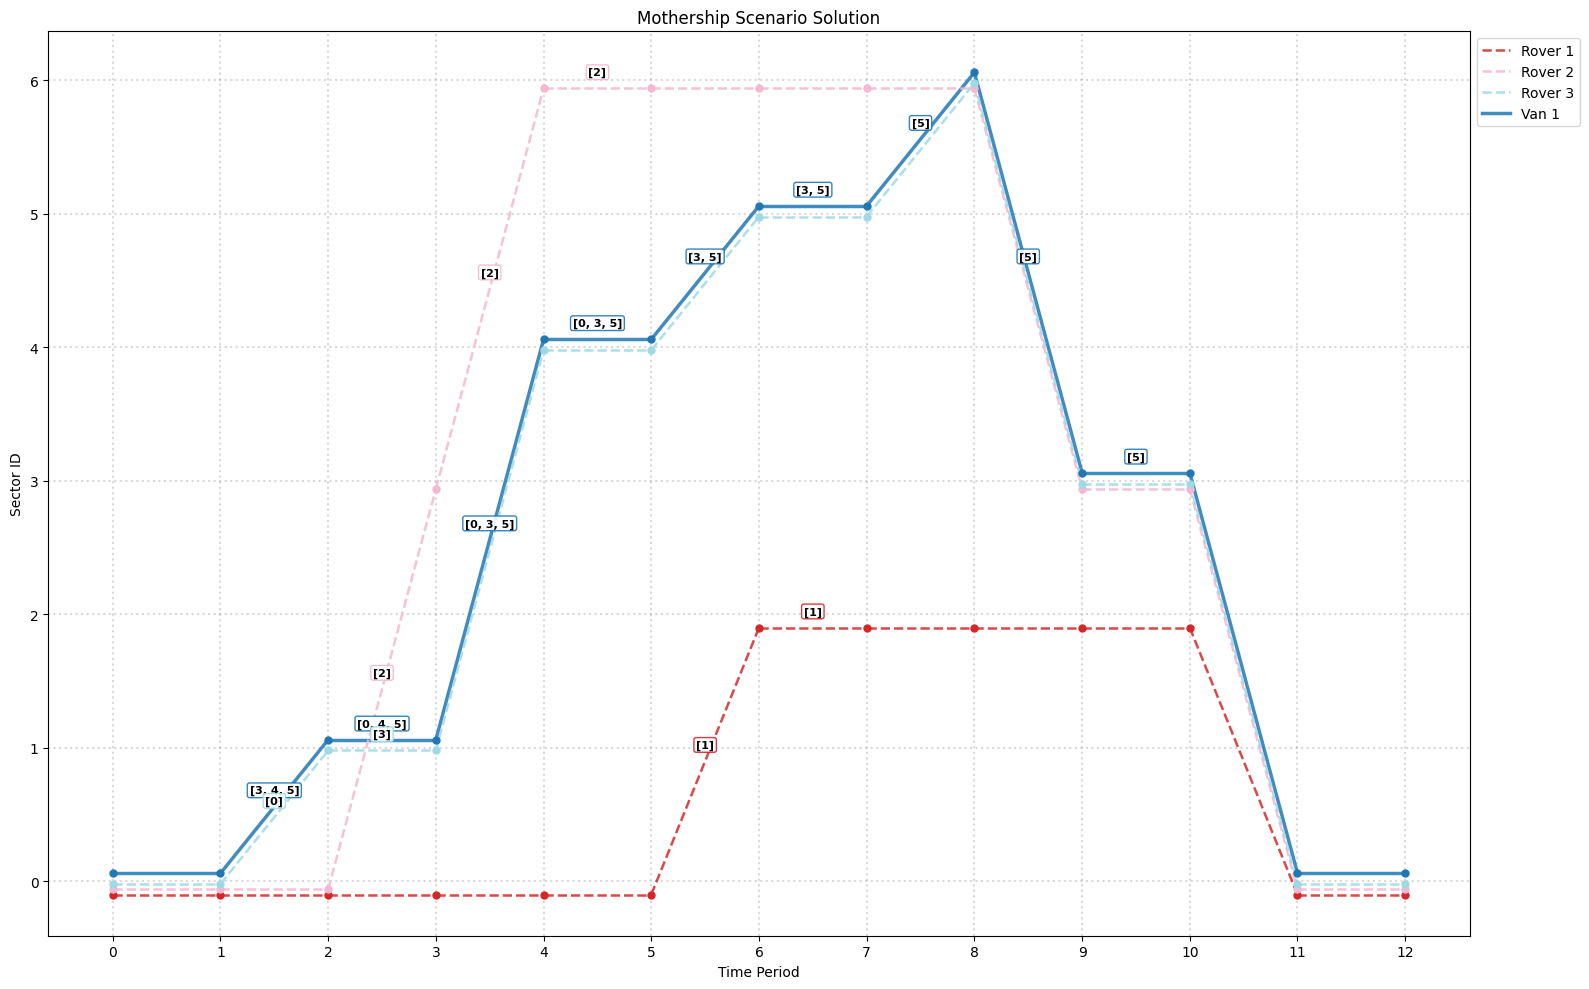

In [25]:
visualize_time_space_solution(model_small, G_small)


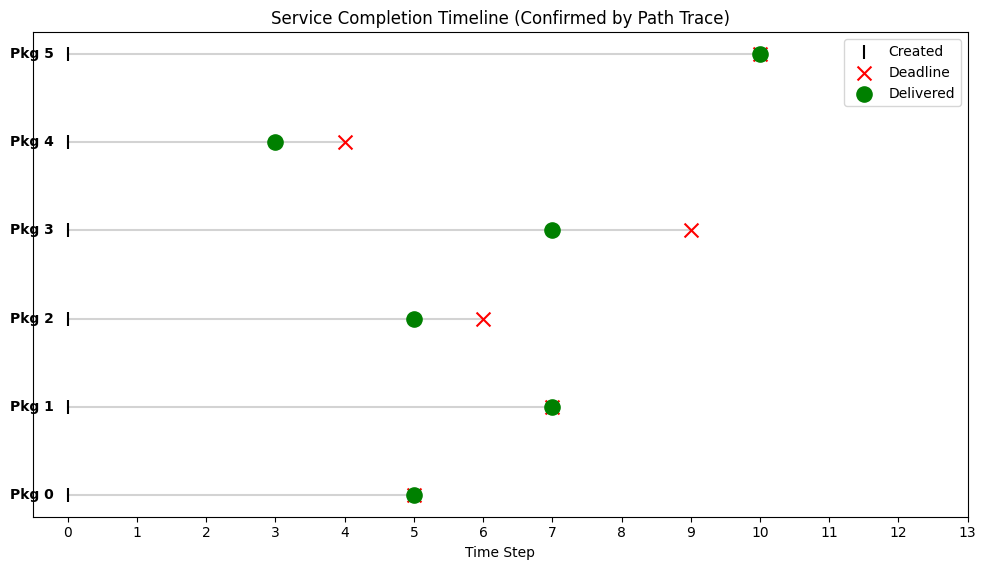

In [26]:
plot_service_timeline(model=model_small, drop_offs=drop_offs_S, hub=hub_S, time_steps=time_steps_S)

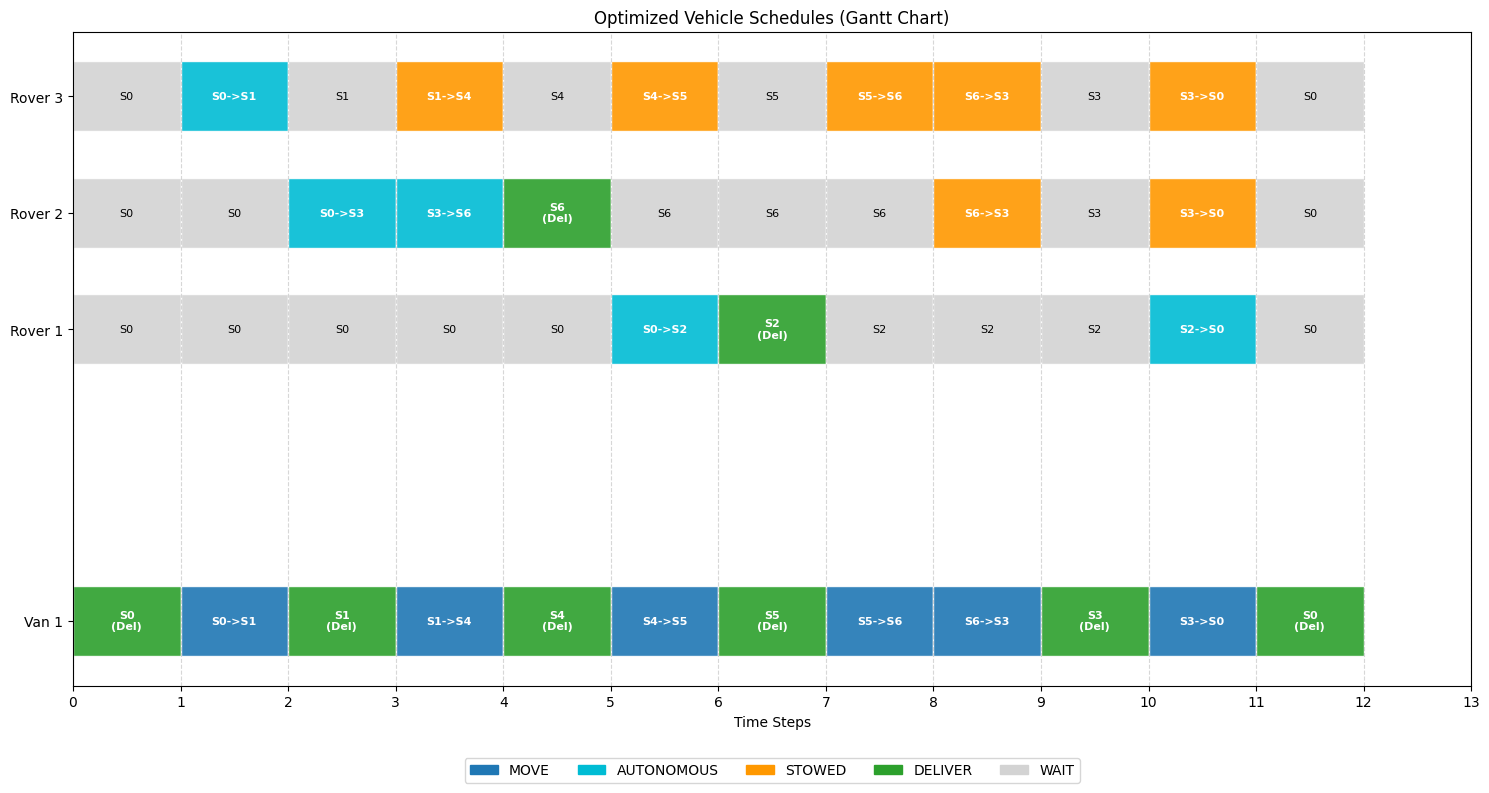

In [27]:
plot_gantt_chart(model=model_small, hub=hub_S, time_steps=time_steps_S)

## 1.5 Results - Medium Instance

In [28]:
# Extracting directly from the data_medium dictionary
sectors_M = data_medium['network']['sectors']
adjacency_M = {int(k): v for k, v in data_medium['network']['adjacency'].items()}
time_steps_M = data_medium['network']['time_steps']
hub_M = data_medium['network']['hub']
drop_offs_M = data_medium['drop_offs']
collections_M = data_medium.get('collections', [])
params_M = data_medium['parameters']

# Graph construction (1 time step shorter initially, so add 1)
time_steps_M = time_steps_M + 1
G_medium = build_time_space_multigraph(sectors_M, adjacency_M, time_steps_M, hub=hub_M)

In [29]:
# Solve model
model_medium = solve_scenario_energy_tracking(
    sectors_M, adjacency_M, time_steps_M, hub_M, drop_offs_M, collections_M, params_M, G_medium
)

if model_medium.SolCount > 0:
    print(f"Objective Value: {model_medium.ObjVal}")
    print(f"Solve Time: {model_medium.Runtime:.2f}s")
    print_detailed_fleet_status(model_medium, drop_offs_M, hub_M, time_steps_M)
else:
    print("No solution found.")
    print(f"Solve Time: {model_medium.Runtime:.2f}s")


Generating x variables with pruning...
Set parameter TimeLimit to value 3600
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  3600
Method  2
Presolve  2
Seed  42

Optimize a model with 11595 rows, 21424 columns and 90098 nonzeros
Model fingerprint: 0x5cd00fd6
Variable types: 0 continuous, 21424 integer (6662 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Presolve removed 5689 rows and 6009 columns
Presolve time: 1.84s
Presolved: 5906 rows, 15415 columns, 55947 nonzeros
Variable types: 0 continuous, 15415 integer (4498 binary)
Root relaxation presolve removed 8 rows and 0 col

## 1.6 Visualization - Medium Instance


DETAILED VAN OPERATIONS REPORT

VAN #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Sector | Battery  | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0      | -        | DELIVERING [] (Van)                 | -                    | 
  1 -> 2       | 0      | -        | Driving -> S1                       | [0, 1, 2, 4]         | Carrying 3 Rover(s)
  2 -> 3       | 1      | -        | Driving -> S7                       | [0, 1, 2, 4]         | Carrying 3 Rover(s)
  3 -> 4       | 7      | -        | DELIVERING [1] (Van)                | [0, 1, 4]            | 
  4 -> 5       | 7      | -        | Driving -> S1                       | -                    | 
  5 -> 6       | 1      | -        | Driving -> S0                       | -                    |

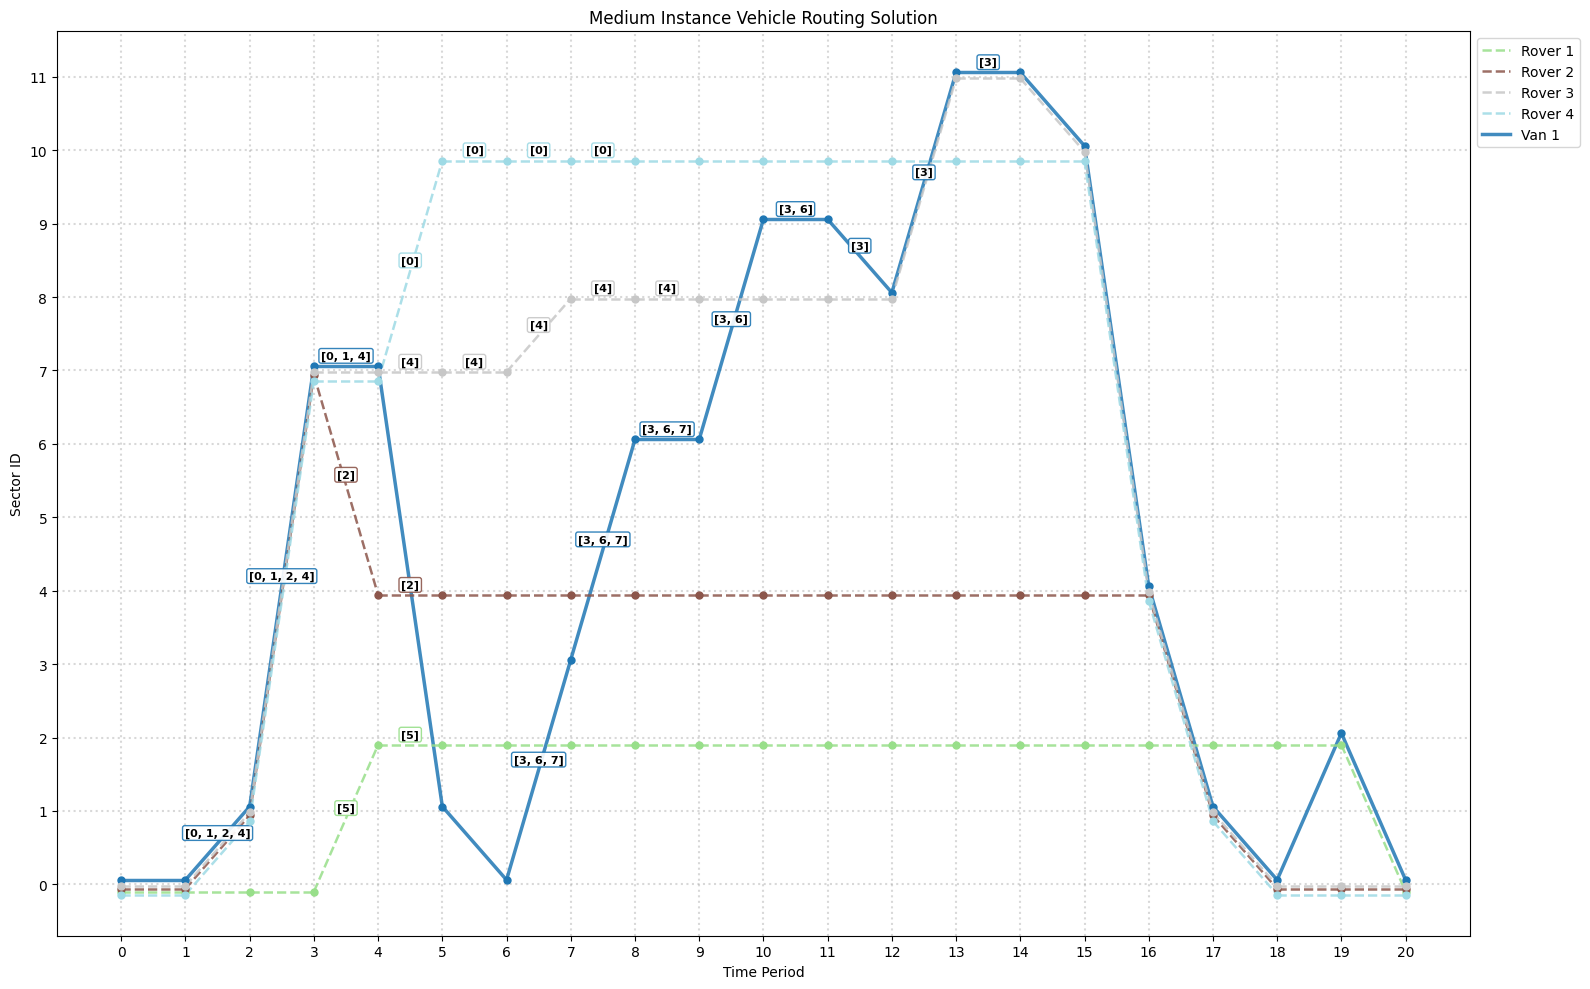

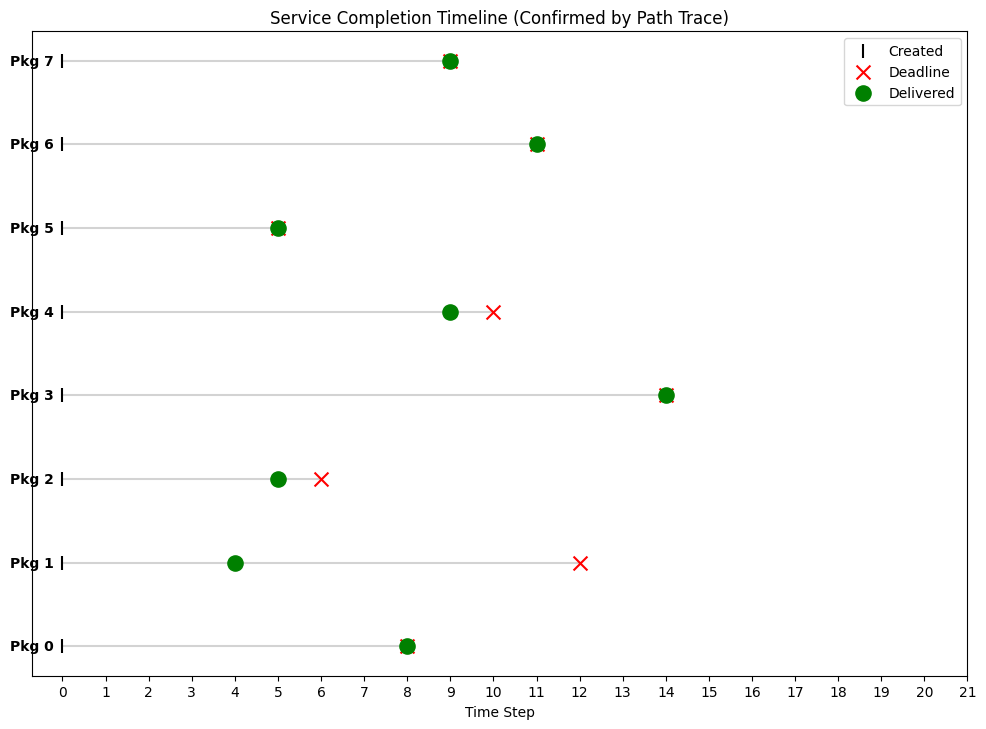

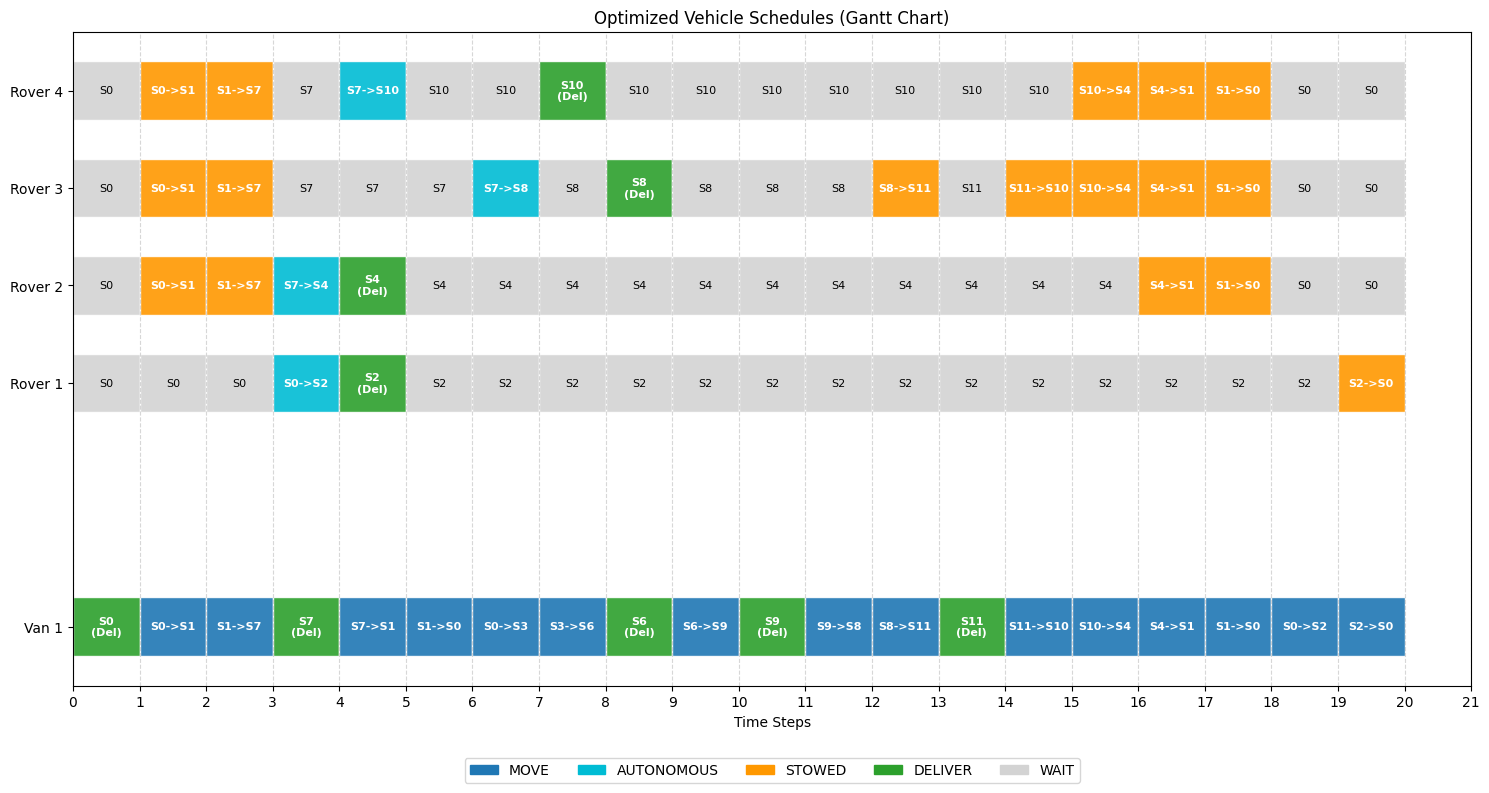

In [61]:
print_detailed_fleet_status(model=model_medium, drop_offs=drop_offs_M, hub=hub_M, time_steps=time_steps_M)
visualize_time_space_solution(model_medium, G_medium, title="Medium Instance Vehicle Routing Solution")
plot_service_timeline(model=model_medium, drop_offs=drop_offs_M, hub=hub_M, time_steps=time_steps_M)
plot_gantt_chart(model=model_medium, hub=hub_M, time_steps=time_steps_M)

---

# Scenario 2: Routing with Recharging - Needs to be reritten for the Rover-Van case

**Objective:** Minimize total arc usage with recharging capability.

**Features:**
- All features from Scenario 1
- **New:** Rovers can recharge energy by riding on Vans
- Energy resets when Rovers boards/alights from Vans
- Track excursion energy separately
- No pickup requests

---

### Mathematical Formulation

#### Sets and Indices
- $\mathcal{Z}$: Set of zones (spatial nodes).
- $\mathcal{T} = \{0, \dots, T_{max}\}$: Set of time periods.
- $\mathcal{N}$: Set of time-space nodes, where $u = (z, t) \in \mathcal{N}$.
- $\mathcal{A}$: The complete set of directed arcs in the time-space graph, where flow moves from $t$ to $t+1$.
    * $\mathcal{A}_{Van} \subseteq \mathcal{A}$: Arcs traversable by Vans.
    * $\mathcal{A}_{Rover} \subseteq \mathcal{A}$: Arcs traversable by Rovers (Flying or Riding).
    * $\mathcal{A}_{Del} \subseteq \mathcal{A}$: Arcs designated for delivery actions.
    * $\mathcal{A}_{Shelf} \subseteq \mathcal{A}$: Virtual arcs at the Depot for package storage.
- $\mathcal{K}$: Set of all parcels (deliveries + pickups).
- $\mathcal{F}$: Set of all fleet types $\{\text{Van}, \text{Rover}, \text{Del\_Van}, \text{Del\_Rv}, \text{Depot\_Shelf}\}$.
- $\mathcal{E} = \{0, \dots, R\}$: Set of discrete energy levels for rovers.
- $Pred(n)$: Set of Predecessor nodes (incoming arcs to $n$).
- $Succ(n)$: Set of Successor nodes (outgoing arcs from $n$).

#### Parameters
- $C_{fix}^{van}$: Fixed cost for using a van.
- $C_{move}^{van}$: Cost per arc for a van moving between different zones.
- $C_{wait}^{van}$: Cost per arc for a van waiting in the same zone.
- $C_{energy}^{rover}$: Cost per unit of energy consumed by a rover.
- $E_{move}, E_{del}$: Energy consumption for moving and delivering.
- $R$: Maximum energy capacity of a rover.

#### Decision Variables
- $x_{ij}^{k,f} \in \{0, 1\}$: Binary variable. 1 if parcel $k$ traverses arc $(i,j)$ using fleet $f$.
- $y_{ij}^{f} \in \mathbb{Z}_{\geq 0}$: Integer variable. Number of vehicles of fleet type $f$ traversing arc $(i,j)$.
- $z_{ij, e}^{fly} \in \mathbb{Z}_{\geq 0}$: Number of rovers flying (moving under own power) on arc $(i,j)$ arriving with energy level $e$ (Waiting is included).
- $z_{ij, e}^{del} \in \mathbb{Z}_{\geq 0}$: Number of rovers performing a delivery action on arc $(i,j)$ ending with energy level $e$.
- $z_{ij, e}^{ride} \in \mathbb{Z}_{\geq 0}$: Number of rovers riding a van on arc $(i,j)$ ending with energy level $e$.

#### Objective Function
Minimize the total cost, comprising variable van costs, rover energy costs, and fixed van costs:

$$
\begin{aligned}
\text{Minimize } Z = \quad & \sum_{(i,j) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{van}} y_{ij}^f \cdot C_{ij}^{van} \quad && \text{(Van Variable Cost)} \\
+ & \sum_{(i,j) \in \mathcal{A}} \sum_{e \in \mathcal{E}} C_{energy}^{rover} \left( z_{ij,e}^{fly} \cdot E_{move} + z_{ij,e}^{del} \cdot E_{del} \right) \quad && \text{(Rover Energy Cost)} \\
+ & \sum_{j \in \mathcal{N}} y_{(depot, 0), j}^{Van} \cdot C_{fix}^{van} \quad && \text{(Van Fixed Cost)}
\end{aligned}
$$

Where the van arc cost $C_{ij}^{van}$ is defined as:
$$
C_{ij}^{van} = 
\begin{cases} 
C_{move}^{van} & \text{if } i_{zone} \neq j_{zone} \\
C_{wait}^{van} & \text{if } i_{zone} = j_{zone}
\end{cases}
$$

### Constraints

#### 1. Flow Conservation
This ensures the parcel moves through the network continuously.
- **Source:** The parcel is generated at the **Depot** at $t=0$ (Net flow = 1).
- **Intermediate:** Flow entering a node must equal flow leaving it (Net flow = 0).
- **Sink (Implicit):** If a parcel takes a **Delivery Arc**, it leaves the current node but is **not** added to the inflow of the next node (effectively exiting the network).

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \notin \mathcal{F}_{del}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (\text{Depot}, 0) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}
$$

> **Note:** The second term (Inflow) explicitly **excludes** delivery fleets ($f \notin \mathcal{F}_{del}$).

#### 2. Force Service (Deadline Satisfaction)
This constraint ensures that for every parcel $k$, exactly one "Delivery" action occurs at the target zone $z_{target}$ on or before the due time $T_{due}$.

$$
\sum_{t=1}^{T_{due}} \sum_{f \in \{\text{Del\_Rv}, \text{Del\_Van}\}} x_{(z_{target}, t-1), (z_{target}, t)}^{k,f} = 1 \quad \forall k \in \mathcal{K}
$$

### Why Delivery Timing is exactly after the package enters a "delivery" vehicle

**1. Delivery is a Movement, Not a Status**
The variable $x_{t, t+1}^{del}$ represents the specific action of moving from the network into the delivery state. It is not a checkmark; it is a flow variable.

**2. The Chain of Custody**
For a delivery to occur at a later time $t+k$, the variable $x_{t+k, t+k+1}^{del}$ must be set to 1.
However, flow constraints dictate that a variable can only be 1 if there is **input flow** at node $t+k$ (i.e., the package is present).

**3. The Impossibility of Delay**
If the package exits the network at time $t$ (via $x_{t, t+1}^{del}=1$):
- **Flow Termination:** The package is removed from the system. The flow at all subsequent nodes ($t+1, t+2, \dots$) becomes 0.
- **Broken Chain:** Since flow at $t+k$ is 0, the variable $x_{t+k, t+k+1}^{del}$ is forced to 0.

**Conclusion:**
You cannot deliver what you do not have. Once the package exits, it is gone. Therefore, the "Force Service" credit ($\sum x = 1$) is always awarded at the exact instant the exit occurs.

### 3 Asset Balance & Global Fleet Limits

These constraints manage the available fleet size at the depot ($t=0$) and ensure vehicles are conserved (flow in = flow out) throughout the timeline.

#### 3.1. Global Van Limit (at $t=0$)
The total number of vans (both moving and delivering types) leaving the depot at time 0 cannot exceed the available fleet size $N_{van}$.

$$
\sum_{(v) \in \text{neighbors}(\text{Depot},0)} \sum_{f \in \{\text{Van}, \text{Del\_Van}\}} y_{(\text{Depot},0), v}^{f} \leq N_{van}
$$

#### 3.2. Global Rover Limit & Initial Energy (at $t=0$)
The total number of rovers (flying, riding, or delivering) leaving the depot at time 0 cannot exceed $N_{rover}$. Furthermore, all rovers leaving the depot must start with full energy capacity ($e=R$). Later FFC for rovers done via the Energy level constraint.

**Limit Constraint:**
$$
\sum_{(v) \in \text{neighbors}(\text{Depot},0)} \sum_{e=0}^{R} \left( z_{(\text{Depot},0), v, e}^{fly} + z_{(\text{Depot},0), v, e}^{ride} + z_{(\text{Depot},0), v, e}^{del} \right) \leq N_{rover}
$$

**Full Energy Enforcement. Rovers with lower energy are not allowed at t=0:**
$$
z_{(\text{Depot},0), v, e}^{\{fly, ride, del\}} = 0 \quad \forall e < R
$$

#### 3.3. Van Asset Balance (Flow Conservation)
For all intermediate time-space nodes ($0 < t < T_{max}$), the number of vans arriving must equal the number of vans departing.

$$
\sum_{(u, n) \in \mathcal{A}} \sum_{f \in \{\text{Van}, \text{Del\_Van}\}} y_{u, n}^{f} = \sum_{(n, v) \in \mathcal{A}} \sum_{f \in \{\text{Van}, \text{Del\_Van}\}} y_{n, v}^{f} \quad \forall n = (z, t) \text{ where } 0 < t < T_{max}
$$

### 4. Capacity Constraints

We ensure that the number of parcels assigned to a specific fleet type $f$ on arc $(u,v)$ does not exceed the capacity of the active vehicles of that type.

#### Case 4.1: Flying Rovers ($f = \text{"Rover"}$)
For rovers moving autonomously(flying or waiting), the capacity is provided by the sum of all flying rovers across valid energy levels. Riding does not provide capcity on the arc for rovers. Those packages get reassinged to the van.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, \text{Rover}} \leq Q_{\text{Rover}} \cdot \left( \sum_{e=0}^{R} z_{u, v, e}^{fly} \right) \quad \forall (u, v) \in \mathcal{A}
$$

#### Case 4.2: Vans, Delivery Fleets, and Shelf ($f \neq \text{"Rover"}$)
For all other fleet types (Vans, Delivery actions, and the Virtual Shelf), the capacity is linked to the generic flow variable $y$.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, f} \leq Q_{f} \cdot y_{u, v}^{f} \quad \forall (u, v) \in \mathcal{A}, \forall f \in \{\text{Van}, \text{Del\_Van}, \text{Del\_Rv}, \text{Shelf}\}
$$

**Where:**
- $Q_f$: The capacity parameter (`cap_per_fleet`) for fleet $f$.

### 5. Coupling & Mothership Constraints

These constraints ensure consistency between the detailed energy states ($z$) and the aggregate fleet flows ($y$), and enforce the physical limits of vans carrying rovers.

#### 5.1. Mothership Constraint (Capacity)
If rovers are riding, they must be carried by a van. The total number of riding rovers cannot exceed the specific rover-carrying capacity of the vans traversing that arc.
*Note: Both standard "Vans" and "Delivery Vans" can carry rovers.*

$$
\sum_{e=0}^{R} z_{u, v, e}^{ride} \leq C_{van}^{rover} \cdot \left( y_{u, v}^{\text{Van}} + y_{u, v}^{\text{Del\_Van}} \right) \quad \forall (u, v) \in \mathcal{A}_{\text{Rover}}
$$

#### 5.2. Rover Delivery Coupling
For arcs representing a delivery action, the aggregate delivery flow ($y^{\text{Del\_Rv}}$) must equal the sum of rovers performing the delivery across valid energy levels. This still exists from previous itterations, where I used it. Currently everything is done via the "z"-variable, but I haven't changed the code, so I keep it for completeleness

$$
\sum_{e=0}^{R} z_{u, v, e}^{del} = y_{u, v}^{\text{Del\_Rv}} \quad \forall (u, v) \in \mathcal{A}_{\text{Del\_Rv}}
$$

**Where:**
- $C_{van}^{rover}$: Parameter `Cap_V_Rover` (Max rovers a single van can carry).
- $\mathcal{A}_{\text{Rover}}$: Set of arcs where rover movement is allowed.
- $\mathcal{A}_{\text{Del\_Rv}}$: Set of arcs where rover delivery is allowed.

### 6. Energy Balance (Recharge on Ride)

This constraint ensures flow conservation for rovers at every energy level $e$. It uses a **Backtracking Logic**: standing at the arrival node $n$, it pulls flow from all valid predecessors $p$.

**Constraint Logic:**
$$
\underbrace{ \sum_{p} z_{p, n, (e + C_{fly})}^{fly} }_{\text{Inflow: Flying}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + C_{del})}^{del} }_{\text{Inflow: Delivery}} 
+ \underbrace{ \delta_{e,R} \cdot \left( \sum_{p} \sum_{k=0}^{R} z_{p, n, k}^{ride} \right) }_{\text{Inflow: Recharging Riders}} 
\quad = \quad
\underbrace{ \sum_{v} \left( z_{n, v, e}^{fly} + z_{n, v, e}^{ride} + z_{n, v, e}^{del} \right) }_{\text{Total Outflow}}
$$

**Where:**
- $\delta_{e,R}$:. It acts as a switch ($1$ if $e=R$, else $0$). This ensures riders only "re-appear" at the Full Energy level.
- **Backtracking Logic:** The constraint looks backwards. To arrive at energy $e$, a rover must have come from a higher energy level $(e+Cost)$ via flying, **OR** (if $e=R$) it could have come from *any* energy level via a van ride.
- **Linearity (Energy State Routing):** The recharge process is modeled strictly as **flow routing** through a multi-layered graph, rather than as a non-linear algebraic calculation.
    * **Visualizing Energy Levels:** Imagine the network as having a "vertical" dimension, where different layers represent discrete **Energy States** (e.g., from $E_{0}$ to $E_{max}$).
    * **Movement Between Levels:** A "Ride" or "Recharge" arc acts like an elevator; it does not just move the vehicle horizontally in space and time, but specifically directs the flow to the **"Full Energy" node** (level $E_{max}$) at the destination.
    * **Mathematical Implication:** Because the change in energy state is encoded in the graph's structure (the arc's destination) rather than a formula, we avoid complex non-linear constraints. The solver simply sums the flows arriving at the "Full" level.

### 7. Strong Linking & Valid Inequalities (Cuts)

This constraint ensures that a parcel $k$ cannot be assigned to a van fleet on arc $(u,v)$ unless a van is actually traversing that arc.
*It links the binary decision $x$ to the integer decision $y$.*

$$
x_{u, v}^{k, f} \leq \sum_{f' \in \{\text{Van}, \text{Del\_Van}\}} y_{u, v}^{f'} \quad \forall (u,v) \in \mathcal{A}, \forall k \in \mathcal{K}, \forall f \in \{\text{Van}, \text{Del\_Van}\}
$$

## 2.2 Implementation

Implement Scenario 2 model in the cell below.

In [31]:
# TODO: Implement Scenario 2 model
import gurobipy as gp
from gurobipy import GRB
import networkx as nx

def solve_scenario_energy_recharge(sectors, adjacency, time_periods, hub, drop_offs, collections, params, G):
    """
    Solves Scenario 1 with:
    - Fixed Rover Energy Range (R).
    - Mothership logic.
    - STATIONARY VIRTUAL VEHICLE: 'Hub_Shelf' allows packages to stay at hub.
    """

    # --- 1. Parameters ---
    R = params['battery_limit']
    Cap_V_Rover = params['van_bay_limit']
    E_cost_move = 1
    E_cost_deliver = 1
    E_cost_wait = 0 
    
    # Capacity of virtual vehicle equals total possible parcels
    total_potential_parcels = len(drop_offs) + len(collections)
    
    cap_per_fleet = {
        "Van": params['van_package_capacity'],
        "Deliver_Van": params['van_package_capacity'],
        "Rover": params['rover_package_capacity'],
        "Deliver_Rover": params['rover_package_capacity'],
        "Hub_Shelf": total_potential_parcels # Virtual Vehicle Capacity
    }
    
    fleet_limits = {"Van": params['num_vans'], "Rover": params['num_rovers']}
    
    # --- 2. Graph Pre-processing ---
    arcs_config = {} 
    for u, v, data in G.edges(data=True):
        if (u, v) not in arcs_config: arcs_config[(u, v)] = set()
        a_type = data.get('arc_type')
        
        if a_type == "Van":
            arcs_config[(u, v)].add("Van")
        elif a_type == "Rover":
            arcs_config[(u, v)].add("Rover")
        elif a_type == "Deliver": 
            arcs_config[(u, v)].add("Deliver_Rover")
            arcs_config[(u, v)].add("Deliver_Van")

    # --- NEW: Add Virtual Vehicle Arcs (Waiting at Hub only) ---
    for t in range(time_periods - 1):
        u_hub = (int(hub), t)
        v_hub = (int(hub), t + 1)
        if (u_hub, v_hub) not in arcs_config: 
            arcs_config[(u_hub, v_hub)] = set()
        arcs_config[(u_hub, v_hub)].add("Hub_Shelf")

    unique_arcs = list(arcs_config.keys())
    
    model = gp.Model("Scenario_1_Virtual_Vehicle")

    # --- 3. Decision Variables ---
    spatial_graph = nx.DiGraph()
    for (u, v) in arcs_config.keys():
        spatial_graph.add_edge(u[0], v[0], weight=1 if u[0] != v[0] else 0)
        
    try:
        min_time_dist = dict(nx.all_pairs_dijkstra_path_length(spatial_graph))
    except:
        min_time_dist = {}

    print("Generating x variables with pruning...")
    x = {}
    skipped_vars = 0
    
    # Package release time is 1, but they can exist on the shelf at t=0
    GLOBAL_START_TIME = 1 

    for d in drop_offs:
        k, target_sector, deadline = d['id'], d['sector'], d['deadline']
        start_sector = int(hub)
        
        for (u, v), allowed in arcs_config.items():
            cur_s, cur_t = u
            next_s, next_t = v
            
            # Pruning Check: If it's the shelf, it can exist at T=0
            if "Hub_Shelf" not in allowed and cur_t < GLOBAL_START_TIME:
                skipped_vars += 1
                continue

            # --- PRUNING CHECK 1: DEADLINE ---
            time_remaining = deadline - next_t
            req_time = min_time_dist.get(next_s, {}).get(target_sector, 9999) 
            if req_time > time_remaining:
                skipped_vars += 1
                continue 
            
            # --- PRUNING CHECK 2: START ---
            dist_from_start = min_time_dist.get(start_sector, {}).get(cur_s, 9999)
            time_elapsed = cur_t - 0 # Use 0 because of the shelf
            if dist_from_start > time_elapsed:
                skipped_vars += 1
                continue 
            
            for f in allowed:
                x[k, u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_{k}_{u}_{v}_{f}")

    # y: Fleet Flow
    y = {}
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            y[f, u, v] = model.addVar(vtype=GRB.INTEGER, lb=0.0, name=f"y_{f}_{u}_{v}")
            # --- FORCE VIRTUAL VEHICLE FLOW ---
            if f == "Hub_Shelf":
                model.addConstr(y[f, u, v] == 1, name=f"Shelf_Active_{u[1]}")
            
    # z: Energy State (Rovers Only)
    z_fly, z_ride, z_deliver = {}, {}, {}
    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            # Important: Rovers can wait at hub or move
            dist_cost = E_cost_wait if u[0] == v[0] else E_cost_move
            for e in range(R + 1):
                # Only create z_fly if the rover has enough energy to traverse the arc
                if e >= dist_cost: 
                    z_fly[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_fly_{u}_{v}_{e}")
                
                # z_ride costs 0 energy, so it can always exist for any energy level e
                z_ride[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_ride_{u}_{v}_{e}")
        
        if "Deliver_Rover" in allowed:
            for e in range(R + 1):
                if e >= E_cost_deliver: 
                    z_deliver[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_del_{u}_{v}_{e}")

    model.update()

    # --- 4. Objective Function ---
    cost_van_fixed = float(params.get('van_fixed_cost', 0))
    cost_van_move = float(params.get('van_movement_cost', 0))
    cost_van_wait = float(params.get('van_waiting_cost', 0))
    cost_rover_energy = float(params.get('rover_energy_cost', 0))

    obj_van_var = gp.quicksum(y[f, u, v] * (cost_van_move if u[0] != v[0] else cost_van_wait) 
                               for (f, u, v) in y if "Van" in f)
    
    obj_rover_var = gp.quicksum(cost_rover_energy * z_fly[u, v, e] * E_cost_move for (u, v, e) in z_fly if u[0] != v[0]) + \
                    gp.quicksum(cost_rover_energy * z_deliver[u, v, e] * E_cost_deliver for (u, v, e) in z_deliver)

    start_arcs_van = [y[f, u, v] for (f, u, v) in y if "Van" in f and u == (int(hub), 0)]
    obj_van_fixed = gp.quicksum(cost_van_fixed * v for v in start_arcs_van)

    model.setObjective(obj_van_var + obj_rover_var + obj_van_fixed, GRB.MINIMIZE)

    # --- 6. Constraints ---

    # 1. Flow Conservation (Origin is Hub at Time 0)
    for d in drop_offs:
        k, dest_sector = d['id'], d['sector']
        origin = (int(hub), 0) # Now starting from T=0
        for node in G.nodes():
            f_in = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if v == node for f in arcs_config[u, v] 
                               if (k, u, v, f) in x and (("Deliver" not in f) or (dest_sector != u[0])))
            f_out = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if u == node for f in arcs_config[u, v] if (k, u, v, f) in x)
            
            if node == origin:
                model.addConstr(f_out - f_in == 1, name=f"Origin_{k}")
            else:
                model.addConstr(f_out - f_in == 0, name=f"Cons_{k}_{node}")

    # --- 6.2 Asset Balance & Global Fleet Limits ---
    for node in G.nodes():
        node_s, node_t = node
        
        # 1. VAN FLEET LIMIT
        if node_s == hub and node_t == 0:
            van_types = ["Van", "Deliver_Van"]
            v_start = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in van_types if (f, u, v) in y]
            if v_start:
                model.addConstr(gp.quicksum(v_start) <= fleet_limits["Van"], name="Global_Van_Limit")
        
        # 2. ROVER FLEET LIMIT (STRICT: Includes Deliveries and forces Energy = R)
        if node_s == hub and node_t == 0:
            r_start = []
            # Count every rover leaving (Hub, 0)
            r_start += [z_fly[u, v, e] for (u, v, e) in z_fly if u == node]
            r_start += [z_ride[u, v, e] for (u, v, e) in z_ride if u == node]
            r_start += [z_deliver[u, v, e] for (u, v, e) in z_deliver if u == node]
            
            if r_start:
                model.addConstr(gp.quicksum(r_start) <= fleet_limits["Rover"], name="Global_Rover_Limit")
                
            # OPTIONAL: Force rovers to start with Full Energy (R)
            # This prevents them from starting at energy 4 if R=5.
            r_low_energy = [z_fly[u,v,e] for (u,v,e) in z_fly if u==node and e < R] + \
                           [z_ride[u,v,e] for (u,v,e) in z_ride if u==node and e < R] + \
                           [z_deliver[u,v,e] for (u,v,e) in z_deliver if u==node and e < R]
            for var in r_low_energy:
                model.addConstr(var == 0, name=f"Force_Full_Energy_{var.VarName}")

        # 3. VAN ASSET BALANCE (Flow Conservation)
        # Balancing vans for all intermediate time steps (0 < t < T-1)
        if node_t > 0 and node_t < time_periods - 1:
            van_types = ["Van", "Deliver_Van"]
            v_in  = [y[f, u, v] for (u, v) in unique_arcs if v == node for f in van_types if (f, u, v) in y]
            v_out = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in van_types if (f, u, v) in y]
            if v_in or v_out:
                model.addConstr(gp.quicksum(v_out) == gp.quicksum(v_in), name=f"Van_Flow_Balance_{node}")

    # 3. Capacity
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            cap = cap_per_fleet[f]
            pkgs = gp.quicksum(x[d['id'], u, v, f] for d in drop_offs if (d['id'], u, v, f) in x)
            if f == "Rover":
                active = gp.quicksum(z_fly[u, v, e] for e in range(R+1) if (u, v, e) in z_fly)
                model.addConstr(pkgs <= cap * active, name=f"Cap_{u}_{v}_{f}")
            else:
                model.addConstr(pkgs <= cap * y[f, u, v], name=f"Cap_{u}_{v}_{f}")

    # 4. Force Service
    for d in drop_offs:
        k, z_tgt, t_due = d['id'], d['sector'], d['deadline']
        valid_v = [x[k, (z_tgt, t-1), (z_tgt, t), f] for t in range(1, t_due + 1) 
                   for f in ["Deliver_Rover", "Deliver_Van"] if (k, (z_tgt, t-1), (z_tgt, t), f) in x]
        if valid_v: model.addConstr(gp.quicksum(valid_v) == 1, name=f"MustDel_{k}")

    # 5. Coupling & 6. Mothership
    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            # Safely sum only existing keys
            fly_sum = gp.quicksum(z_fly[u, v, e] for e in range(R + 1) if (u, v, e) in z_fly)
            ride_sum = gp.quicksum(z_ride[u, v, e] for e in range(R + 1) if (u, v, e) in z_ride)
            
            model.addConstr(fly_sum + ride_sum == y["Rover", u, v], name=f"Rover_Coupling_{u}_{v}")
            
            # Mothership logic: riders must be <= capacity of actual vans on this arc
            v_flow = gp.quicksum(y[f, u, v] for f in ["Van", "Deliver_Van"] if (f, u, v) in y)
            model.addConstr(ride_sum <= Cap_V_Rover * v_flow, name=f"Mothership_{u}_{v}")

        if "Deliver_Rover" in allowed:
            del_sum = gp.quicksum(z_deliver[u, v, e] for e in range(R + 1) if (u, v, e) in z_deliver)
            model.addConstr(del_sum == y["Deliver_Rover", u, v], name=f"DelRover_Coupling_{u}_{v}")

    # --- 7. Energy Balance (Recharge on Ride - Robust) ---
    for node in G.nodes():
        node_s, node_t = node
        
        # Skip absolute start and end
        if node_t == 0 or node_t == time_periods - 1:
            continue
            
        # 1. Collect Inflows by Source Type
        # A. From Field (Flying/Delivering) -> Maintains energy level 'e' (minus cost)
        # B. From Van (Riding) -> ALWAYS arrives at Energy R (Full Charge)
        
        inflow_from_van = []
        # Check for rovers arriving via van from previous time step
        for p in G.predecessors(node):
            if (p, node) not in arcs_config: continue
            if "Rover" in arcs_config[(p, node)]:
                # Sum over ALL possible energy levels they had when they boarded
                for e_prev in range(R + 1):
                    if (p, node, e_prev) in z_ride:
                        inflow_from_van.append(z_ride[p, node, e_prev])

        for e in range(R + 1):
            v_in = []
            
            # --- Field Inflow ---
            for p in G.predecessors(node):
                if (p, node) not in arcs_config: continue
                al = arcs_config[(p, node)]
                
                # Case A: Flying/Waiting (e_in = e_out + cost)
                cost_move = E_cost_wait if p[0] == node[0] else E_cost_move
                if "Rover" in al and (e + cost_move) <= R:
                    if (p, node, e + cost_move) in z_fly:
                        v_in.append(z_fly[p, node, e + cost_move])
                
                # Case B: Delivering (e_in = e_out + cost)
                if "Deliver_Rover" in al and (e + E_cost_deliver) <= R:
                    if (p, node, e + E_cost_deliver) in z_deliver:
                        v_in.append(z_deliver[p, node, e + E_cost_deliver])

            # --- Van Inflow (Recharge Logic) ---
            # If we are at the FULL ENERGY level (e == R), we add the van arrivals here.
            if e == R:
                v_in.extend(inflow_from_van)

            # --- Outflow ---
            v_out = []
            for n in G.neighbors(node):
                if (node, n, e) in z_fly: v_out.append(z_fly[node, n, e])
                if (node, n, e) in z_deliver: v_out.append(z_deliver[node, n, e])
                
                # IMPORTANT: Rovers leaving via VAN (Ride)
                # They leave from the CURRENT energy level 'e' 
                # (and will appear at 'R' at the next node due to the logic above)
                if (node, n, e) in z_ride: v_out.append(z_ride[node, n, e])

            # --- Constraint ---
            if v_in or v_out:
                model.addConstr(gp.quicksum(v_in) == gp.quicksum(v_out), name=f"EnergyBal_{node}_E{e}")

    # --- 8. Strong Linking & Cuts ---
    for (u, v), allowed in arcs_config.items():
        v_vars = [y[f, u, v] for f in ["Van", "Deliver_Van"] if (f, u, v) in y]
        if v_vars:
            total_v = gp.quicksum(v_vars)
            for d in drop_offs:
                for f in ["Van", "Deliver_Van"]:
                    if (d['id'], u, v, f) in x: model.addConstr(x[d['id'], u, v, f] <= total_v)


    # Global Work Cut
    total_km = sum(min_time_dist.get(int(hub), {}).get(d['sector'], 0) for d in drop_offs)
    v_cap_prov = gp.quicksum(cap_per_fleet["Van"] * y[f,u,v] for (f,u,v) in y if "Van" in f and u[0]!=v[0])
    r_cap_prov = gp.quicksum(cap_per_fleet["Rover"] * z_fly[u,v,e] for (u,v,e) in z_fly if u[0]!=v[0])
    model.addConstr(v_cap_prov + r_cap_prov >= total_km, name="Global_Work_Cut")

    # Destination Inflow Cuts
    pkg_sectors = {}
    for d in drop_offs: pkg_sectors[d['sector']] = pkg_sectors.get(d['sector'], 0) + 1
    for s_dest, count in pkg_sectors.items():
        in_cap = gp.quicksum(cap_per_fleet["Van"]*y[f,u,v] for (f,u,v) in y if "Van" in f and v[0]==s_dest and u[0]!=s_dest) + \
                 gp.quicksum(cap_per_fleet["Rover"]*z_fly[u,v,e] for (u,v,e) in z_fly if v[0]==s_dest and u[0]!=s_dest) + \
                 gp.quicksum(cap_per_fleet["Deliver_Rover"]*y["Deliver_Rover",u,v] for (u,v),al in arcs_config.items() if v[0]==s_dest and u[0]!=s_dest and "Deliver_Rover" in al)
        model.addConstr(in_cap >= count, name=f"Inflow_Cut_{s_dest}")


    time=  3600*3   # 60 minutes
    model.Params.TimeLimit = time
    model.Params.Method = 2
    model.Params.Presolve = 2
    model.optimize()
    return model

## 2.3 Results - Small Instance

In [32]:
# Just run this once to be 100% sure
# verify_graph_structure(G_small, hub=hub_S, time_steps=time_steps_S)

model_small_recharge = solve_scenario_energy_recharge(
    sectors_S, adjacency_S, time_steps_S, hub_S, drop_offs_S, collections_S, params_S, G_small
)

if model_small.SolCount > 0:
    print(f"Objective Value: {model_small.ObjVal}")
else:
    print("No solution found.")
print(f"Solve Time: {model_small.Runtime:.2f}s")

Generating x variables with pruning...
Set parameter TimeLimit to value 10800
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  10800
Method  2
Presolve  2
Seed  42

Optimize a model with 3183 rows, 5161 columns and 21531 nonzeros
Model fingerprint: 0x380f9b94
Variable types: 0 continuous, 5161 integer (1718 binary)
Coefficient statistics:
  Matrix range     [1e+00, 9e+00]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+00]
Presolve removed 1604 rows and 1615 columns
Presolve time: 0.32s
Presolved: 1579 rows, 3546 columns, 13008 nonzeros
Variable types: 0 continuous, 3546 integer (964 binary)
Root relaxation presolve removed 6 rows and 0 columns

## 2.4 Visualization - Small Instance

In [33]:
# TODO: Create visualization showing excursions and recharging events
print_detailed_fleet_status(model_small_recharge, drop_offs_S, hub_S, time_steps_S)


DETAILED VAN OPERATIONS REPORT

VAN #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Sector | Battery  | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0      | -        | DELIVERING [] (Van)                 | -                    | 
  1 -> 2       | 0      | -        | Driving -> S1                       | [0, 3, 4]            | 
  2 -> 3       | 1      | -        | DELIVERING [4] (Van)                | [0, 3, 4]            | 
  3 -> 4       | 1      | -        | Driving -> S4                       | [0, 3, 5]            | Carrying 1 Rover(s)
  4 -> 5       | 4      | -        | DELIVERING [0] (Van)                | [0, 3]               | 
  5 -> 6       | 4      | -        | Driving -> S5                       | [3, 5]               | Carrying 1 Rover(s

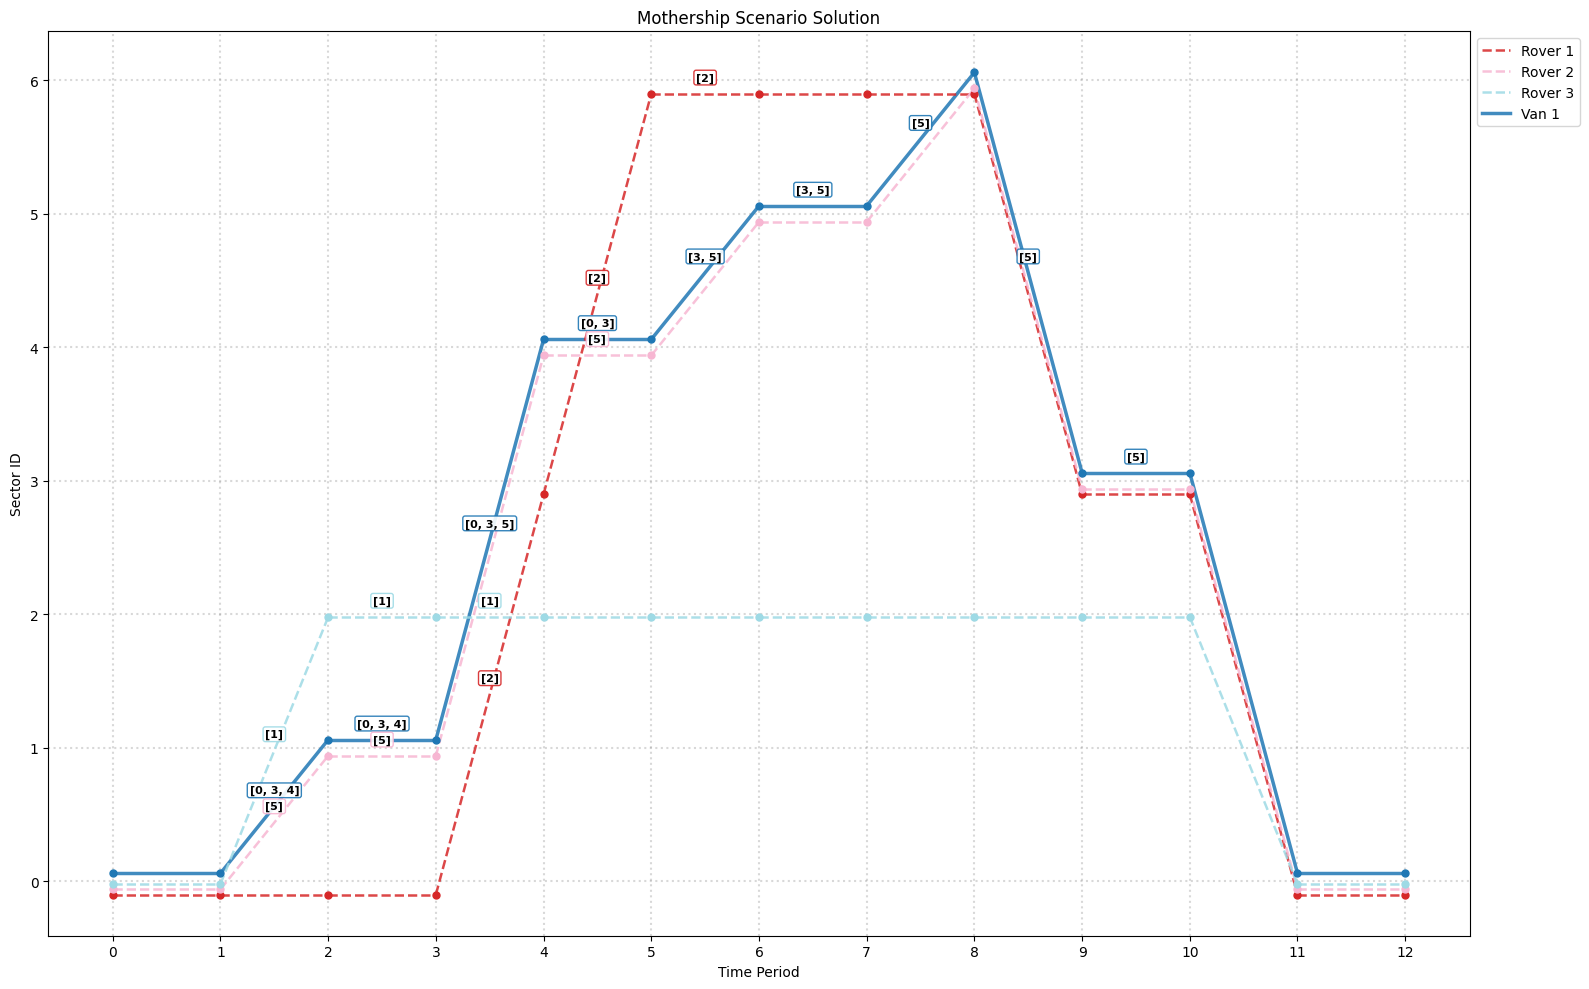

In [34]:
visualize_time_space_solution(model_small_recharge, G_small)

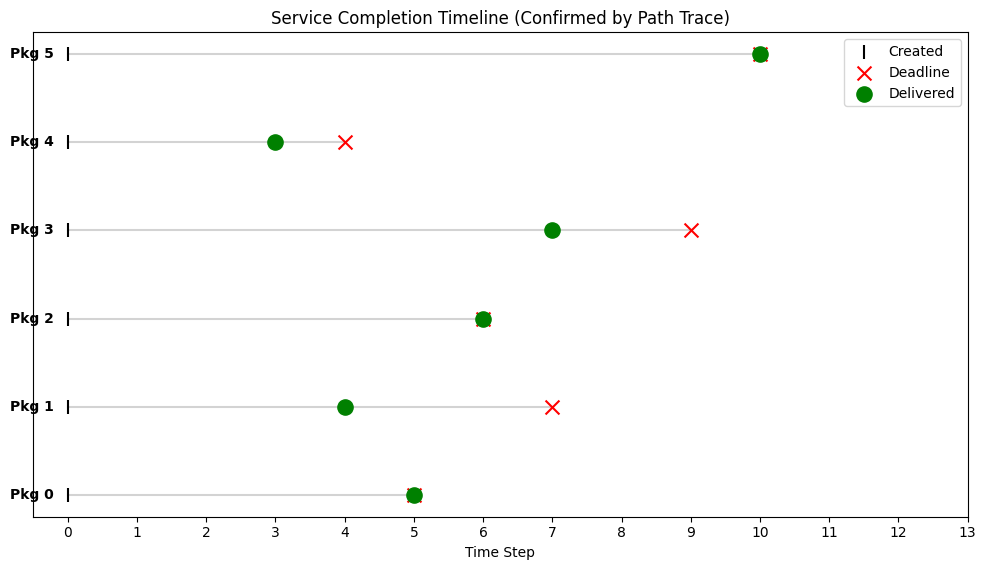

In [35]:
plot_service_timeline(model=model_small_recharge, drop_offs=drop_offs_S, hub=hub_S, time_steps=time_steps_S)

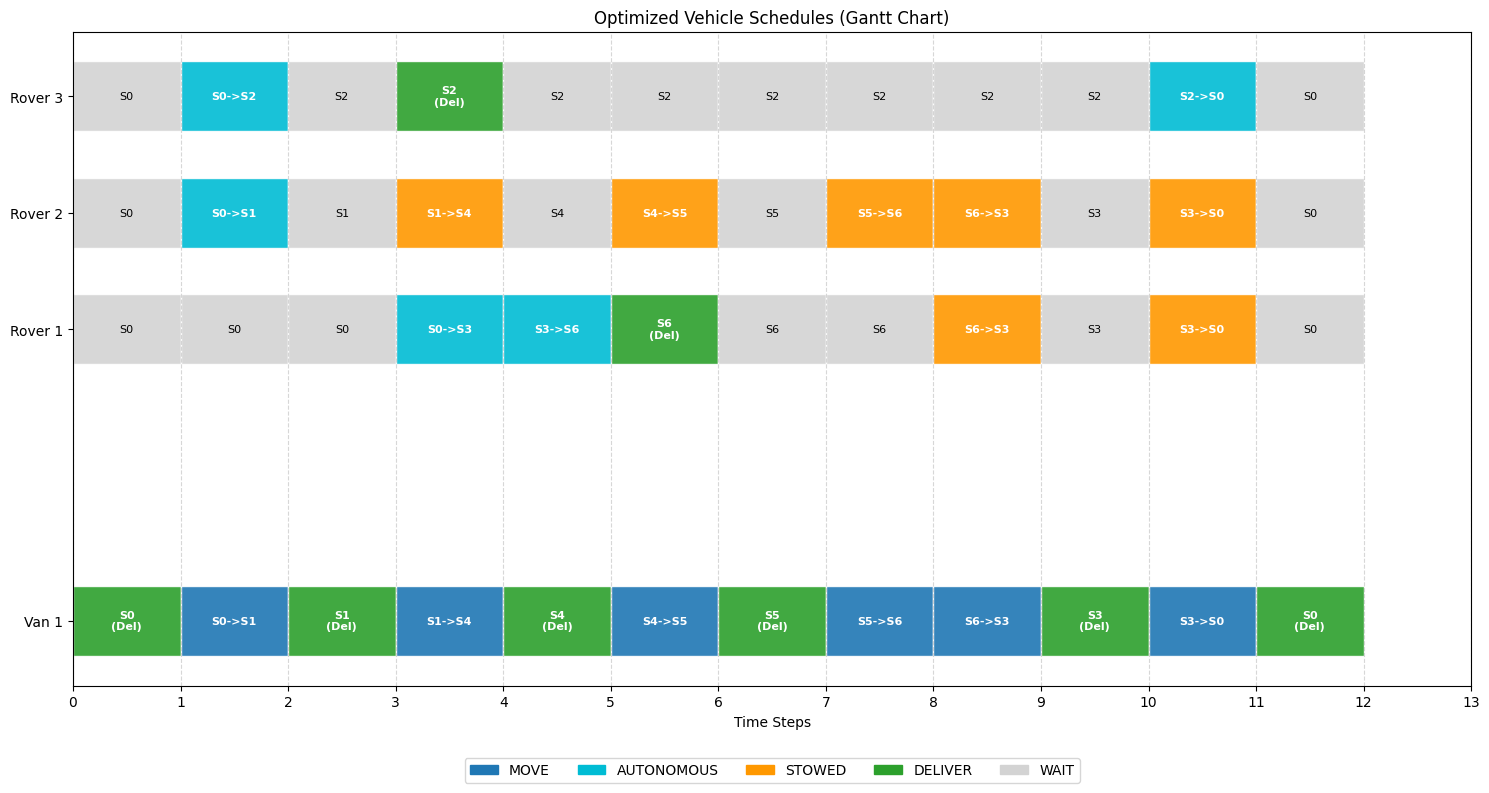

In [36]:
plot_gantt_chart(model=model_small_recharge, hub=hub_S, time_steps=time_steps_S)

## 2.5 Results - Medium Instance

In [37]:
# Load large instance

model_medium_recharge = solve_scenario_energy_recharge(
    sectors_M, adjacency_M, time_steps_M, hub_M, drop_offs_M, collections_M, params_M, G_medium
)

if model_medium_recharge.SolCount > 0:
    print(f"Objective Value: {model_medium_recharge.ObjVal}")
    print(f"Solve Time: {model_medium_recharge.Runtime:.2f}s")
    print_detailed_fleet_status(model_medium_recharge, drop_offs_M, hub_M, time_steps_M)
else:
    print("No solution found.")
    print(f"Solve Time: {model_medium_recharge.Runtime:.2f}s")

Generating x variables with pruning...
Set parameter TimeLimit to value 10800
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  10800
Method  2
Presolve  2
Seed  42

Optimize a model with 11592 rows, 21424 columns and 90092 nonzeros
Model fingerprint: 0x572be5b3
Variable types: 0 continuous, 21424 integer (6662 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+01]
Presolve removed 5493 rows and 5112 columns
Presolve time: 1.58s
Presolved: 6099 rows, 16312 columns, 58931 nonzeros
Variable types: 0 continuous, 16312 integer (4498 binary)
Root relaxation presolve removed 8 rows and 0 c

## 2.6 Visualization - Large Instance


DETAILED VAN OPERATIONS REPORT

VAN #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Sector | Battery  | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0      | -        | Idling                              | -                    | 
  1 -> 2       | 0      | -        | Driving -> S1                       | [0, 1, 2, 4]         | Carrying 3 Rover(s)
  2 -> 3       | 1      | -        | Driving -> S7                       | [0, 1, 2, 4]         | Carrying 3 Rover(s)
  3 -> 4       | 7      | -        | DELIVERING [1] (Van)                | [0, 1, 2]            | 
  4 -> 5       | 7      | -        | Driving -> S1                       | -                    | 
  5 -> 6       | 1      | -        | Driving -> S0                       | -                    |

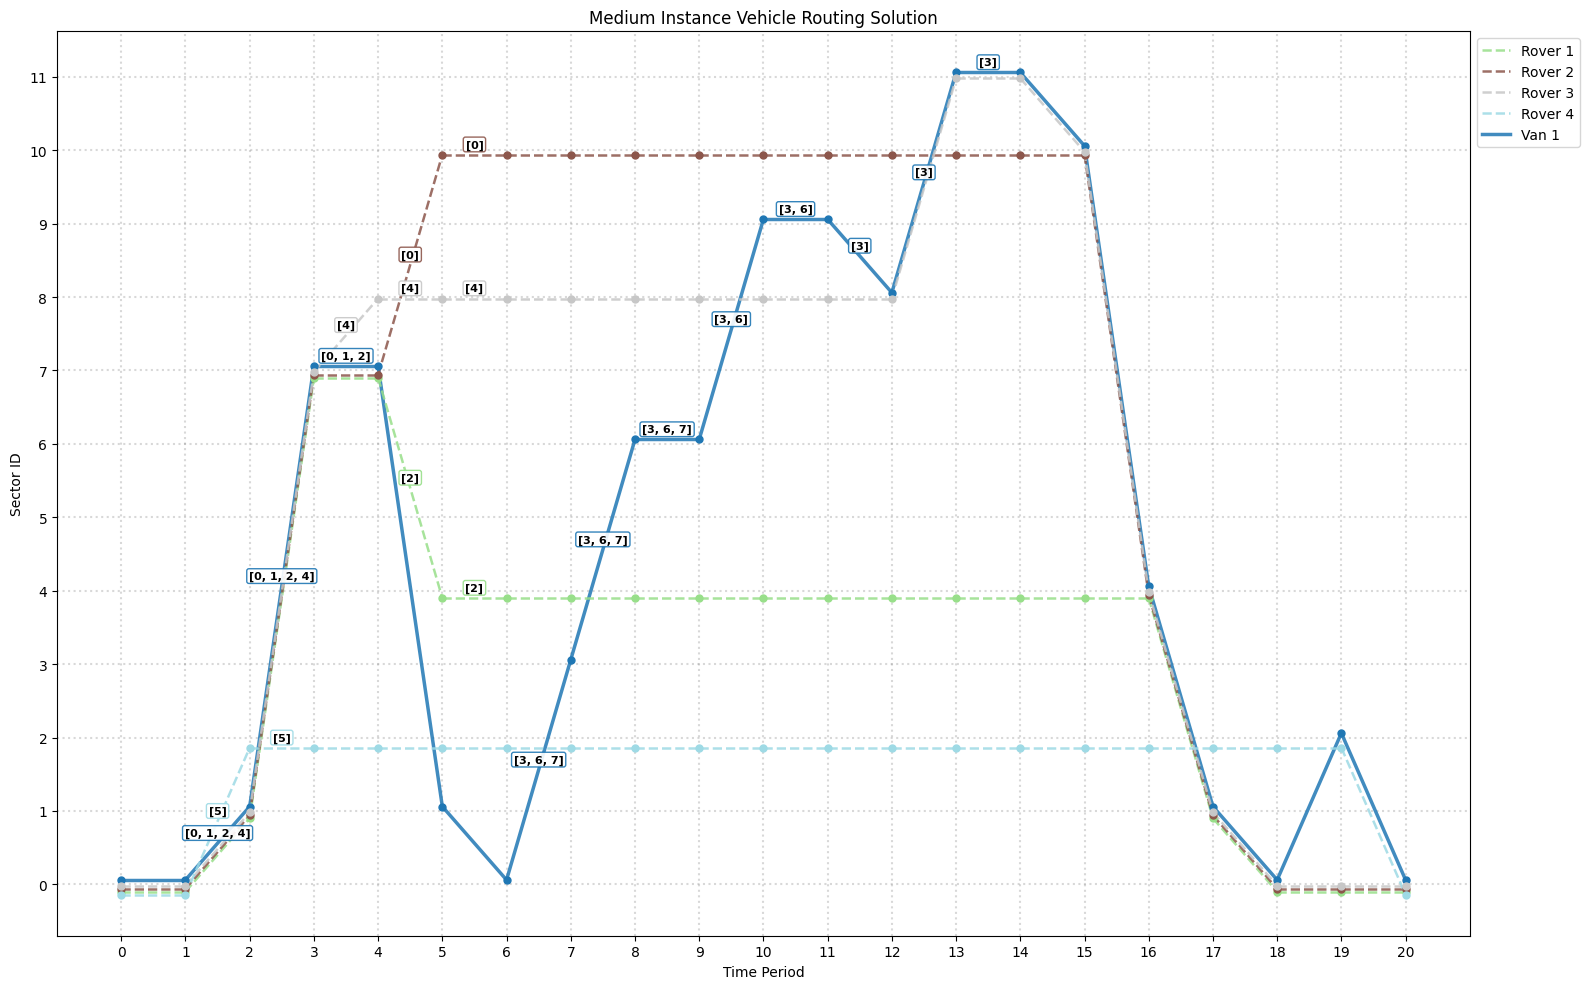

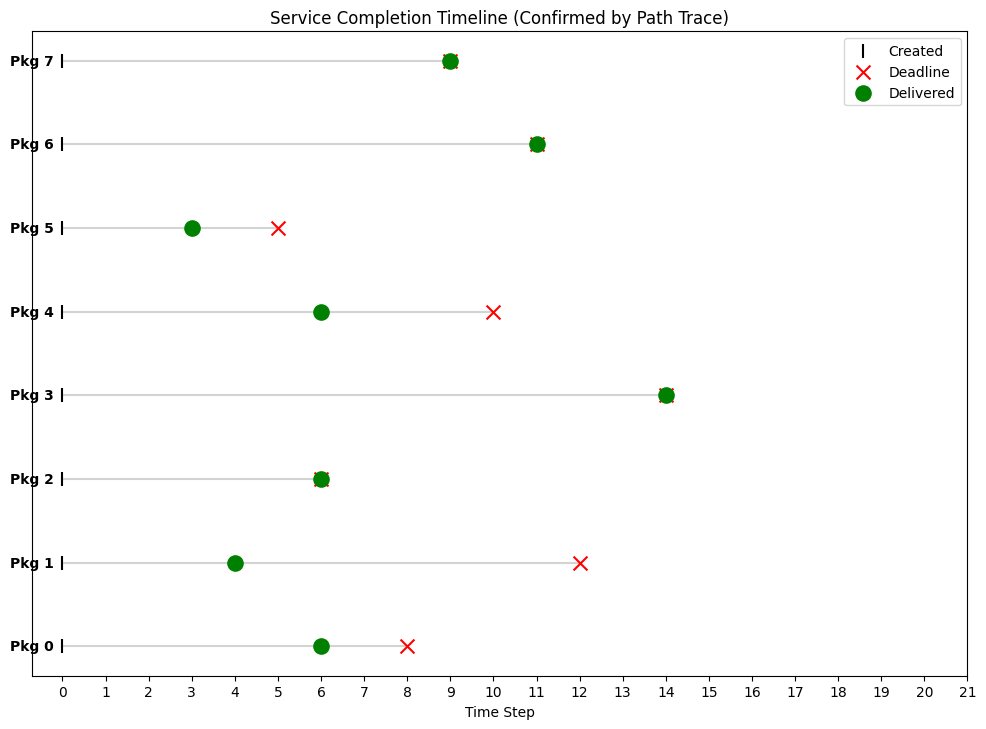

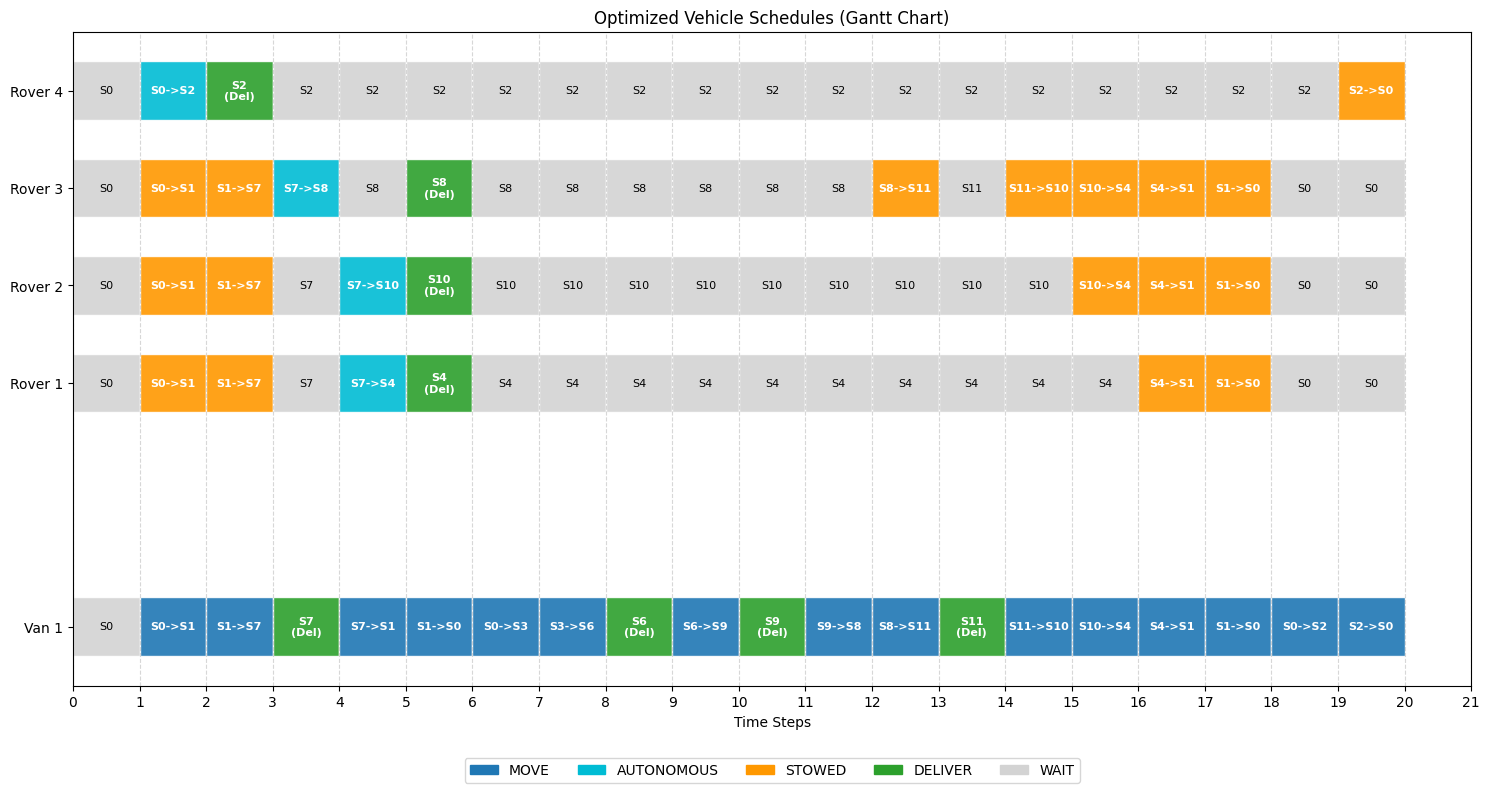

In [38]:
print_detailed_fleet_status(model=model_medium_recharge, drop_offs=drop_offs_M, hub=hub_M, time_steps=time_steps_M)
visualize_time_space_solution(model_medium_recharge, G_medium, title="Medium Instance Vehicle Routing Solution")
plot_service_timeline(model=model_medium_recharge, drop_offs=drop_offs_M, hub=hub_M, time_steps=time_steps_M)
plot_gantt_chart(model=model_medium_recharge, hub=hub_M, time_steps=time_steps_M)

---

# Scenario 3: Complete Model with Pickups and Transfers 
# Not correctly converted form the Droid case

**Objective:** Minimize total arc usage with full parcel flow tracking.

**Features:**
- All features from Scenario 2
- **New:** Pickup requests with release times
- **New:** Parcel flow tracking (continuous variables)
- **New:** Parcel transfers between vehicles
- Vehicle capacity constraints

---

## 3.1 Mathematical Formulation

### Mathematical Formulation

#### Sets and Indices
- $\mathcal{Z}$: Set of zones (spatial nodes).
- $\mathcal{T} = \{0, \dots, T_{max}\}$: Set of time periods.
- $\mathcal{N}$: Set of time-space nodes, where $u = (z, t) \in \mathcal{N}$.
- $\mathcal{A}$: The complete set of directed arcs in the time-space graph.
    * $\mathcal{A}_{Van} \subseteq \mathcal{A}$: Arcs traversable by Vans.
    * $\mathcal{A}_{Rover} \subseteq \mathcal{A}$: Arcs traversable by Rovers (Flying or Riding).
    * $\mathcal{A}_{Del} \subseteq \mathcal{A}$: Arcs designated for delivery actions.
    * $\mathcal{A}_{Inv} \subseteq \mathcal{A}$: Inventory arcs for holding items at a zone $(t \to t+1)$ (for pick-ups).
    * $\mathcal{A}_{Shelf} \subseteq \mathcal{A}$: Virtual arcs at the Hub for package storage.
- $\mathcal{K} = \mathcal{K}_{del} \cup \mathcal{K}_{pick}$: Set of all parcels, disjointly split into Deliveries and Pickups.
- $\mathcal{F}$: Set of all fleet types, defined as $\{\text{Van}, \text{Rover}, \text{Del\_Van}, \text{Pick\_Van}, \text{Del\_Rv}, \text{Pick\_Rv}, \text{Shelf}\}$.
- $\mathcal{E} = \{0, \dots, R\}$: Set of discrete energy levels for rovers.

#### Parameters
- **Capacities & Limits:**
    * $Q_{parcel}^{f}$: Parcel carrying capacity for fleet type $f$.
    * $Q_{mother}$: Capacity of a Van to carry Rovers (Mothership capacity).
    * $N_{van}, N_{rover}$: Maximum number of vehicles available.
- **Costs & Energy:**
    * $C_{fix}^{f}, C_{var}^{f}$: Fixed and variable costs for fleet $f$.
    * $E_{move}$: Energy consumption for a rover moving or waiting ($E_{wait} \approx 0$).
    * $E_{del}$: Energy consumption for performing a delivery.
    * $E_{pick}$: Energy consumption for performing a pickup.
    * $R$: Maximum energy capacity of a rover.
- **Time Windows:**
    * $T_{start}$: Global start time for operations.
    * $r_k$: Release time for parcel $k$ (Time $k$ becomes available).
    * $d_k$: Due time (deadline) for parcel $k$.

#### Decision Variables
- **Flow of Parcels:**
    * $x_{ij}^{k,f} \in \{0, 1\}$: Binary variable. 1 if parcel $k$ traverses arc $(i,j)$ using fleet type $f$ (or Inventory/Shelf).

- **Fleet Movement & Management:**
    * $y_{ij}^{f} \in \mathbb{Z}_{\geq 0}$: Integer variable. Number of vehicles of fleet type $f$ traversing arc $(i,j)$.
        * Note: For $f=\text{Shelf}$, this is fixed to 1 to represent the open hub storage.

- **Rover Energy States:**
    * $z_{ij, e}^{fly} \in \mathbb{Z}_{\geq 0}$: Number of rovers moving under own power (or waiting) on arc $(i,j)$, arriving with energy level $e$.
    * $z_{ij, e}^{ride} \in \mathbb{Z}_{\geq 0}$: Number of rovers riding on a van on arc $(i,j)$, arriving with energy level $e$.
    * $z_{ij, e}^{del} \in \mathbb{Z}_{\geq 0}$: Number of rovers performing a **delivery** on arc $(i,j)$, ending with energy level $e$.
    * $z_{ij, e}^{pick} \in \mathbb{Z}_{\geq 0}$: Number of rovers performing a **pickup** on arc $(i,j)$, ending with energy level $e$.

#### Objective Function
Minimize the total cost, comprising variable van costs (movement and waiting), rover energy costs (flying, delivering, and picking up), and fixed van costs.

$$
\begin{aligned}
\text{Minimize } Z = \quad & \sum_{(i,j) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{van}} y_{ij}^f \cdot C_{ij}^{van} \quad && \text{(Van Variable Cost)} \\
+ & \sum_{(i,j) \in \mathcal{A}} \sum_{e \in \mathcal{E}} C_{energy}^{rover} \left[ \mathbb{I}_{(i_{zone} \neq j_{zone})} \cdot z_{ij,e}^{fly} \cdot E_{move} + z_{ij,e}^{del} \cdot E_{del} + z_{ij,e}^{pick} \cdot E_{pick} \right] \quad && \text{(Rover Energy Cost)} \\
+ & \sum_{j \in \mathcal{N}} \sum_{f \in \mathcal{F}_{van}} y_{(hub, 0), j}^{f} \cdot C_{fix}^{van} \quad && \text{(Van Fixed Cost)}
\end{aligned}
$$

Where:
- $\mathcal{F}_{van} = \{\text{Van, Del\_Van, Pick\_Van}\}$
- The van arc cost $C_{ij}^{van}$ is defined as:
    $$
    C_{ij}^{van} = 
    \begin{cases} 
    C_{move}^{van} & \text{if } i_{zone} \neq j_{zone} \\
    C_{wait}^{van} & \text{if } i_{zone} = j_{zone}
    \end{cases}
    $$
- $\mathbb{I}_{(i_{zone} \neq j_{zone})}$ is an indicator function that is 1 if the rover is moving between zones (flying) and 0 if it is waiting (consistent with $E_{wait}=0$).

### Constraints

#### 1. Commodity Flow Conservation
These constraints ensure the physical continuity of parcel movement. We distinguish between deliveries (which leave the system upon service) and pickups (which enter the system and travel to the hub).

**Case A: Deliveries ($k \in \mathcal{K}_{del}$)**
- **Source:** Generated at Hub at $T_{start}$ ($+1$).
- **Sink (Implicit):** Upon taking a "Delivery" arc, the flow leaves the network (excluded from next node's inflow).

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \notin \mathcal{F}_{del}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (\text{Hub}, T_{start}) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}_{del}
$$

**Case B: Pickups ($k \in \mathcal{K}_{pick}$)**
- **Source:** Generated at the Customer Zone at Release Time $t_{rel}$ ($+1$).
- **Sink:** Absorbed at the Hub at the final time $T_{max}$ ($-1$).
- **Continuity:** Flow is conserved strictly throughout the path.

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (z_{k}^{src}, t_{k}^{rel}) \\
-1 & \text{if } u = (\text{Hub}, T_{max}) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}_{pick}
$$

As an assumption, we set that all pick-up packages to be delivered at the Hub at the last timestep.

#### 2. Force Service
This ensures that every request is successfully served (loaded or delivered) exactly once.

- **Deliveries:** Must traverse a delivery arc (by Van or Rover) at the target zone by the deadline.
- **Pickups:** Must traverse a pickup arc (by Van or Rover) at the source zone starting from the release time.

$$
\begin{aligned}
& \sum_{t=1}^{T_{due}} \sum_{f \in \mathcal{F}_{del}} x_{(z_{target}, t-1), (z_{target}, t)}^{k,f} = 1 \quad && \forall k \in \mathcal{K}_{del} \\
& \sum_{t=t_{rel}}^{T_{max}} \sum_{f \in \mathcal{F}_{pick}} x_{(z_{src}, t), (z_{src}, t+1)}^{k,f} = 1 \quad && \forall k \in \mathcal{K}_{pick}
\end{aligned}
$$

Where:
- $\mathcal{F}_{del} = \{\text{Del\_Van, Del\_Rv}\}$
- $\mathcal{F}_{pick} = \{\text{Pick\_Van, Pick\_Rv}\}$

### 3 Asset Balance & Global Fleet Limits

These constraints manage the available fleet size at the hub ($t=0$) and ensure vehicles are conserved (flow in = flow out) throughout the timeline.

#### 3.1. Global Van Limit (at $t=0$)
The total number of vans (standard, delivery, and pickup) leaving the hub at time 0 cannot exceed the available fleet size $N_{van}$.

$$
\sum_{v \in \text{neighbors}(\text{Hub},0)} \sum_{f \in \mathcal{F}_{van}} y_{(\text{Hub},0), v}^{f} \leq N_{van}
$$
Where $\mathcal{F}_{van} = \{\text{Van, Del\_Van, Pick\_Van}\}$.

#### 3.2. Global Rover Limit & Initial Energy (at $t=0$)
The total number of rovers (flying, riding, delivering, or picking up) leaving the hub at time 0 cannot exceed $N_{rover}$. Furthermore, all rovers leaving the hub must start with full energy capacity ($e=R$).

**Limit Constraint:**
$$
\sum_{v \in \text{neighbors}(\text{Hub},0)} \sum_{e=0}^{R} \left( z_{(\text{Hub},0), v, e}^{fly} + z_{(\text{Hub},0), v, e}^{ride} + z_{(\text{Hub},0), v, e}^{del} + z_{(\text{Hub},0), v, e}^{pick} \right) \leq N_{rover}
$$

**Full Energy Enforcement:**
All rovers deploying from the hub must initiate operations with maximum charge. Let $\mathcal{M} = \{\text{fly, ride, del, pick}\}$ be the set of rover operating modes. We enforce:

$$
z_{(\text{Hub}, 0), v, e}^{\mu} = 0 \quad \forall v \in \text{Succ}(\text{Hub}, 0), \quad \forall e < R, \quad \forall \mu \in \mathcal{M}
$$

#### 3.3. Van Asset Balance (Flow Conservation)
For all intermediate time-space nodes ($0 < t < T_{max}$), the number of vans arriving must equal the number of vans departing. This maintains the physical continuity of the van fleet.

$$
\sum_{(u, n) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{van}} y_{u, n}^{f} = \sum_{(n, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{van}} y_{n, v}^{f} \quad \forall n = (z, t) \text{ where } 0 < t < T_{max}
$$

### 4. Capacity Constraints

We ensure that the total number of parcels (both deliveries and pickups) assigned to a specific fleet type $f$ on arc $(u,v)$ does not exceed the capacity provided by the active vehicles of that type.

#### Case 4.1: Flying Rovers ($f = \text{Rover}$)
For rovers moving autonomously (flying or waiting) on standard transit arcs, the capacity is provided by the total count of flying rovers across all valid energy levels.
*Note: Rovers "riding" on vans do not provide capacity for parcels on the arc itself.*

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, \text{Rover}} \leq Q_{\text{Rover}} \cdot \left( \sum_{e=0}^{R} z_{u, v, e}^{fly} \right) \quad \forall (u, v) \in \mathcal{A}
$$

#### Case 4.2: General Fleets ($f \neq \text{Rover}$)
For all other fleet types—including Vans, Service Vans (Deliver/Pickup), and the Virtual Shelf — the capacity is determined by the generic vehicle count variable $y_{u,v}^f$.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, f} \leq Q_{f} \cdot y_{u, v}^{f} \quad \forall (u, v) \in \mathcal{A}, \quad \forall f \in \mathcal{F}_{gen}
$$

**Where:**
- $\mathcal{K} = \mathcal{K}_{del} \cup \mathcal{K}_{pick}$ (All commodities).
- $\mathcal{F}_{gen} = \{\text{Van, Del\_Van, Pick\_Van, Del\_Rv, Pick\_Rv, Shelf}\}$.
- $Q_f$ is the fleet capacity parameter (`cap_per_fleet`).

### 5. Coupling & Mothership Constraints

These constraints link the detailed rover energy states ($z$) to the aggregate fleet flows ($y$) and enforce physical carrying limits.

#### 5.1. Mothership Constraint (Capacity)
If rovers are "riding," they must be physically carried by a van. The total number of riding rovers (across all energy levels) on an arc cannot exceed the carrying capacity of the vans traversing that same arc.
*Note: All van types (Standard, Delivery, and Pickup) are capable of carrying rovers.*

$$
\sum_{e=0}^{R} z_{u, v, e}^{ride} \leq C_{van}^{rover} \cdot \left( y_{u, v}^{\text{Van}} + y_{u, v}^{\text{Del\_Van}} + y_{u, v}^{\text{Pick\_Van}} \right) \quad \forall (u, v) \in \mathcal{A}_{\text{Rover}}
$$

#### 5.2. Rover Delivery Coupling
For arcs representing a delivery action, the aggregate delivery flow ($y^{\text{Del\_Rv}}$) must correspond to the sum of rovers actually performing the delivery action.

$$
\sum_{e=0}^{R} z_{u, v, e}^{del} = y_{u, v}^{\text{Del\_Rv}} \quad \forall (u, v) \in \mathcal{A}_{\text{Del\_Rv}}
$$

---

### 6. Inventory Restrictions & Precedence

These constraints enforce strict logical rules about where parcels can wait and ensure that items cannot move through the network before they have been physically picked up.

#### 6.1. Inventory Restrictions
To prevent unrealistic "floating" or "dropping" of parcels, items are only allowed to use **Inventory Arcs** (wait) at their specific valid locations:
- **Deliveries:** Can only wait at the **Hub Shelf**.
- **Pickups:** Can only wait at their **Source Zone** (before pickup).
- **Intermediate Zones:** No waiting allowed (Drop-offs banned).

$$
x_{(z, t), (z, t+1)}^{k, \text{Inventory}} = 0 \quad \text{if } z \notin \text{AllowedLocations}(k)
$$

#### 6.2. Pickup Precedence (Anti-Teleportation)
For pickup requests, a parcel cannot travel on a **Transit Arc** (Van/Rover movement) unless the **Pickup Service** has already been completed. This prevents the model from moving a "ghost" package before the vehicle actually picks it up.

$$
\sum_{f \in \mathcal{F}_{transit}} x_{(z, t), (v, t+1)}^{k, f} \leq \sum_{\tau=0}^{t} \sum_{f \in \mathcal{F}_{pick}} \sum_{w} x_{(w, \tau-1), (z, \tau)}^{k, f}
$$

**Where:**
- $\mathcal{F}_{transit}$: Fleet types used for moving parcels (Vans, Rovers, Riding).
- $\mathcal{F}_{pick}$: Fleet types performing the pickup action.
- The RHS represents the "Inventory of Picked-up Items" available to move.

### 7. Energy Balance (Recharge on Ride)

This constraint ensures flow conservation for rovers at every specific energy level $e$. It uses a **Backtracking Logic**: to be at node $n$ with energy $e$, a rover must have arrived from a predecessor $p$ starting with higher energy $e + Cost$.

**Constraint Logic:**
$$
\begin{aligned}
& \underbrace{ \sum_{p} z_{p, n, (e + Cost_{fly})}^{fly} }_{\text{Inflow: Flying/Waiting}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + E_{del})}^{del} }_{\text{Inflow: Delivery}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + E_{pick})}^{pick} }_{\text{Inflow: Pickup}} \\
+ & \underbrace{ \delta_{e,R} \cdot \left( \sum_{p} \sum_{k=0}^{R} z_{p, n, k}^{ride} \right) }_{\text{Inflow: Recharging Riders}} 
\quad = \quad
\underbrace{ \sum_{v} \left( z_{n, v, e}^{fly} + z_{n, v, e}^{ride} + z_{n, v, e}^{del} + z_{n, v, e}^{pick} \right) }_{\text{Total Outflow}}
\end{aligned}
$$

**Where:**
- $\delta_{e,R}$: Indicator ($1$ if $e=R$, else $0$). Riders effectively "reset" to full energy upon arrival.
- $Cost_{fly}$: Dynamically $E_{move}$ if $p_{zone} \neq n_{zone}$ (flying), or $E_{wait}$ if $p_{zone} = n_{zone}$ (waiting).
- **State Logic:** The constraint sums all possible ways to arrive at state $(n, e)$—whether by flying/waiting (draining $E_{move}$), working (draining $E_{del}$ or $E_{pick}$), or riding (recharging to $R$).

### 8. Strong Linking (Hub Initialization Cuts)

To strengthen the linear relaxation of the model, we apply "Strong Linking" constraints specifically at the Hub ($t=0$). This ensures that a delivery parcel $k$ cannot be assigned to leave the hub on a specific van arc unless there is at least one active van (of any type) traversing that arc.

$$
x_{(\text{Hub}, 0), v}^{k, f} \leq \sum_{g \in \mathcal{F}_{van}} y_{(\text{Hub}, 0), v}^{g} 
\quad 
\forall v \in \text{Succ}(\text{Hub}, 0), \quad \forall k \in \mathcal{K}_{del}, \quad \forall f \in \mathcal{F}_{van}
$$

**Where:**
- $\mathcal{F}_{van} = \{\text{Van, Del\_Van, Pick\_Van}\}$.
- **Logic:** If the total number of vans (RHS) on the arc is 0, the binary assignment variable for the parcel (LHS) is forced to 0. If vans exist, the constraint allows the flow ($x \le N$, where $N \ge 1$, allows $x=1$).


## 3.2 Implementation

Implement Scenario 3 model in the cell below.

In [10]:
# ==========================================
# 1. GRAPH GENERATION (SINGLE-EDGE)
# ==========================================
import networkx as nx
import re
import copy
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import numpy as np
import gurobipy as gp
from gurobipy import GRB

def build_time_space_multigraph_pick_and_deliver(sectors, adjacency, time_steps, hub=0):
    """
    Builds a time-space network where every arc guarantees the vehicle 
    can still reach the hub by the final time step.
    Includes 'Van', 'Rover', 'Dropoff', and 'Collection' arcs.
    Robust to Integer vs String keys in adjacency dict.
    """
    G = nx.MultiDiGraph()

    # --- Step 1: Compute shortest path to hub for each sector (BFS) ---
    shortest_to_hub = {}
    
    for s in sectors:
        shortest_to_hub[s] = float('inf')

    # BFS from Hub
    queue = [(hub, 0)]
    visited = {hub}
    shortest_to_hub[hub] = 0
    
    while queue:
        curr, dist = queue.pop(0)
        
        # Robust Lookup
        neighbors = adjacency.get(curr) or adjacency.get(str(curr)) or []
        
        for neighbor in neighbors:
            neighbor = int(neighbor)
            if neighbor not in visited:
                visited.add(neighbor)
                shortest_to_hub[neighbor] = dist + 1
                queue.append((neighbor, dist + 1))

    # --- Step 2: Add nodes for all time steps ---
    for t in range(time_steps):
        for s in sectors:
            G.add_node((s, t))

    # --- Step 3: Add feasible arcs ---
    for t in range(time_steps - 1):
        for s in sectors:

            # Constraint: Only the hub is active at t=0 (Source)
            if t == 0 and s != hub:
                continue
            
            if shortest_to_hub[s] == float('inf'):
                continue

            # Robust lookup for neighbors
            real_neighbors = adjacency.get(s) or adjacency.get(str(s)) or []
            real_neighbors = [int(n) for n in real_neighbors]
            
            targets = real_neighbors + [s]

            for s2 in targets:
                # --- THE RETURN CONSTRAINT ---
                if shortest_to_hub[s2] != float('inf') and (t + 1 + shortest_to_hub[s2] <= time_steps - 1):
                    
                    # 1. Standard Transport Arcs (Move or Wait)
                    G.add_edge((s, t), (s2, t + 1), arc_type="Van")
                    G.add_edge((s, t), (s2, t + 1), arc_type="Rover")
                    
                    # 2. Service Arcs (Only if staying in the same sector)
                    if s == s2:
                        # Dropoff Arc: Drop off a package
                        G.add_edge((s, t), (s2, t + 1), arc_type="Dropoff")
                        
                        # Collection Arc: Pick up a package
                        G.add_edge((s, t), (s2, t + 1), arc_type="Collection")

    return G

# ==========================================
# 2. PARSING & GANTT CHART VISUALIZATION
# ==========================================
def get_optimized_schedules_3(model, hub, time_steps):
    """
    Decomposes flow with explicit action tagging (Dropoff, Collection, Move).
    Includes logic to detect Collection actions for Scenario 3.
    """
    # Structure: adj[fleet][u] = [ {'v': v, 'tag': 'DROPOFF'/'COLLECTION'/'STD'} ]
    adj = {'Van': {}, 'Rover': {}} 
    rover_modes = {} # (u, v) -> "RIDE" / "DRIVE" / "DROPOFF" / "COLLECTION"
    
    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Van" in raw: return "Van"
        if "Rover" in raw: return "Rover"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                
                # DETERMINE TAG
                tag = "STD"
                if "Dropoff" in fleet_raw:
                    tag = "DROPOFF"
                elif "Collection" in fleet_raw: 
                    tag = "COLLECTION"

                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append({'v': v, 'tag': tag})

        # B) Rover Mode (z)
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                
                if "ride" in mode_raw: mode = "RIDE"
                elif "drop" in mode_raw: mode = "DROPOFF"
                elif "coll" in mode_raw: mode = "COLLECTION" 
                else: mode = "DRIVE"
                
                if (u,v) not in rover_modes or mode == "RIDE":
                    rover_modes[(u, v)] = mode

    # --- 3. Deterministic Sorting ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda item: (item['v'][1], item['v'][0]))

    # --- 4. Reconstruct Paths ---
    schedules = {'Van': [], 'Rover': []}
    start_node = (int(hub), 0) 

    for fleet in ['Van', 'Rover']:
        current_adj = adj.get(fleet, {})
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while True:
                if curr not in current_adj or not current_adj[curr]:
                    break
                
                step_data = current_adj[curr].pop(0)
                nxt = step_data['v']
                tag = step_data['tag']
                
                action = "WAIT"
                
                # --- VAN LOGIC ---
                if fleet == 'Van':
                    if tag == "DROPOFF":
                        action = "DROPOFF"
                    elif tag == "COLLECTION":
                        action = "COLLECTION"
                    elif curr[0] != nxt[0]: 
                        action = "MOVE"
                    else:
                        action = "WAIT"
                
                # --- ROVER LOGIC ---
                else:
                    if tag == "DROPOFF":
                        action = "DROPOFF"
                    elif tag == "COLLECTION":
                        action = "COLLECTION"
                    else:
                        mode = rover_modes.get((curr, nxt), "DRIVE")
                        if mode == "RIDE": action = "RIDE"
                        elif mode == "DROPOFF": action = "DROPOFF"
                        elif mode == "COLLECTION": action = "COLLECTION"
                        elif curr[0] != nxt[0]: action = "DRIVE"
                        else: action = "WAIT"

                path.append({
                    'start_time': curr[1],
                    'end_time': nxt[1],
                    'start_sector': curr[0],
                    'end_sector': nxt[0],
                    'action': action
                })
                
                curr = nxt
                if curr[1] >= time_steps - 1: break
            
            schedules[fleet].append(path)
            
    return schedules

def plot_gantt_chart_3(model, hub, time_steps):
    """
    Plots the Gantt Chart with COLLECTION support.
    """
    schedules = get_optimized_schedules_3(model, hub, time_steps)
    
    fig, ax = plt.subplots(figsize=(15, 8)) 
    
    # Visual Configuration
    colors = {
        'MOVE': '#1f77b4',        # Blue (Van Move)
        'DRIVE': '#00bcd4',       # Cyan (Rover Drive)
        'RIDE': '#ff9800',        # Orange (Rover Ride)
        'DROPOFF': '#2ca02c',     # Green (Dropoff)
        'COLLECTION': '#9467bd',  # Purple (Collection)
        'WAIT': '#d3d3d3'         # Grey (Wait)
    }
    
    y_pos = 0
    y_ticks = []
    y_labels = []
    
    # --- 1. Plot Vans ---
    for i, path in enumerate(schedules['Van']):
        y_pos += 10
        label = f"Van {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            mid = start + dur/2
            if action == "MOVE":
                txt = f"S{leg['start_sector']}->S{leg['end_sector']}"
            elif action == "DROPOFF":
                txt = f"S{leg['start_sector']}\n(Drop)"
            elif action == "COLLECTION":
                txt = f"S{leg['start_sector']}\n(Coll)"
            else:
                txt = f"S{leg['start_sector']}"
            
            font_weight = 'bold' if action in ['DROPOFF', 'COLLECTION', 'MOVE'] else 'normal'
            txt_color = 'white' if action != 'WAIT' else 'black'
            
            ax.text(mid, y_pos, txt, ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    y_pos += 15
    
    # --- 2. Plot Rovers ---
    for i, path in enumerate(schedules['Rover']):
        y_pos += 10
        label = f"Rover {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            mid = start + dur/2
            if action == "DRIVE" or action == "RIDE":
                txt = f"S{leg['start_sector']}->S{leg['end_sector']}"
            elif action == "DROPOFF":
                txt = f"S{leg['start_sector']}\n(Drop)"
            elif action == "COLLECTION":
                txt = f"S{leg['start_sector']}\n(Coll)"
            else:
                txt = f"S{leg['start_sector']}"

            font_weight = 'bold' if action in ['DROPOFF', 'COLLECTION', 'DRIVE', 'RIDE'] else 'normal'
            txt_color = 'black' if action in ['WAIT'] else 'white'
            
            ax.text(mid, y_pos, txt, ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)
    ax.set_xticks(range(time_steps + 1)) 
    
    ax.set_xlabel("Time Steps")
    ax.set_title("Optimized Fleet Schedules (Gantt Chart)")
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)
    
    patches = [mpatches.Patch(color=c, label=l) for l, c in colors.items()]
    ax.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=6)
    
    #plt.tight_layout()
    fig = ax.get_figure()
    return fig

In [57]:
import copy
import matplotlib.cm as cm

def plot_service_timeline_3(model, drop_offs, collections, hub, time_steps):
    """
    Plots the service timeline tracking both COLLECTION and DROPOFF events.
    Splits the visual into two distinct sections to prevent ID collision overlaps.
    """
    adj = {'Van': {}, 'Rover': {}} 
    pkg_on_link = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Van" in raw: return "Van"
        if "Rover" in raw: return "Rover"
        return raw

    print("Scanning variables...") 
    
    re_flow_gurobi = re.compile(r"y\[('?[\w]+'?),\((\d+,\d+)\),\((\d+,\d+)\)\]")
    re_cargo_gurobi = re.compile(r"x\[(\d+),\((\d+,\d+)\),\((\d+,\d+)\),'?([\w]+)'?\]")

    re_flow_under = re.compile(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)")
    re_cargo_under = re.compile(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)")

    count_y = 0
    count_x = 0

    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName

        # --- A) Network Flow (y) ---
        if name.startswith("y"):
            m = re_flow_gurobi.search(name)
            if not m:
                m = re_flow_under.search(name)
            
            if m:
                count_y += 1
                fleet_raw = m.group(1).replace("'", "")
                u_str = m.group(2)
                v_str = m.group(3)
                
                u = tuple(map(int, u_str.replace('(', '').replace(')', '').split(',')))
                v = tuple(map(int, v_str.replace('(', '').replace(')', '').split(',')))
                
                count = int(round(var.X))
                fleet_key = get_fleet_key(fleet_raw)

                tag = "STD"
                if "Dropoff" in fleet_raw: tag = "DROPOFF"
                elif "Collection" in fleet_raw: tag = "COLLECTION"

                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append({'v': v, 'tag': tag})

        # --- B) Cargo Flow (x) ---
        elif name.startswith("x"):
            re_cargo_fixed = re.search(r"x_(drop|coll)_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            
            if re_cargo_fixed:
                count_x += 1
                task_type = re_cargo_fixed.group(1)
                k = int(re_cargo_fixed.group(2))     
                u_str = re_cargo_fixed.group(3)      
                v_str = re_cargo_fixed.group(4)      
                fleet_raw = re_cargo_fixed.group(5)  

                u = tuple(map(int, u_str.replace('(', '').replace(')', '').split(',')))
                v = tuple(map(int, v_str.replace('(', '').replace(')', '').split(',')))
                
                fleet_key = get_fleet_key(fleet_raw)
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                
                # Store tuple (ID, type) to distinguish Dropoff 0 from Collection 0
                pkg_on_link[key].append((k, task_type))
            else:
                m = re_cargo_gurobi.search(name)
                if m:
                    count_x += 1
                    k = int(m.group(1))
                    u = tuple(map(int, m.group(2).split(',')))
                    v = tuple(map(int, m.group(3).split(',')))
                    fleet_key = get_fleet_key(m.group(4).replace("'", ""))
                    
                    key = (u, v, fleet_key)
                    if key not in pkg_on_link: pkg_on_link[key] = []
                    # Fallback default to dropoff if regex fails
                    pkg_on_link[key].append((k, 'drop'))

    # --- 3. Trace Paths to Record Times ---
    actual_dropoff_times = {} 
    actual_collection_times = {}
    actual_hub_return_times = {}
    
    drop_lookup = {d['id']: d for d in drop_offs}
    coll_lookup = {p['id']: p for p in collections}

    start_node = (int(hub), 0)

    for fleet_name in ["Van", "Rover"]:
        current_adj = adj.get(fleet_name, {})
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            curr = start_node
            
            while True:
                if curr not in current_adj or not current_adj[curr]:
                    break
                
                step = current_adj[curr].pop(0)
                next_node = step['v']
                tag = step['tag']
                
                flow_key = (curr, next_node, fleet_name)
                pkgs = pkg_on_link.get(flow_key, [])
                
                for p_id, p_type in pkgs:
                    if p_type == 'coll':
                        # RECORD COLLECTION
                        if tag == "COLLECTION":
                            actual_collection_times[p_id] = curr[1]
                        elif p_id in coll_lookup and coll_lookup[p_id]['sector'] == curr[0]:
                            if p_id not in actual_collection_times:
                                actual_collection_times[p_id] = curr[1]
                                
                        # RECORD HUB RETURN (End of collection journey)
                        if next_node[0] == int(hub) and p_id in actual_collection_times:
                            actual_hub_return_times[p_id] = next_node[1]
                            
                    elif p_type == 'drop':
                        # RECORD DROPOFF
                        if tag == "DROPOFF":
                            actual_dropoff_times[p_id] = next_node[1]
                        elif p_id in drop_lookup and drop_lookup[p_id]['sector'] == next_node[0]:
                            actual_dropoff_times[p_id] = next_node[1]

                curr = next_node
                if curr[1] >= time_steps - 1: break

    # --- 4. Plotting ---
    fig, ax = plt.subplots(figsize=(12, (len(drop_offs) + len(collections)) * 0.9 + 3))
    y_pos = 0
    y_ticks = []
    y_labels = []

    # --- Plot Drop-offs ---
    if drop_offs:
        ax.text(time_steps / 2, y_pos + 0.5, "--- DROP-OFFS ---", ha='center', va='center', fontweight='bold', color='gray')
        y_pos += 1
        
        drop_data = []
        for d in drop_offs:
            k = d['id']
            drop_data.append({
                'id': k,
                'created': 0, 
                'due': d['deadline'],
                'actual': actual_dropoff_times.get(k, None)
            })
        drop_data.sort(key=lambda x: x['id'])

        for item in drop_data:
            y_pos += 1
            created, due, actual = item['created'], item['due'], item['actual']
            
            y_ticks.append(y_pos)
            y_labels.append(f"Drop {item['id']}")
            
            ax.plot([created, due], [y_pos, y_pos], color='#e0e0e0', zorder=1, linewidth=2)
            ax.scatter(created, y_pos, marker='|', s=100, color='black', label='Created (Hub)' if y_pos==2 else "")
            ax.scatter(due, y_pos, marker='x', s=100, color='red', label='Deadline' if y_pos==2 else "")

            if actual is not None:
                col = 'green' if actual <= due else 'red'
                ax.scatter(actual, y_pos, marker='o', s=120, color=col, zorder=3, label='Dropped Off' if y_pos==2 else "")
                ax.plot([created, actual], [y_pos, y_pos], color='#1f77b4', linewidth=2, zorder=2)

        y_pos += 1 # Spacer

    # --- Plot Collections ---
    if collections:
        ax.text(time_steps / 2, y_pos + 0.5, "--- COLLECTIONS ---", ha='center', va='center', fontweight='bold', color='gray')
        y_pos += 1
        
        coll_data = []
        for c in collections:
            k = c['id']
            coll_data.append({
                'id': k,
                'release': c['release_time'],
                'collection': actual_collection_times.get(k, None),
                'hub_return': actual_hub_return_times.get(k, None)
            })
        coll_data.sort(key=lambda x: x['id'])

        for item in coll_data:
            y_pos += 1
            release, collection, hub_return = item['release'], item['collection'], item['hub_return']
            
            y_ticks.append(y_pos)
            y_labels.append(f"Coll {item['id']}")
            
            ax.plot([release, time_steps - 1], [y_pos, y_pos], color='#e0e0e0', zorder=1, linewidth=2)
            ax.scatter(release, y_pos, marker='|', s=100, color='orange', label='Available' if y_pos==(len(drop_offs)+3) else "")

            if collection is not None:
                ax.scatter(collection, y_pos, marker='s', s=100, color='#9467bd', zorder=3, label='Collected' if y_pos==(len(drop_offs)+3) else "")
                ax.plot([release, collection], [y_pos, y_pos], color='gray', linestyle=':', zorder=1)
                
                if hub_return is not None:
                    ax.scatter(hub_return, y_pos, marker='o', s=120, color='green', zorder=3, label='Returned to Hub' if y_pos==(len(drop_offs)+3) else "")
                    ax.plot([collection, hub_return], [y_pos, y_pos], color='#1f77b4', linewidth=2, zorder=2)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontweight='bold')
    ax.set_xticks(range(time_steps + 1))
    ax.set_xlabel("Time Step")
    ax.set_title("Package Service Timeline (Separated by Task Type)")
    
    # Consolidate legends
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=6)
    
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    fig = ax.get_figure()
    return fig

def print_detailed_fleet_status_PDP(model, drop_offs, collections, hub, time_steps):
    """
    Parses the updated MILP solution to provide detailed status for Vans and Rovers.
    Includes D: and C: prefixes to resolve payload ID overlaps.
    """
    adj = {'Van': {}, 'Rover': {}} 
    pkg_on_link = {} 
    rovers_on_link = {} 
    rover_props = {}
    van_actions = {} 

    drop_lookup = {d['id']: d for d in drop_offs}
    coll_lookup = {p['id']: p for p in collections}

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Van" in raw: return "Van"
        if "Rover" in raw: return "Rover"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)
                    
                    if fleet_key == "Van":
                        key = (u, v)
                        if key not in van_actions: van_actions[key] = []
                        
                        action = "MOVE"
                        if "Dropoff" in fleet_raw: action = "DROPOFF"
                        elif "Collection" in fleet_raw: action = "COLLECTION"
                        
                        van_actions[key].append(action)

        # B) Package Flow (x) - x_drop and x_coll
        elif name.startswith("x_"):
            m_drop = re.search(r"x_drop_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            m_coll = re.search(r"x_coll_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            
            p_type = None
            m = None
            
            if m_drop:
                m = m_drop
                p_type = 'dropoff'
            elif m_coll:
                m = m_coll
                p_type = 'collection'
                
            if m:
                k = int(m.group(1))
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                fleet_raw = m.group(4)
                fleet_key = get_fleet_key(fleet_raw)
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append((k, p_type))
        
        # C) Rover Z Variables
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                e_level = int(m.group(4))
                count = int(round(var.X))
                
                mode_str = "UNKNOWN"
                if "ride" in mode_raw: mode_str = "RIDE"
                elif "drive" in mode_raw: mode_str = "DRIVE"
                elif "drop" in mode_raw: mode_str = "DROPOFF"
                elif "coll" in mode_raw: mode_str = "COLLECTION"

                key = (u, v)
                if key not in rover_props: rover_props[key] = []
                for _ in range(count):
                    rover_props[key].append({'energy': e_level, 'mode': mode_str})

                if mode_str == "RIDE":
                    if key not in rovers_on_link: rovers_on_link[key] = 0
                    rovers_on_link[key] += count

    # --- 3. Sort for Determinism ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    for key in rover_props:
        rover_props[key].sort(key=lambda x: x['energy'], reverse=True)

    for key in van_actions:
        van_actions[key].sort(key=lambda x: 0 if x in ["DROPOFF", "COLLECTION"] else 1)

    # --- 4. Print Report ---
    for fleet_name in ["Van", "Rover"]:
        print(f"\n{'='*120}")
        print(f"DETAILED {fleet_name.upper()} OPERATIONS REPORT")
        print(f"{'='*120}")
        
        current_adj = adj.get(fleet_name, {})
        start_node = (hub, 0)
        
        if start_node not in current_adj:
            print(f"No {fleet_name}s found starting at Hub (Time 0).")
            continue

        veh_id = 1
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path_info = [] 
            curr = start_node
            current_expected_energy = None 

            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) 
                
                # 1. Get Cargo
                pkgs = []
                flow_key = (curr, next_node, fleet_name)
                if flow_key in pkg_on_link:
                    pkgs = pkg_on_link[flow_key][:]
                
                # 2. Get Attributes & Determine Mode
                energy_val = "-"
                mode_val = "UNKNOWN"
                
                if fleet_name == "Rover":
                    props_key = (curr, next_node)
                    if props_key in rover_props and rover_props[props_key]:
                        found_idx = -1
                        if current_expected_energy is not None:
                            for i, p in enumerate(rover_props[props_key]):
                                if p['energy'] == current_expected_energy:
                                    found_idx = i
                                    break
                        
                        if found_idx == -1:
                            found_idx = 0
                            
                        p = rover_props[props_key].pop(found_idx)
                        energy_val = p['energy']
                        mode_val = p['mode']
                        
                        cost = 0
                        if mode_val in ["DROPOFF", "COLLECTION"]:
                            cost = 1
                        elif mode_val == "DRIVE" and curr[0] != next_node[0]:
                            cost = 1
                        
                        current_expected_energy = energy_val - cost
                        
                else:
                    t_key = (curr, next_node)
                    if t_key in van_actions and van_actions[t_key]:
                        mode_val = van_actions[t_key].pop(0)
                
                # 3. Get Riders
                riders = 0
                if fleet_name == "Van" and (curr, next_node) in rovers_on_link:
                    if rovers_on_link[(curr, next_node)] > 0:
                        riders = rovers_on_link[(curr, next_node)]
                        rovers_on_link[(curr, next_node)] -= riders
                
                path_info.append({
                    'u': curr, 'v': next_node, 
                    'pkgs': pkgs, 'riders': riders, 
                    'energy': energy_val, 'mode': mode_val
                })
                curr = next_node
                if curr[0] == hub and curr[1] == time_steps - 1: break
            
            print(f"\n{fleet_name.upper()} #{veh_id}")
            print(f"  {'-'*120}")
            print(f"  {'Time':<12} | {'Sect':<5} | {'Energy':<8} | {'Activity':<40} | {'Payload':<25} | {'Notes'}")
            print(f"  {'-'*120}")
            
            for step in path_info:
                u, v = step['u'], step['v']
                mode = step['mode']
                activity = ""
                
                # FIX: Add D: or C: to Payload strings
                payload_str = ""
                if step['pkgs']:
                    payload_ids = []
                    for x in step['pkgs']:
                        prefix = "D" if x[1] == 'dropoff' else "C"
                        payload_ids.append(f"{prefix}:{x[0]}")
                    payload_str = f"[{','.join(payload_ids)}]"
                else:
                    payload_str = "-"

                if mode == "DROPOFF":
                    dropping_off = [p[0] for p in step['pkgs'] 
                                  if p[1] == 'dropoff' and drop_lookup[p[0]]['sector'] == v[0]]
                    activity = f"DROPPING OFF Pkg {dropping_off}"
                
                elif mode == "COLLECTION":
                    collecting = [p[0] for p in step['pkgs'] 
                                  if p[1] == 'collection']
                    activity = f"COLLECTING Pkg {collecting}"

                elif mode == "RIDE":
                    activity = f"Riding on Van -> S{v[0]}"
                
                elif mode == "DRIVE" or mode == "MOVE":
                    if u[0] == v[0]:
                        activity = "Waiting / Handoff"
                    else:
                        base = "Driving (Rover)" if fleet_name == "Rover" else "Driving (Van)"
                        activity = f"{base} -> S{v[0]}"

                time_str = f"{u[1]} -> {v[1]}"
                e_str = str(step['energy']) if step['energy'] != "-" else "-"
                notes = f"Carrying {step['riders']} Rover(s)" if step['riders'] > 0 else ""
                
                print(f"  {time_str:<12} | {u[0]:<5} | {e_str:<8} | {activity:<40} | {payload_str:<25} | {notes}")
            
            veh_id += 1

def visualize_time_space_solution_PDP(model, G, all_tasks, title="Unified Service Solution", ax=None):
    """
    Visualizes PDP Solution with Ghost Package Fix and Subplot Support.
    """
    adj = {'Van': {}, 'Rover': {}} 
    pkg_on_link = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw_name):
        raw_name = raw_name.strip()
        if "Van" in raw_name: return "Van"
        if "Rover" in raw_name: return "Rover" # Fixed typo here from 'raw' to 'raw_name'
        return raw_name

    print("--- Parsing Solution for Visualization ---")
    
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1)
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)

        elif name.startswith("x_"):
            m = re.search(r"x_(drop|coll)_(.+?)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                type_str = m.group(1)
                raw_k_id = m.group(2)
                u = parse_tuple(m.group(3))
                v = parse_tuple(m.group(4))
                fleet_raw = m.group(5)
                
                p_label_type = "D" if type_str == "drop" else "C"

                try:
                    k_id = int(raw_k_id)
                except ValueError:
                    k_id = raw_k_id

                fleet_key = get_fleet_key(fleet_raw)
                key = (u, v, fleet_key)
                
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append((k_id, p_label_type))

    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    routes = []
    all_times = sorted(list(set([n[1] for n in G.nodes()])))
    if not all_times: 
        print("No time periods found in Graph.")
        return
        
    max_time = all_times[-1]
    pending_packages = copy.deepcopy(pkg_on_link)
    hub_sector = 0 
    
    for fleet in ['Van', 'Rover']:
        veh_id = 1
        current_adj = adj.get(fleet, {})
        start_node = (hub_sector, 0)
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) 
                path.append((curr, next_node))
                curr = next_node
                if curr[0] == hub_sector and curr[1] == max_time: break
            
            route_pkgs = {}
            for (u, v) in path:
                link_key = (u, v, fleet)
                if link_key in pending_packages and len(pending_packages[link_key]) > 0:
                    assigned_data = pending_packages[link_key][:] 
                    del pending_packages[link_key] 
                    
                    labels = [f"{p_type}:{p_id}" for (p_id, p_type) in assigned_data]
                    route_pkgs[(u, v)] = labels
            
            routes.append({
                "fleet": fleet, "id": veh_id, "path": path, "pkg_segments": route_pkgs
            })
            veh_id += 1

    # ---------------------------------------------------------
    # NEW SUBPLOT LOGIC: Uses existing axis if provided
    # ---------------------------------------------------------
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 10))
    else:
        fig = ax.get_figure()

    all_sectors = sorted(list(set([n[0] for n in G.nodes()])))
    
    for z in all_sectors: ax.axhline(y=z, color='gray', linestyle=':', alpha=0.3)
    for t in all_times: ax.axvline(x=t, color='gray', linestyle=':', alpha=0.3)

    unique_vehs = [(r['fleet'], r['id']) for r in routes]
    if not unique_vehs:
        print("No routes to plot.")
        return fig if ax is None else None

    colors = cm.tab20(np.linspace(0, 1, len(unique_vehs)))
    color_map = {veh: col for veh, col in zip(unique_vehs, colors)}

    for r in routes:
        fleet = r['fleet']
        vid = r['id']
        path = r['path']
        color = color_map[(fleet, vid)]
        
        base_offset = 0.08 if fleet == "Van" else -0.08
        jitter = (vid % 4 - 1.5) * 0.04 
        dynamic_offset = base_offset + jitter
        
        linestyle = '-' if fleet == "Van" else '--'
        linewidth = 2.5 if fleet == "Van" else 1.8

        for (u, v) in path:
            x_vals = [u[1], v[1]]
            y_vals = [u[0] + dynamic_offset, v[0] + dynamic_offset]
            
            ax.plot(x_vals, y_vals, color=color, linestyle=linestyle, 
                    linewidth=linewidth, alpha=0.85,
                    label=f"{fleet} {vid}" if u[1]==0 else "")
            
            if (u, v) in r['pkg_segments']:
                mid_x = (u[1] + v[1]) / 2
                mid_y = (u[0] + v[0]) / 2 + dynamic_offset
                label_txt = str(r['pkg_segments'][(u, v)]).replace("'", "")
                
                box_color = 'white'
                if u[0] == v[0]: 
                    box_color = '#ffffcc' 
                
                edge_color = color
                if "C:" in label_txt: edge_color = '#cc0000'

                ax.text(mid_x, mid_y + 0.15, label_txt, 
                        fontsize=8, color='black', fontweight='bold', ha='center',
                        bbox=dict(facecolor=box_color, edgecolor=edge_color, boxstyle='round,pad=0.2', alpha=0.9),
                        zorder=10)

        if path:
            xs = [u[1] for u, v in path] + [path[-1][1][1]]
            ys = [u[0] + dynamic_offset for u, v in path] + [path[-1][1][0] + dynamic_offset]
            ax.scatter(xs, ys, color=color, s=25, zorder=3)

    ax.set_xlabel("Time Step")
    ax.set_ylabel("Sector ID")
    ax.set_title(title)
    ax.set_xticks(all_times)
    ax.set_yticks(all_sectors)
    
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    sorted_labels = sorted(by_label.keys())
    ax.legend([by_label[l] for l in sorted_labels], sorted_labels, loc='upper left', bbox_to_anchor=(1, 1))

    # Only call tight_layout if we created the figure ourselves
    if ax is None:
        plt.tight_layout()
        
    return fig

In [12]:
def report_raw_dropoff_status(model):
    """
    Dumps the raw variables associated with Dropoffs, including Inventory/Shelf holds.
    """
    print(f"\n{'='*80}")
    print(f"{'RAW SOLVER DATA: DROPOFF VARIABLES (Including Waits)':^80}")
    print(f"{'='*80}")
    
    movements = []

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    found_any = False
    
    for var in model.getVars():
        if var.X > 0.5: 
            name = var.VarName
            
            # Match x_drop, x_inv, or x_shelf explicitly tied to dropoffs
            m = re.search(r"x_(drop|inv|shelf)_(\d+)_\((.+?)\)_\((.+?)\)(?:_([a-zA-Z_]+))?", name)
            
            # Filter out collection shelf vars (x_shelf_coll) from this specific dropoff log
            if m and "coll" not in name:
                found_any = True
                p_id = int(m.group(2))
                u = parse_tuple(m.group(3)) 
                v = parse_tuple(m.group(4)) 
                
                # Determine fleet/action type based on prefix if suffix is missing
                prefix = m.group(1)
                fleet = m.group(5) if m.group(5) else ("Hold" if prefix == "inv" else "Hub_Shelf")
                
                movements.append({
                    'id': p_id,
                    'u': u,
                    'v': v,
                    'fleet': fleet,
                    'val': var.X
                })

    if not found_any:
        print("No active Dropoff variables found with value > 0.5.")
        return

    movements.sort(key=lambda x: (x['id'], x['u'][1], x['u'][0]))
    
    current_id = -1
    for move in movements:
        if move['id'] != current_id:
            current_id = move['id']
            print(f"\n--- DROPOFF PACKAGE ID: {current_id} ---")
            print(f"{'Time':<10} | {'From (Sector, Time)':<20} | {'To (Sector, Time)':<20} | {'Fleet/Action'}")
            print("-" * 75)
        
        u, v = move['u'], move['v']
        is_move = "MOVE" if u[0] != v[0] else "WAIT"
        print(f"{u[1]:<10} | {str(u):<20} | {str(v):<20} | {move['fleet']} ({is_move})")

def report_raw_collection_status(model):
    """
    Dumps the raw variables associated with Collections, including Inventory/Shelf holds.
    """
    print(f"\n{'='*80}")
    print(f"{'RAW SOLVER DATA: COLLECTION VARIABLES (Including Waits)':^80}")
    print(f"{'='*80}")
    
    movements = []

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    found_any = False
    
    for var in model.getVars():
        if var.X > 0.5: 
            name = var.VarName
            
            # Match x_coll, x_inv (needs ID filter later), or x_shelf_coll
            m_coll = re.search(r"x_(coll|shelf_coll)_(\d+)_\((.+?)\)_\((.+?)\)(?:_([a-zA-Z_]+))?", name)
            m_inv = re.search(r"x_inv_(\d+)_\((.+?)\)_\((.+?)\)", name)
            
            p_id = None
            fleet = None
            
            if m_coll:
                p_id = int(m_coll.group(2))
                u = parse_tuple(m_coll.group(3))
                v = parse_tuple(m_coll.group(4))
                prefix = m_coll.group(1)
                fleet = m_coll.group(5) if m_coll.group(5) else "Hub_Shelf"
                
            elif m_inv:
                # We add inventory waits for ALL IDs here, but group them.
                # In a combined model, x_inv is shared. We'll just display it if it maps to a known ID.
                p_id = int(m_inv.group(1))
                u = parse_tuple(m_inv.group(2))
                v = parse_tuple(m_inv.group(3))
                fleet = "Hold"
            
            if p_id is not None:
                found_any = True
                movements.append({
                    'id': p_id,
                    'u': u,
                    'v': v,
                    'fleet': fleet,
                    'val': var.X
                })

    if not found_any:
        print("No active Collection variables found with value > 0.5.")
        return

    # Sort
    movements.sort(key=lambda x: (x['id'], x['u'][1], x['u'][0]))
    
    current_id = -1
    for move in movements:
        if move['id'] != current_id:
            current_id = move['id']
            print(f"\n--- COLLECTION PACKAGE ID: {current_id} ---")
            print(f"{'Time':<10} | {'From (Sector, Time)':<20} | {'To (Sector, Time)':<20} | {'Fleet/Action'}")
            print("-" * 75)
        
        u, v = move['u'], move['v']
        is_move = "MOVE" if u[0] != v[0] else "WAIT"
        print(f"{u[1]:<10} | {str(u):<20} | {str(v):<20} | {move['fleet']} ({is_move})")

In [13]:
def solve_scenario_energy_tracking_PDP(sectors, adjacency, time_steps, hub, drop_offs, collections, params, G):
    """
    Solves PDP Scenario with:
    - Fixed Rover Energy Range (R).
    - Mothership logic.
    - START TIME ADJUSTMENT: Drop-offs available from t=1.
    - HUB SHELF: Drop-offs can wait at hub.
    - COLLECTION PRECEDENCE: Prevents transit before pickup (Fixes teleportation).
    - STRICT ASSET BALANCE.
    """

    # --- 1. Parameters ---
    R = params['battery_limit']
    Cap_T_Rover = params['van_bay_limit']
    
    total_potential_parcels = len(drop_offs) + len(collections) + 10

    E_cost_move = 1
    E_cost_dropoff = 1
    E_cost_wait = 0 
    E_cost_collection = 1
    
    cap_per_fleet = {
        "Van": params['van_package_capacity'],
        "Dropoff_Van": params['van_package_capacity'],
        "Collection_Van": params['van_package_capacity'], 
        "Rover": params['rover_package_capacity'],
        "Dropoff_Rover": params['rover_package_capacity'],
        "Collection_Rover": params['rover_package_capacity'],
        "Hub_Shelf": total_potential_parcels 
    }
    
    fleet_limits = {"Van": params['num_vans'], "Rover": params['num_rovers']}
    
    # --- 2. Graph Pre-processing ---
    arcs_config = {} 
    
    for u, v, data in G.edges(data=True):
        if (u, v) not in arcs_config: arcs_config[(u, v)] = set()
        a_type = data.get('arc_type')
        
        if a_type == "Van":
            arcs_config[(u, v)].add("Van")
        elif a_type == "Rover":
            arcs_config[(u, v)].add("Rover")
        elif a_type == "Dropoff": 
            arcs_config[(u, v)].add("Dropoff_Rover")
            arcs_config[(u, v)].add("Dropoff_Van")
        elif a_type == "Collection":
            arcs_config[(u, v)].add("Collection_Rover")
            arcs_config[(u, v)].add("Collection_Van")
    
    for s in sectors:
        for t in range(time_steps - 1):
            u_node = (s, t)
            v_node = (s, t+1)
            if (u_node, v_node) not in arcs_config: 
                arcs_config[(u_node, v_node)] = set()
            arcs_config[(u_node, v_node)].add("Inventory")

    for t in range(time_steps - 1):
        u_hub = (int(hub), t)
        v_hub = (int(hub), t + 1)
        if (u_hub, v_hub) not in arcs_config: 
            arcs_config[(u_hub, v_hub)] = set()
        arcs_config[(u_hub, v_hub)].add("Hub_Shelf")

    unique_arcs = list(arcs_config.keys())
    
    model = gp.Model("Scenario_1_Robust_PDP")

    # --- 3. Decision Variables ---
    x = {}
    skipped_vars = 0
    GLOBAL_START_TIME = 1 

    print("Generating Dropoff Variables...")
    for d in drop_offs:
        k = d['id']
        target_sector = d['sector']
        deadline    = d['deadline']
        
        for (u, v), allowed in arcs_config.items():
            cur_s, cur_t = u
            next_s, next_t = v
            
            is_shelf = "Hub_Shelf" in allowed
            
            if not is_shelf and cur_t < GLOBAL_START_TIME:
                skipped_vars += 1
                continue

            if next_t > deadline:
                skipped_vars += 1
                continue

            for f in allowed:
                if f == "Inventory":
                    x[k, 'inventory', u, v, 'Hold'] = model.addVar(vtype=GRB.BINARY, name=f"x_inv_{k}_{u}_{v}")
                elif f == "Hub_Shelf":
                    x[k, 'dropoff', u, v, 'Hub_Shelf'] = model.addVar(vtype=GRB.BINARY, name=f"x_shelf_{k}_{u}_{v}")
                else:
                    x[k, 'dropoff', u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_drop_{k}_{u}_{v}_{f}")

    print("Generating Collection Variables...")
    for p in collections:
        k = p['id']
        release_time = p['release_time']
        
        for (u, v), allowed in arcs_config.items():
            cur_s, cur_t = u
            
            if cur_t < release_time:
                skipped_vars += 1
                continue

            for f in allowed:
                if f == "Inventory":
                    x[k, 'inventory', u, v, 'Hold'] = model.addVar(vtype=GRB.BINARY, name=f"x_inv_{k}_{u}_{v}")
                elif f == "Hub_Shelf":
                    x[k, 'collection', u, v, 'Hub_Shelf'] = model.addVar(vtype=GRB.BINARY, name=f"x_shelf_coll_{k}_{u}_{v}")
                else:
                    x[k, 'collection', u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_coll_{k}_{u}_{v}_{f}")

    print(f"Skipped {skipped_vars} variables due to basic time windows.")

    y = {}
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            if f != "Inventory": 
                y[f, u, v] = model.addVar(vtype=GRB.INTEGER, lb=0.0, name=f"y_{f}_{u}_{v}")
                
                if f == "Hub_Shelf":
                    model.addConstr(y[f, u, v] == 1, name=f"Shelf_Active_{u}")
            
    z_drive = {}      
    z_ride = {}     
    z_drop = {}  
    z_coll = {}   
    
    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            dist_cost = E_cost_wait if u[0] == v[0] else E_cost_move
            for e in range(R + 1):
                if e >= dist_cost:
                    z_drive[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_drive_{u}_{v}_{e}")
                z_ride[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_ride_{u}_{v}_{e}")

        if "Dropoff_Rover" in allowed:
            dist_cost = E_cost_dropoff
            for e in range(R + 1):
                if e >= dist_cost:
                    z_drop[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_drop_{u}_{v}_{e}")
        
        if "Collection_Rover" in allowed:
            dist_cost = E_cost_collection
            for e in range(R + 1):
                if e >= dist_cost:
                    z_coll[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_coll_{u}_{v}_{e}")

    model.update()

    # --- 4. Objective Function ---
    cost_van_fixed  = float(params['van_fixed_cost'])     
    cost_van_move   = float(params['van_movement_cost'])  
    cost_van_wait   = float(params['van_waiting_cost'])   
    cost_rover_energy = float(params['rover_energy_cost'])    

    obj_van_var = 0
    obj_rover_var = 0
    obj_van_fixed = 0

    for (u, v), allowed in arcs_config.items():
        van_flow = 0
        if "Van" in allowed: van_flow += y["Van", u, v]
        if "Dropoff_Van" in allowed: van_flow += y["Dropoff_Van", u, v]
        if "Collection_Van" in allowed: van_flow += y["Collection_Van", u, v]

        if u[0] != v[0]:
            obj_van_var += (cost_van_move * van_flow)
        else:
            obj_van_var += (cost_van_wait * van_flow)

    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed and u[0] != v[0]:
            total_driving_units = gp.quicksum(
                z_drive[u, v, e] * E_cost_move 
                for e in range(R + 1) if (u, v, e) in z_drive
            )
            obj_rover_var += (cost_rover_energy * total_driving_units)

        if "Dropoff_Rover" in allowed:
            total_dropoff_units = gp.quicksum(
                z_drop[u, v, e] * E_cost_dropoff 
                for e in range(R + 1) if (u, v, e) in z_drop
            )
            obj_rover_var += (cost_rover_energy * total_dropoff_units)

        if "Collection_Rover" in allowed:
            total_collection_units = gp.quicksum(
                z_coll[u, v, e] * E_cost_dropoff 
                for e in range(R + 1) if (u, v, e) in z_coll
            )
            obj_rover_var += (cost_rover_energy * total_collection_units)

    start_arcs_van = []
    for (f, u, v), var in y.items():
        if "Van" in f:  
            if u == (int(hub), 0): 
                start_arcs_van.append(var)

    obj_van_fixed = gp.quicksum(cost_van_fixed * v for v in start_arcs_van)
    model.setObjective(obj_van_var + obj_rover_var + obj_van_fixed, GRB.MINIMIZE)

    # --- 6. Constraints ---
    all_commodities = drop_offs + collections
    
    for c in all_commodities:
        k = c['id']
        is_dropoff = 'deadline' in c
        
        supply_map = {}
        
        if is_dropoff:
            source_node = (int(hub), GLOBAL_START_TIME)
            supply_map[source_node] = 1.0
        else: 
            source_node = (c['sector'], c['release_time'])
            supply_map[source_node] = 1.0
            sink_node = (int(hub), time_steps - 1)
            supply_map[sink_node] = -1.0

        for node in G.nodes():
            rhs = supply_map.get(node, 0.0)
            
            terms_out = []
            if G.has_node(node):
                for nxt in G.neighbors(node): 
                    if (node, nxt) in arcs_config:
                        for f in arcs_config[node, nxt]:
                            if f == "Inventory": continue 
                            
                            if is_dropoff:
                                if (k, 'dropoff', node, nxt, f) in x:
                                    terms_out.append(x[k, 'dropoff', node, nxt, f])
                            else:
                                if (k, 'collection', node, nxt, f) in x:
                                    terms_out.append(x[k, 'collection', node, nxt, f])
            
            inv_next = (node[0], node[1] + 1)
            if (k, 'inventory', node, inv_next, 'Hold') in x:
                terms_out.append(x[k, 'inventory', node, inv_next, 'Hold'])

            terms_in = []
            if G.has_node(node):
                for prev in G.predecessors(node):
                    if (prev, node) in arcs_config:
                        for f in arcs_config[prev, node]:
                            if f == "Inventory": continue
                            
                            if is_dropoff:
                                if "Dropoff" not in f and (k, 'dropoff', prev, node, f) in x:
                                    terms_in.append(x[k, 'dropoff', prev, node, f])
                            else:
                                if (k, 'collection', prev, node, f) in x:
                                    terms_in.append(x[k, 'collection', prev, node, f])

            inv_prev = (node[0], node[1] - 1)
            if (k, 'inventory', inv_prev, node, 'Hold') in x:
                terms_in.append(x[k, 'inventory', inv_prev, node, 'Hold'])

            if terms_out or terms_in or rhs != 0:
                model.addConstr(gp.quicksum(terms_out) - gp.quicksum(terms_in) == rhs, name=f"Bal_{k}_{node}")

    print("Applying Asset Balance & Fleet Limits...")
    van_types = ["Van", "Dropoff_Van", "Collection_Van"]

    for node in G.nodes():
        node_s, node_t = node
        
        if node_s == int(hub) and node_t == 0:
            
            t_start = []
            for (u, v) in unique_arcs:
                if u == node:
                    allowed = arcs_config[u, v]
                    for f in van_types:
                        if f in allowed and (f, u, v) in y:
                            t_start.append(y[f, u, v])
                            
            if t_start:
                model.addConstr(gp.quicksum(t_start) <= fleet_limits["Van"], name="Global_Van_Limit")

            d_start = []
            d_low_energy = []
            
            for (u, v) in unique_arcs:
                if u == node:
                    allowed = arcs_config[u, v]
                    
                    if "Rover" in allowed:
                        for e in range(R + 1):
                            if (u, v, e) in z_drive: 
                                d_start.append(z_drive[u, v, e])
                                if e < R: d_low_energy.append(z_drive[u, v, e])
                            if (u, v, e) in z_ride:
                                d_start.append(z_ride[u, v, e])
                                if e < R: d_low_energy.append(z_ride[u, v, e])

                    if "Dropoff_Rover" in allowed:
                        for e in range(R + 1):
                            if (u, v, e) in z_drop:
                                d_start.append(z_drop[u, v, e])
                                if e < R: d_low_energy.append(z_drop[u, v, e])
                    
                    if "Collection_Rover" in allowed:
                        for e in range(R + 1):
                            if (u, v, e) in z_coll:
                                d_start.append(z_coll[u, v, e])
                                if e < R: d_low_energy.append(z_coll[u, v, e])
            
            if d_start:
                model.addConstr(gp.quicksum(d_start) <= fleet_limits["Rover"], name="Global_Rover_Limit")
                
            for var in d_low_energy:
                model.addConstr(var == 0, name=f"Force_Start_Full_{var.VarName}")

        elif 0 < node_t < time_steps - 1:
            
            t_in = []
            t_out = []
            
            for prev in G.predecessors(node):
                if (prev, node) in arcs_config:
                    allowed = arcs_config[prev, node]
                    for f in van_types:
                        if f in allowed and (f, prev, node) in y:
                            t_in.append(y[f, prev, node])
            
            for nxt in G.neighbors(node):
                if (node, nxt) in arcs_config:
                    allowed = arcs_config[node, nxt]
                    for f in van_types:
                        if f in allowed and (f, node, nxt) in y:
                            t_out.append(y[f, node, nxt])
                            
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_in) == gp.quicksum(t_out), name=f"Van_Flow_Bal_{node}")

    cap_tasks = [(d['id'], 'dropoff') for d in drop_offs] + [(p['id'], 'collection') for p in collections]

    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            if f in cap_per_fleet:
                cap = cap_per_fleet[f]
                
                current_load = gp.quicksum(
                    x[k, t_type, u, v, f] 
                    for (k, t_type) in cap_tasks 
                    if (k, t_type, u, v, f) in x
                )

                if f == "Rover":
                    active_rovers = gp.quicksum(z_drive[u, v, e] for e in range(R+1) if (u, v, e) in z_drive)
                    model.addConstr(current_load <= cap * active_rovers, name=f"Cap_Act_D_{u}_{v}")
                else:
                    model.addConstr(current_load <= cap * y[f, u, v], name=f"Cap_Gen_{u}_{v}_{f}")

    for d in drop_offs:
        k, s_tgt, t_due = d['id'], d['sector'], d['deadline']
        valid_vars = []
        for t in range(GLOBAL_START_TIME, t_due + 1):
            u, v = (s_tgt, t-1), (s_tgt, t)
            if (u, v) in arcs_config:
                for f in ["Dropoff_Van", "Dropoff_Rover"]:
                    if f in arcs_config[u, v] and (k, 'dropoff', u, v, f) in x:
                        valid_vars.append(x[k, 'dropoff', u, v, f])
        if valid_vars: model.addConstr(gp.quicksum(valid_vars) == 1, name=f"Must_Dropoff_{k}")

    for p in collections:
        k, s_src, t_rel = p['id'], p['sector'], p['release_time']
        valid_vars = []
        for t in range(t_rel, time_steps - 1):
            u, v = (s_src, t), (s_src, t+1)
            if (u, v) in arcs_config:
                for f in ["Collection_Van", "Collection_Rover"]: 
                    if f in arcs_config[u, v] and (k, 'collection', u, v, f) in x:
                        valid_vars.append(x[k, 'collection', u, v, f])
        if valid_vars: model.addConstr(gp.quicksum(valid_vars) == 1, name=f"Must_Collect_{k}")

    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            terms = [z_drive[u, v, e] for e in range(R+1) if (u, v, e) in z_drive] + \
                    [z_ride[u, v, e] for e in range(R+1) if (u, v, e) in z_ride]
            model.addConstr(gp.quicksum(terms) == y["Rover", u, v])

        if "Dropoff_Rover" in allowed:
            terms = [z_drop[u, v, e] for e in range(R+1) if (u, v, e) in z_drop]
            model.addConstr(gp.quicksum(terms) == y["Dropoff_Rover", u, v])
            
        if "Collection_Rover" in allowed:
            terms = [z_coll[u, v, e] for e in range(R+1) if (u, v, e) in z_coll]
            model.addConstr(gp.quicksum(terms) == y["Collection_Rover", u, v])

    for (u, v), allowed in arcs_config.items():
        if "Rover" in allowed:
            riders = gp.quicksum(z_ride[u, v, e] for e in range(R+1) if (u, v, e) in z_ride)
            van_vars = []
            if "Van" in allowed: van_vars.append(y["Van", u, v])
            if "Dropoff_Van" in allowed: van_vars.append(y["Dropoff_Van", u, v])
            if "Collection_Van" in allowed: van_vars.append(y["Collection_Van", u, v])
            
            if van_vars:
                model.addConstr(riders <= Cap_T_Rover * gp.quicksum(van_vars), name=f"Ride_On_Van_{u}_{v}")
            else:
                model.addConstr(riders == 0)
    
    print("Applying Strict Chain of Custody...")
    pkg_rules = {}
    for c in all_commodities:
        k = c['id']
        if 'deadline' in c: 
            pkg_rules[k] = {'src': int(hub), 'allowed': {int(hub)}}
        else: 
            pkg_rules[k] = {'src': int(c['sector']), 'allowed': {int(c['sector'])}}

    sorted_keys = sorted(x.keys(), key=lambda k: (k[0], k[2][1])) 

    for key in sorted_keys:
        k, var_type, u_node, v_node, fleet_name = key
        
        if u_node[0] == v_node[0] and str(fleet_name) in ['Inventory', 'Hold', 'Wait']:
            current_sector = int(u_node[0])
            current_time = int(u_node[1])
            
            if current_sector not in pkg_rules[k]['allowed']:
                model.addConstr(x[key] == 0, name=f"Ban_Drop_k{k}_s{current_sector}")
            
            elif current_sector == pkg_rules[k]['src']:
                prev_u = (current_sector, current_time - 1)
                prev_v = (current_sector, current_time)
                prev_key = (k, var_type, prev_u, prev_v, fleet_name)
                
                if prev_key in x:
                    model.addConstr(x[key] <= x[prev_key], name=f"Ratchet_k{k}_t{current_time}")

    print("Applying Collection Precedence Constraints...")
    for p in collections:
        k = p['id']
        
        collection_vars_by_end_time = {} 
        transit_vars_by_start_time = {} 

        for key, var in x.items():
            if key[0] != k or key[1] != 'collection': continue
            
            u, v, f = key[2], key[3], key[4]
            is_service = "Collection" in f
            is_inventory = f in ["Inventory", "Hold", "Hub_Shelf"]
            
            if is_service:
                end_t = v[1]
                if end_t not in collection_vars_by_end_time: collection_vars_by_end_time[end_t] = []
                collection_vars_by_end_time[end_t].append(var)
            elif not is_inventory:
                start_t = u[1]
                if start_t not in transit_vars_by_start_time: transit_vars_by_start_time[start_t] = []
                transit_vars_by_start_time[start_t].append(var)
        
        for t in range(time_steps):
            rhs_terms = []
            for pt in range(t + 1):
                if pt in collection_vars_by_end_time:
                    rhs_terms.extend(collection_vars_by_end_time[pt])
            
            lhs_terms = transit_vars_by_start_time.get(t, [])
            
            if lhs_terms:
                if rhs_terms:
                    model.addConstr(gp.quicksum(lhs_terms) <= gp.quicksum(rhs_terms), name=f"Prec_{k}_t{t}")
                else:
                    model.addConstr(gp.quicksum(lhs_terms) == 0, name=f"Prec_{k}_t{t}_Block")

    print("Applying Energy Balance constraints...")

    for node in G.nodes():
        node_s, node_t = node
        
        if node_t == 0 or node_t == time_steps - 1:
            continue
            
        inflow_from_van = []
        for p in G.predecessors(node):
            if (p, node) not in arcs_config: continue
            if "Rover" in arcs_config[(p, node)]:
                for e_prev in range(R + 1):
                    if (p, node, e_prev) in z_ride:
                        inflow_from_van.append(z_ride[p, node, e_prev])

        for e in range(R + 1): 
            terms_in = []
            terms_out = []
            
            for p in G.predecessors(node):
                if (p, node) not in arcs_config: continue
                al = arcs_config[(p, node)]
                
                if "Rover" in al:
                    cost_move = E_cost_wait if p[0] == node[0] else E_cost_move
                    if (e + cost_move) <= R:
                        if (p, node, e + cost_move) in z_drive:
                            terms_in.append(z_drive[p, node, e + cost_move])
                
                if "Dropoff_Rover" in al:
                    if (e + E_cost_dropoff) <= R:
                        if (p, node, e + E_cost_dropoff) in z_drop:
                            terms_in.append(z_drop[p, node, e + E_cost_dropoff])

                if "Collection_Rover" in al:
                    if (e + E_cost_collection) <= R:
                        if (p, node, e + E_cost_collection) in z_coll:
                            terms_in.append(z_coll[p, node, e + E_cost_collection])

            if e == R:
                terms_in.extend(inflow_from_van)

            for n in G.neighbors(node):
                if (node, n) not in arcs_config: continue
                al = arcs_config[(node, n)]
                
                if "Rover" in al:
                    if (node, n, e) in z_drive: terms_out.append(z_drive[node, n, e])
                    if (node, n, e) in z_ride: terms_out.append(z_ride[node, n, e])
                
                if "Dropoff_Rover" in al:
                    if (node, n, e) in z_drop: terms_out.append(z_drop[node, n, e])
                
                if "Collection_Rover" in al:
                    if (node, n, e) in z_coll: terms_out.append(z_coll[node, n, e])

            if terms_in or terms_out:
                model.addConstr(gp.quicksum(terms_in) == gp.quicksum(terms_out), name=f"EBal_{node}_E{e}")

    print("Applying Hub-Only Strong Linking...")
    start_node = (int(hub), 0)
    for (u, v), allowed in arcs_config.items():
        if u == start_node:
            van_y_vars = []
            if "Van" in allowed: van_y_vars.append(y["Van", u, v])
            if "Dropoff_Van" in allowed: van_y_vars.append(y["Dropoff_Van", u, v])
            if "Collection_Van" in allowed: van_y_vars.append(y["Collection_Van", u, v])
            
            if van_y_vars:
                total_vans = gp.quicksum(van_y_vars)
                for d in drop_offs:
                    k = d['id']
                    for f in ["Van", "Dropoff_Van", "Collection_Van"]:
                        if (k, 'dropoff', u, v, f) in x:
                            model.addConstr(x[k, 'dropoff', u, v, f] <= total_vans, name=f"Link_Start_{k}_{u}_{v}")
    
    time = 3600  
    model.Params.TimeLimit = time
    model.Params.Cuts = 2
    model.Params.Symmetry = 2
    model.Params.Method = 2
    model.Params.Presolve = 2
    
    model.optimize()
    return model

## 3.3 Results - Small Instance

In [14]:
# --- PART 1: PROBLEM SETUP AND SOLVER EXECUTION ---

# 1. Adjust time steps to ensure vehicles have enough time to return to the hub
time_steps_S = time_steps_S + 1

# 2. Build the graph
print("Building Graph...")
G_small_PDP = build_time_space_multigraph_pick_and_deliver(sectors_S, adjacency_S, time_steps_S, hub=hub_S)
print(f"Graph generated with {G_small_PDP.number_of_nodes()} nodes and {G_small_PDP.number_of_edges()} edges.")

# 3. Solve the model
print("Optimizing...")
model_small_case_3 = solve_scenario_energy_tracking_PDP(
    sectors_S, adjacency_S, time_steps_S, hub_S, drop_offs_S, collections_S, params_S, G_small_PDP
)

# 4. Handle Infeasibility
if model_small_case_3.status == GRB.INFEASIBLE:
    print("\nModel is infeasible. Computing IIS...")
    model_small_case_3.computeIIS()
    model_small_case_3.write("infeasible_model.ilp")
    print("IIS written to 'infeasible_model.ilp'. Open this file to see the conflict.")
    
    # Print the specific constraints causing the issue
    for c in model_small_case_3.getConstrs():
        if c.IISConstr:
            print(f"Conflict Constraint: {c.ConstrName}")
elif model_small_case_3.status != GRB.OPTIMAL:
    print(f"Model stopped with status code: {model_small_case_3.status}")

Building Graph...
Graph generated with 98 nodes and 742 edges.
Optimizing...
Generating Dropoff Variables...
Generating Collection Variables...
Skipped 1209 variables due to basic time windows.
Applying Asset Balance & Fleet Limits...
Applying Strict Chain of Custody...
Applying Collection Precedence Constraints...
Applying Energy Balance constraints...
Applying Hub-Only Strong Linking...
Set parameter TimeLimit to value 3600
Set parameter Cuts to value 2
Set parameter Symmetry to value 2
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  3600
Method  2
Symmetry  2
Cuts  2
Presolve  2
Seed  42

Optimize a model with 3346 rows, 9478 columns and 33899 nonzeros
Model fingerprint: 0xb499a614
Variabl

## 3.4 Visualization - Small Instance


Optimization Successful!
Objective Value: 82.5
Solve Time: 11.25s

              RAW SOLVER DATA: DROPOFF VARIABLES (Including Waits)              

--- DROPOFF PACKAGE ID: 0 ---
Time       | From (Sector, Time)  | To (Sector, Time)    | Fleet/Action
---------------------------------------------------------------------------
1          | (0, 1)               | (1, 2)               | Van (MOVE)
2          | (1, 2)               | (4, 3)               | Van (MOVE)
3          | (4, 3)               | (4, 4)               | Dropoff_Rover (WAIT)

--- DROPOFF PACKAGE ID: 1 ---
Time       | From (Sector, Time)  | To (Sector, Time)    | Fleet/Action
---------------------------------------------------------------------------
1          | (0, 1)               | (0, 2)               | Hub_Shelf (WAIT)
2          | (0, 2)               | (0, 3)               | Hub_Shelf (WAIT)
3          | (0, 3)               | (0, 4)               | Hub_Shelf (WAIT)
4          | (0, 4)               | (0, 5)   

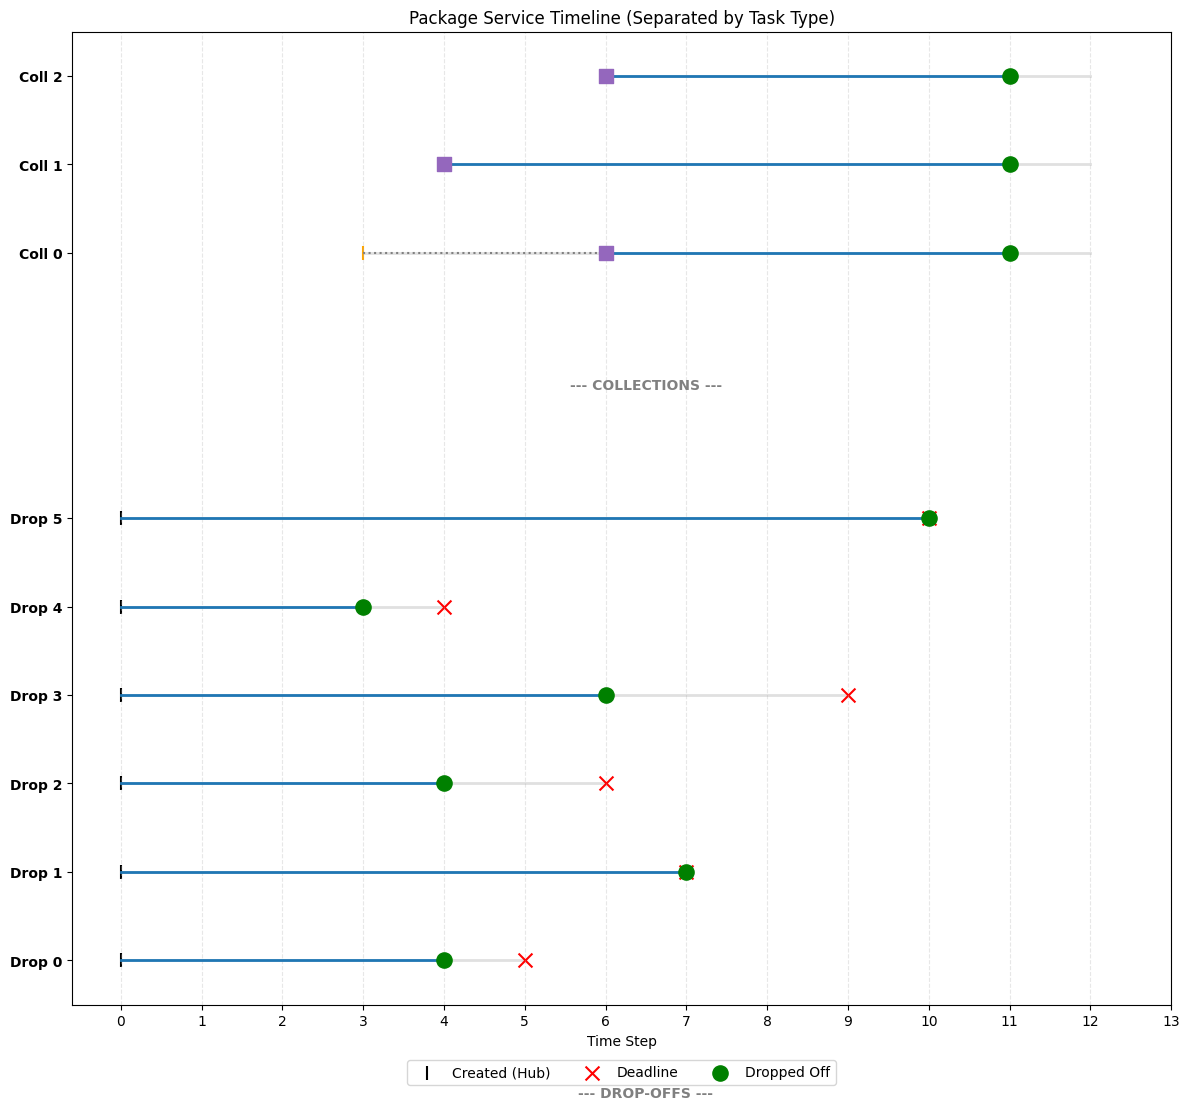

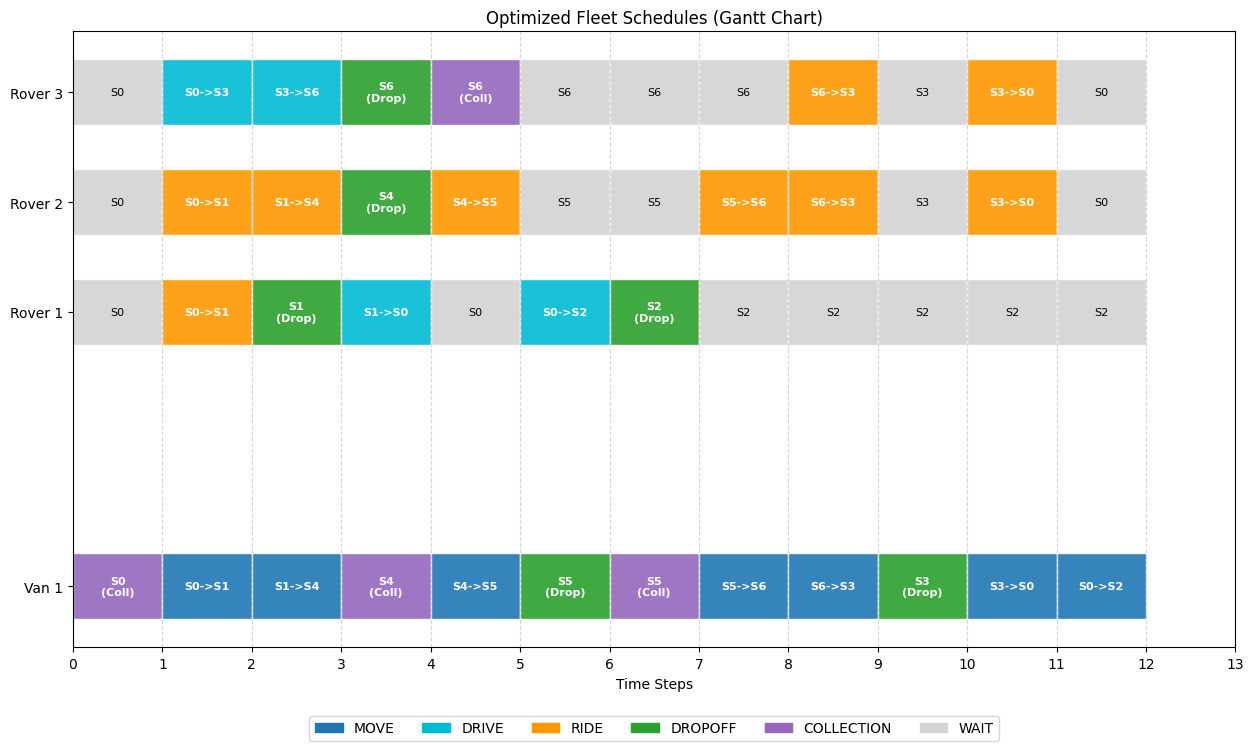

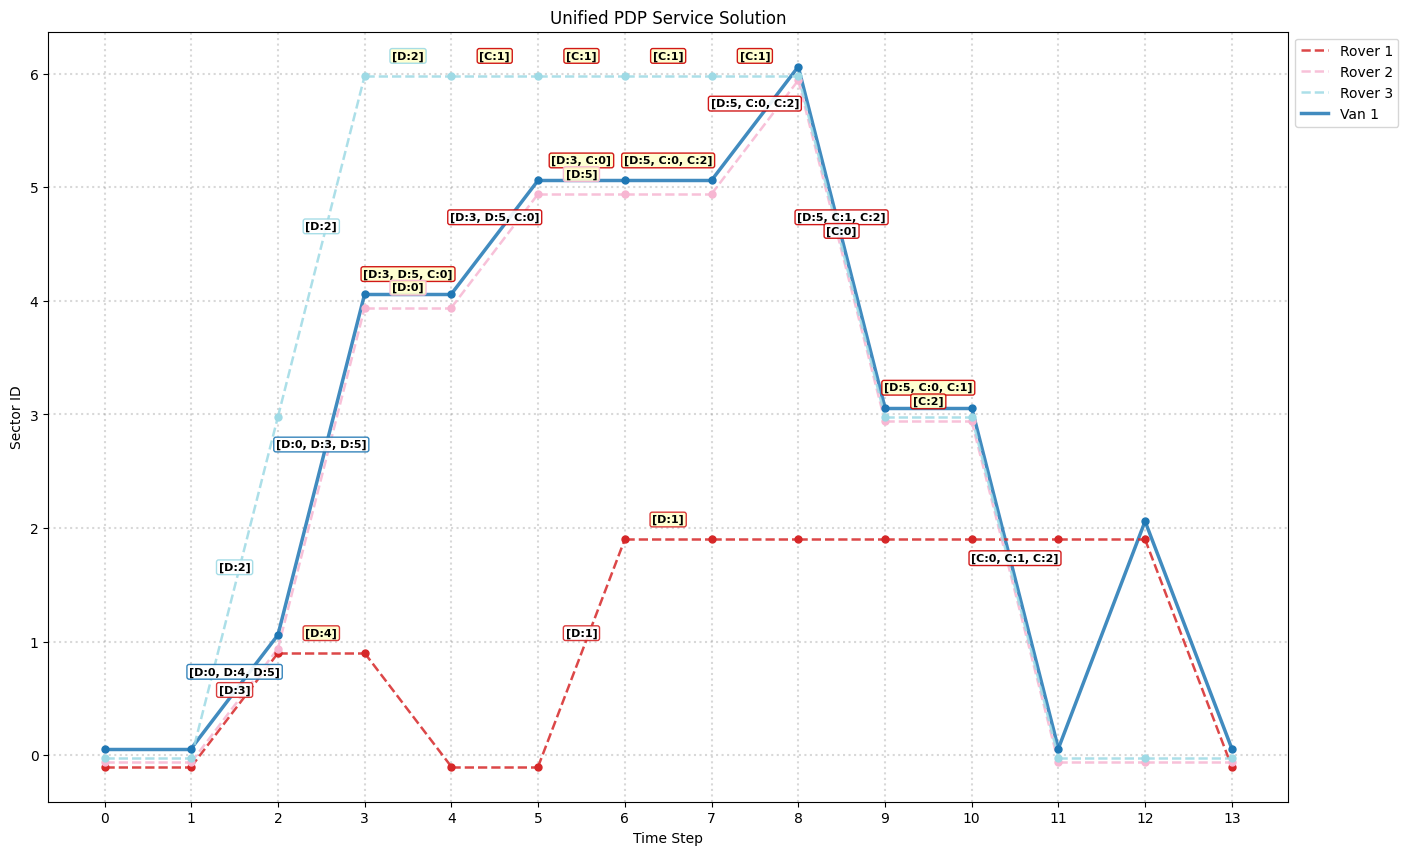

In [49]:
# --- PART 2: SOLUTION REPORTING AND VISUALIZATION ---

if model_small_case_3.status == GRB.OPTIMAL:
    print(f"\nOptimization Successful!")
    print(f"Objective Value: {model_small_case_3.ObjVal}")
    print(f"Solve Time: {model_small_case_3.Runtime:.2f}s")
    
    # 1. Raw Data Status Reports
    report_raw_dropoff_status(model_small_case_3)
    report_raw_collection_status(model_small_case_3)

    # 2. Detailed Text Report
    print_detailed_fleet_status_PDP(model_small_case_3, drop_offs_S, collections_S, hub_S, time_steps_S)
    
    # 3. Generate Visualizations
    fig_timeline = plot_service_timeline_3(model_small_case_3, drop_offs_S, collections_S, hub_S, time_steps_S)
    fig_gantt = plot_gantt_chart_3(model_small_case_3, hub_S, time_steps_S)
    fig_spatial = visualize_time_space_solution_PDP(model_small_case_3, G_small_PDP, drop_offs_S + collections_S, title="Unified PDP Service Solution")
    
    # Show plots if running in a notebook environment
    plt.show()

## 3.5 Results - Medium Instance

In [16]:
# --- PART 1: PROBLEM SETUP AND SOLVER EXECUTION (MEDIUM) ---

# Extract data from the medium dictionary
sectors_M = data_medium["network"]["sectors"]
adjacency_M = data_medium["network"]["adjacency"]
time_steps_M = data_medium["network"]["time_steps"]
hub_M = data_medium["network"]["hub"]
drop_offs_M = data_medium["drop_offs"]
collections_M = data_medium["collections"]
params_M = data_medium["parameters"]

# 1. Adjust time steps to ensure vehicles have enough time to return to the hub
time_steps_M = time_steps_M + 1

# 2. Build the graph
print("Building Graph (Medium Dataset)...")
G_medium_PDP = build_time_space_multigraph_pick_and_deliver(sectors_M, adjacency_M, time_steps_M, hub=hub_M)
print(f"Graph generated with {G_medium_PDP.number_of_nodes()} nodes and {G_medium_PDP.number_of_edges()} edges.")

# 3. Solve the model
print("Optimizing...")
model_medium_case_3 = solve_scenario_energy_tracking_PDP(
    sectors_M, adjacency_M, time_steps_M, hub_M, drop_offs_M, collections_M, params_M, G_medium_PDP
)

# 4. Handle Infeasibility
if model_medium_case_3.status == GRB.INFEASIBLE:
    print("\nModel is infeasible. Computing IIS...")
    model_medium_case_3.computeIIS()
    model_medium_case_3.write("infeasible_model_medium.ilp")
    print("IIS written to 'infeasible_model_medium.ilp'. Open this file to see the conflict.")
    
    # Print the specific constraints causing the issue
    for c in model_medium_case_3.getConstrs():
        if c.IISConstr:
            print(f"Conflict Constraint: {c.ConstrName}")
elif model_medium_case_3.status != GRB.OPTIMAL:
    print(f"Model stopped with status code: {model_medium_case_3.status}")

Building Graph (Medium Dataset)...
Graph generated with 252 nodes and 2428 edges.
Optimizing...
Generating Dropoff Variables...
Generating Collection Variables...
Skipped 6225 variables due to basic time windows.
Applying Asset Balance & Fleet Limits...
Applying Strict Chain of Custody...
Applying Collection Precedence Constraints...
Applying Energy Balance constraints...
Applying Hub-Only Strong Linking...
Set parameter TimeLimit to value 3600
Set parameter Cuts to value 2
Set parameter Symmetry to value 2
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  3600
Method  2
Symmetry  2
Cuts  2
Presolve  2
Seed  42

Optimize a model with 10983 rows, 38226 columns and 142602 nonzeros
Model fingerpri

## 3.6 Visualization - Medium Instance


Optimization Successful!
Objective Value: 105.0
Solve Time: 3600.06s

              RAW SOLVER DATA: DROPOFF VARIABLES (Including Waits)              

--- DROPOFF PACKAGE ID: 0 ---
Time       | From (Sector, Time)  | To (Sector, Time)    | Fleet/Action
---------------------------------------------------------------------------
1          | (0, 1)               | (0, 2)               | Hub_Shelf (WAIT)
2          | (0, 2)               | (0, 3)               | Hub_Shelf (WAIT)
3          | (0, 3)               | (1, 4)               | Van (MOVE)
4          | (1, 4)               | (4, 5)               | Van (MOVE)
5          | (4, 5)               | (10, 6)              | Van (MOVE)
6          | (10, 6)              | (10, 7)              | Dropoff_Rover (WAIT)

--- DROPOFF PACKAGE ID: 1 ---
Time       | From (Sector, Time)  | To (Sector, Time)    | Fleet/Action
---------------------------------------------------------------------------
1          | (0, 1)               | (0, 2)      

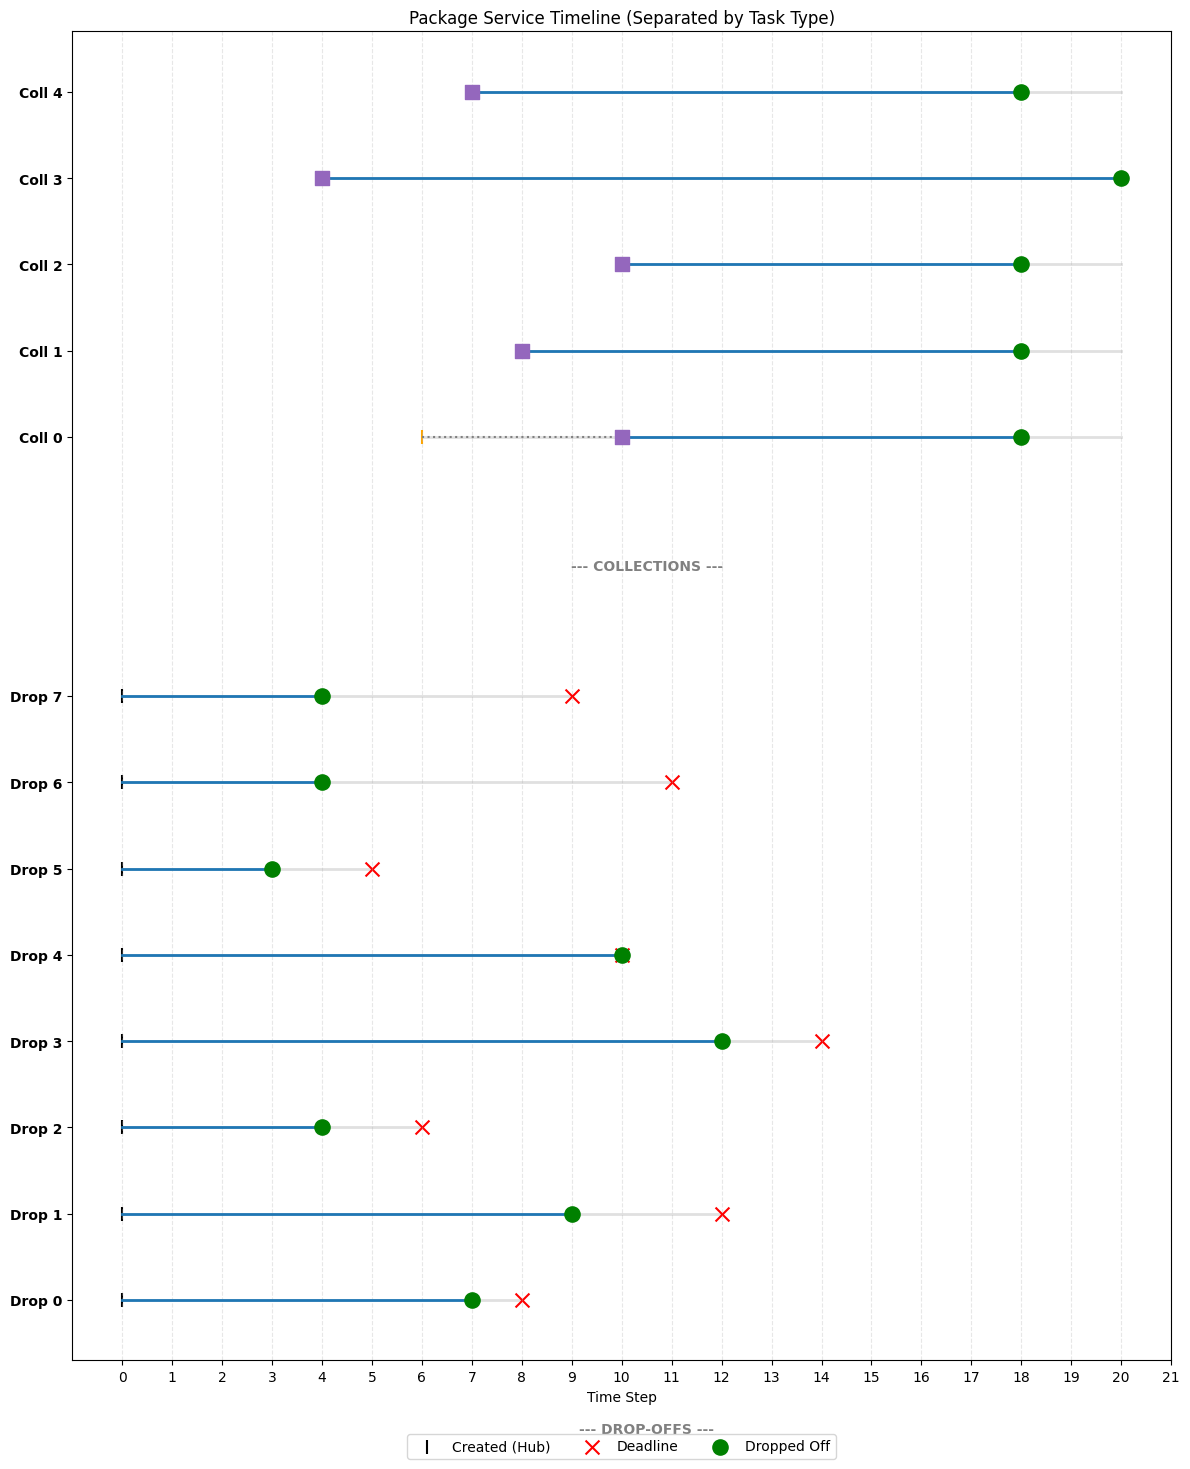

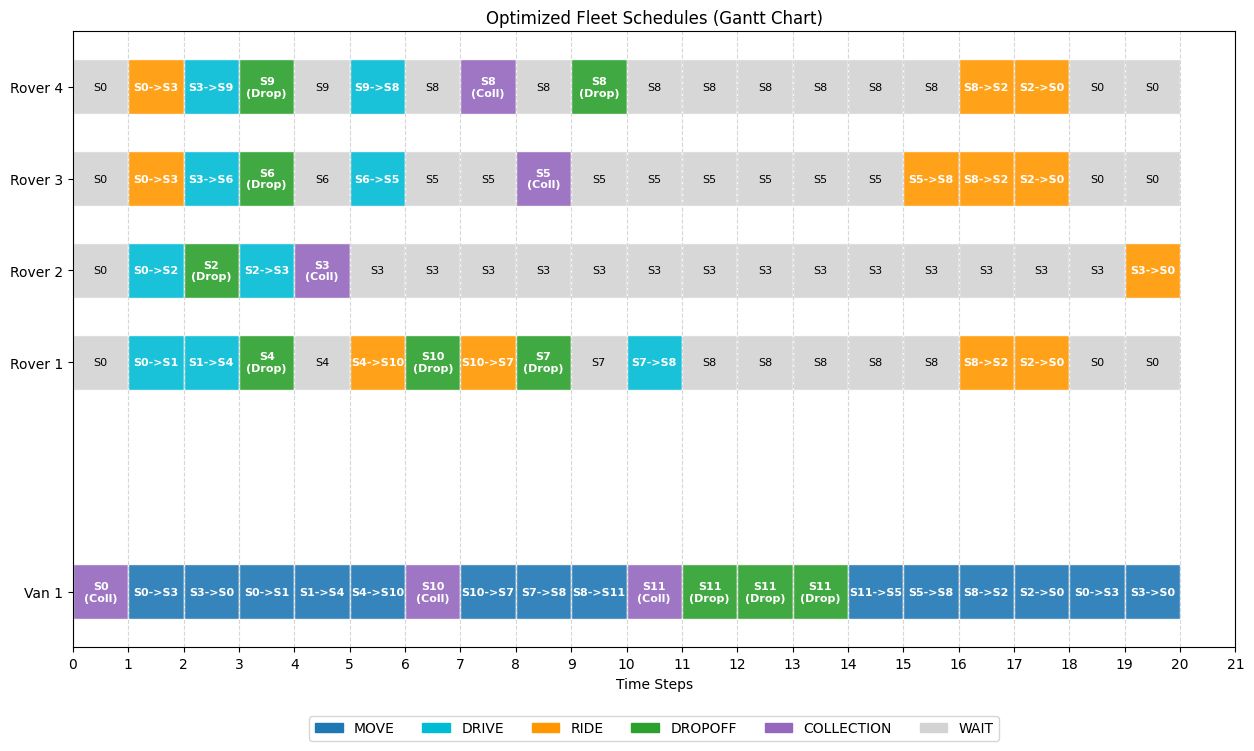

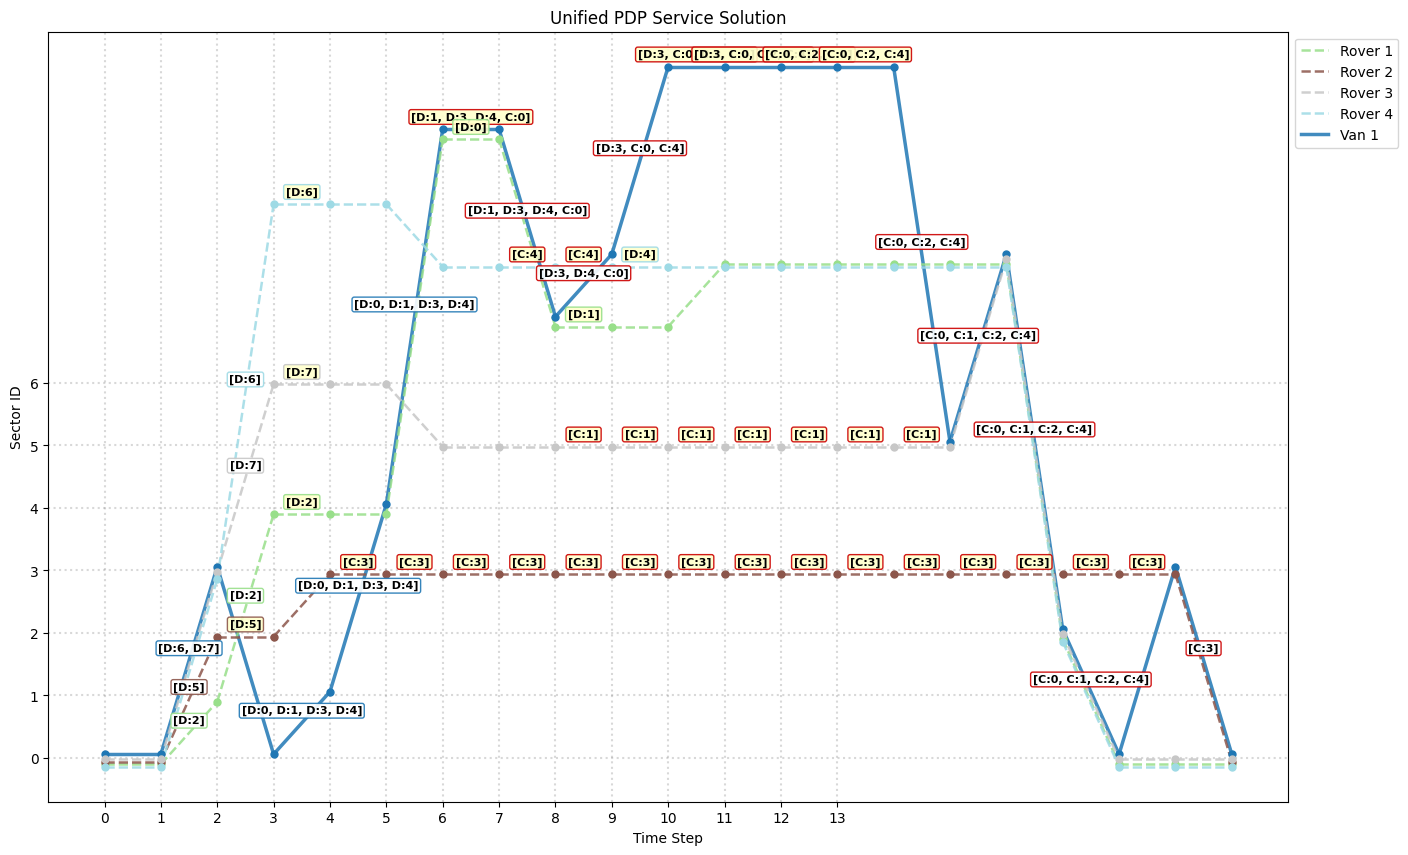

In [50]:
# --- PART 2: SOLUTION REPORTING AND VISUALIZATION ---

if model_medium_case_3.SolCount > 0:
    print(f"\nOptimization Successful!")
    print(f"Objective Value: {model_medium_case_3.ObjVal}")
    print(f"Solve Time: {model_medium_case_3.Runtime:.2f}s")
    
    # 1. Raw Data Status Reports
    report_raw_dropoff_status(model_medium_case_3)
    report_raw_collection_status(model_medium_case_3)

    # 2. Detailed Text Report
    print_detailed_fleet_status_PDP(model_medium_case_3, drop_offs_M, collections_M, hub_M, time_steps_M)
    
    # 3. Generate Visualizations
    fig_timeline = plot_service_timeline_3(model_medium_case_3, drop_offs_M, collections_M, hub_M, time_steps_M)
    fig_gantt = plot_gantt_chart_3(model_medium_case_3, hub_M, time_steps_M)
    fig_spatial = visualize_time_space_solution_PDP(model_medium_case_3, G_small_PDP, drop_offs_M + collections_M, title="Unified PDP Service Solution")
    
    # Show plots if running in a notebook environment
    plt.show()

---

# Comparison and Analysis

## 4.1 Summary Tables

Create summary tables comparing the three scenarios for both instances.

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
from gurobipy import GRB

def generate_comparative_statistics(models_dict):
    """
    Extracts core Gurobi statistics from a dictionary of models and 
    formats them into a comparative pandas DataFrame.
    """
    stats_list = []
    
    for name, model in models_dict.items():
        # Handle solver status
        if model.Status == GRB.OPTIMAL:
            status_str = "Optimal"
        elif model.Status == GRB.TIME_LIMIT:
            status_str = "Time Limit"
        elif model.Status == GRB.INFEASIBLE:
            status_str = "Infeasible"
        else:
            status_str = f"Status Code: {model.Status}"

        # Handle objective and gap based on solution count
        if model.SolCount > 0:
            obj_val = round(model.ObjVal, 2)
            # Gap is usually a fraction; convert to percentage
            gap = f"{model.MIPGap * 100:.2f}%" if hasattr(model, 'MIPGap') else "0.00%"
        else:
            obj_val = "-"
            gap = "-"

        stats_list.append({
            "Scenario Name": name,
            "Status": status_str,
            "Runtime (s)": round(model.Runtime, 2),
            "Objective": obj_val,
            "MIP Gap": gap,
            "Variables": model.NumVars,
            "Constraints": model.NumConstrs
        })

    df_stats = pd.DataFrame(stats_list)
    return df_stats

# Define the models to compare
models_to_compare = {
    "Small Baseline": model_small,
    "Small Recharge": model_small_recharge,
    "Small PDP": model_small_case_3,
    "Medium Baseline": model_medium,
    "Medium Recharge": model_medium_recharge,
    "Medium PDP": model_medium_case_3
}

# Generate and display the table
df_comparison = generate_comparative_statistics(models_to_compare)
print("\n--- COMPARATIVE MODEL STATISTICS ---")
display(df_comparison)


--- COMPARATIVE MODEL STATISTICS ---


,Scenario Name,Status,Runtime (s),Objective,MIP Gap,Variables,Constraints
0,Small Baseline,Optimal,7.86,73.0,0.00%,5161,3186
1,Small Recharge,Optimal,6.33,73.0,0.00%,5161,3183
2,Small PDP,Optimal,11.25,82.5,0.00%,9478,3346
3,Medium Baseline,Optimal,2250.16,83.5,0.00%,21424,11595
4,Medium Recharge,Optimal,2094.21,83.5,0.00%,21424,11592
5,Medium PDP,Time Limit,3600.06,105.0,11.43%,38226,10983



VISUALIZING ALL SMALL CASES (SIDE-BY-SIDE)
--- Parsing Solution for Visualization ---


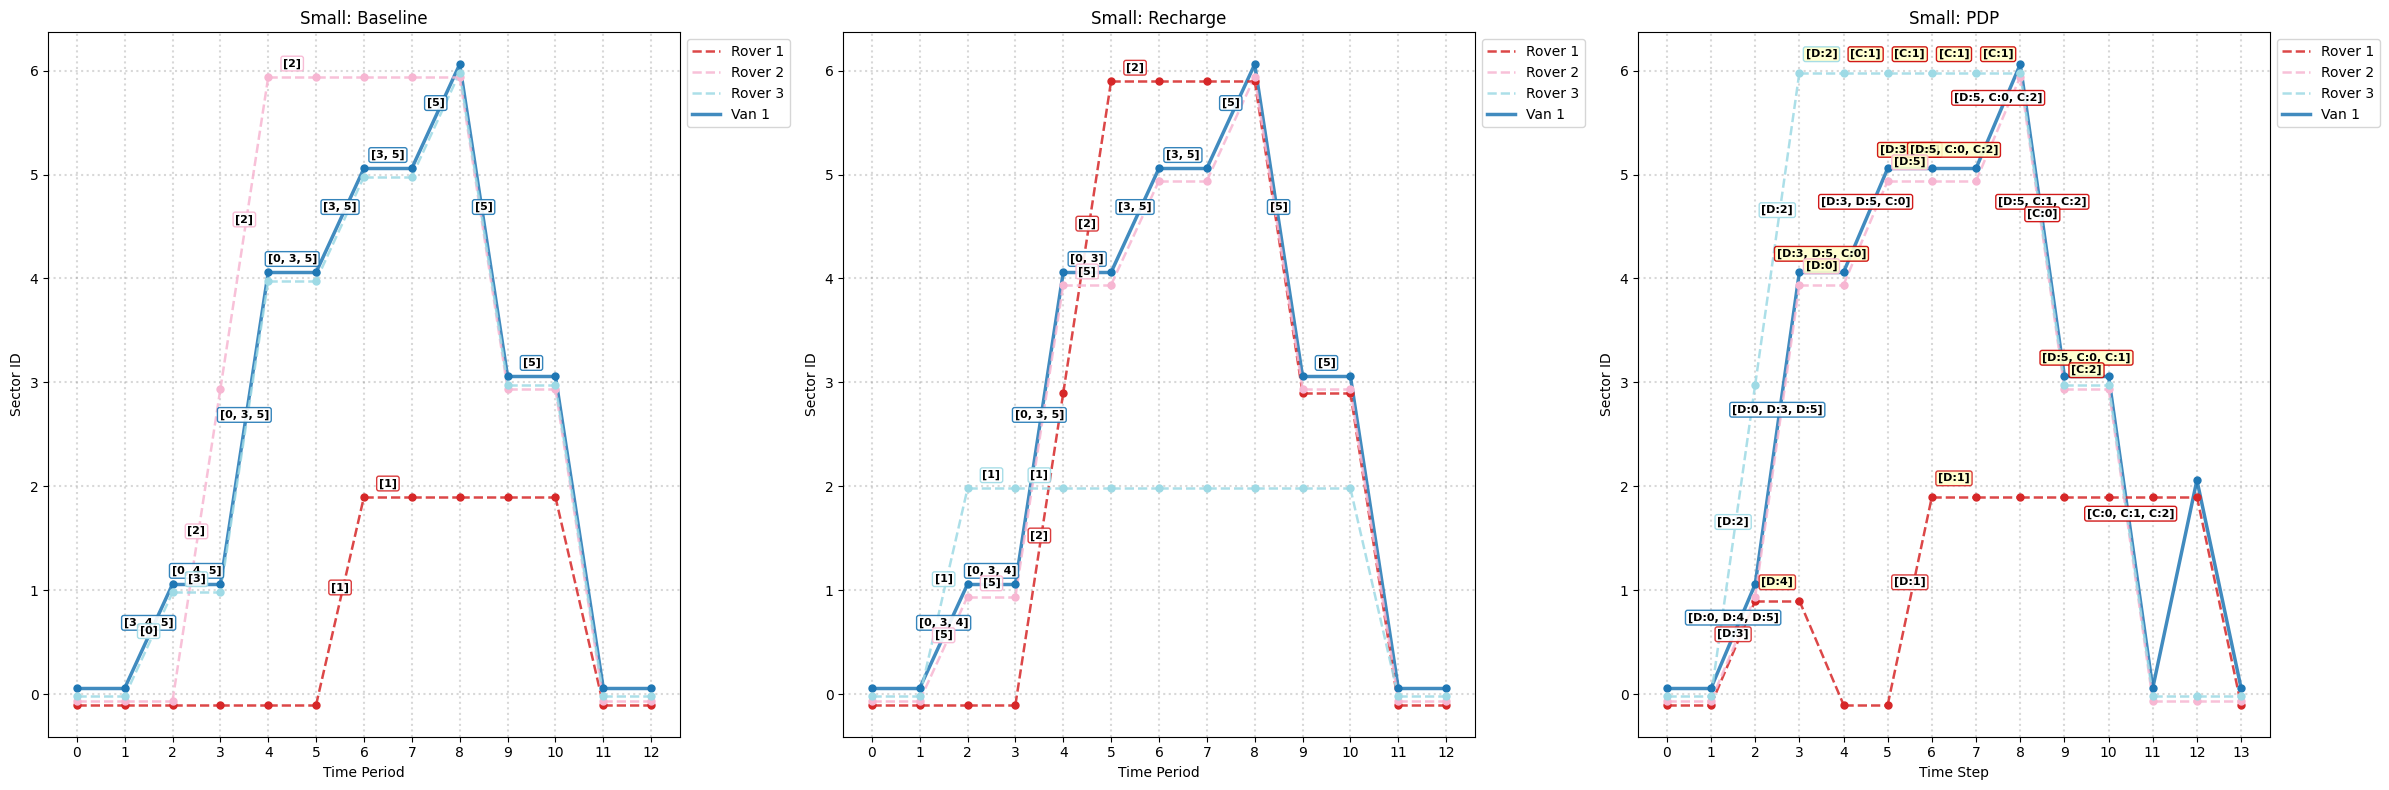


VISUALIZING ALL MEDIUM CASES (SIDE-BY-SIDE)
--- Parsing Solution for Visualization ---


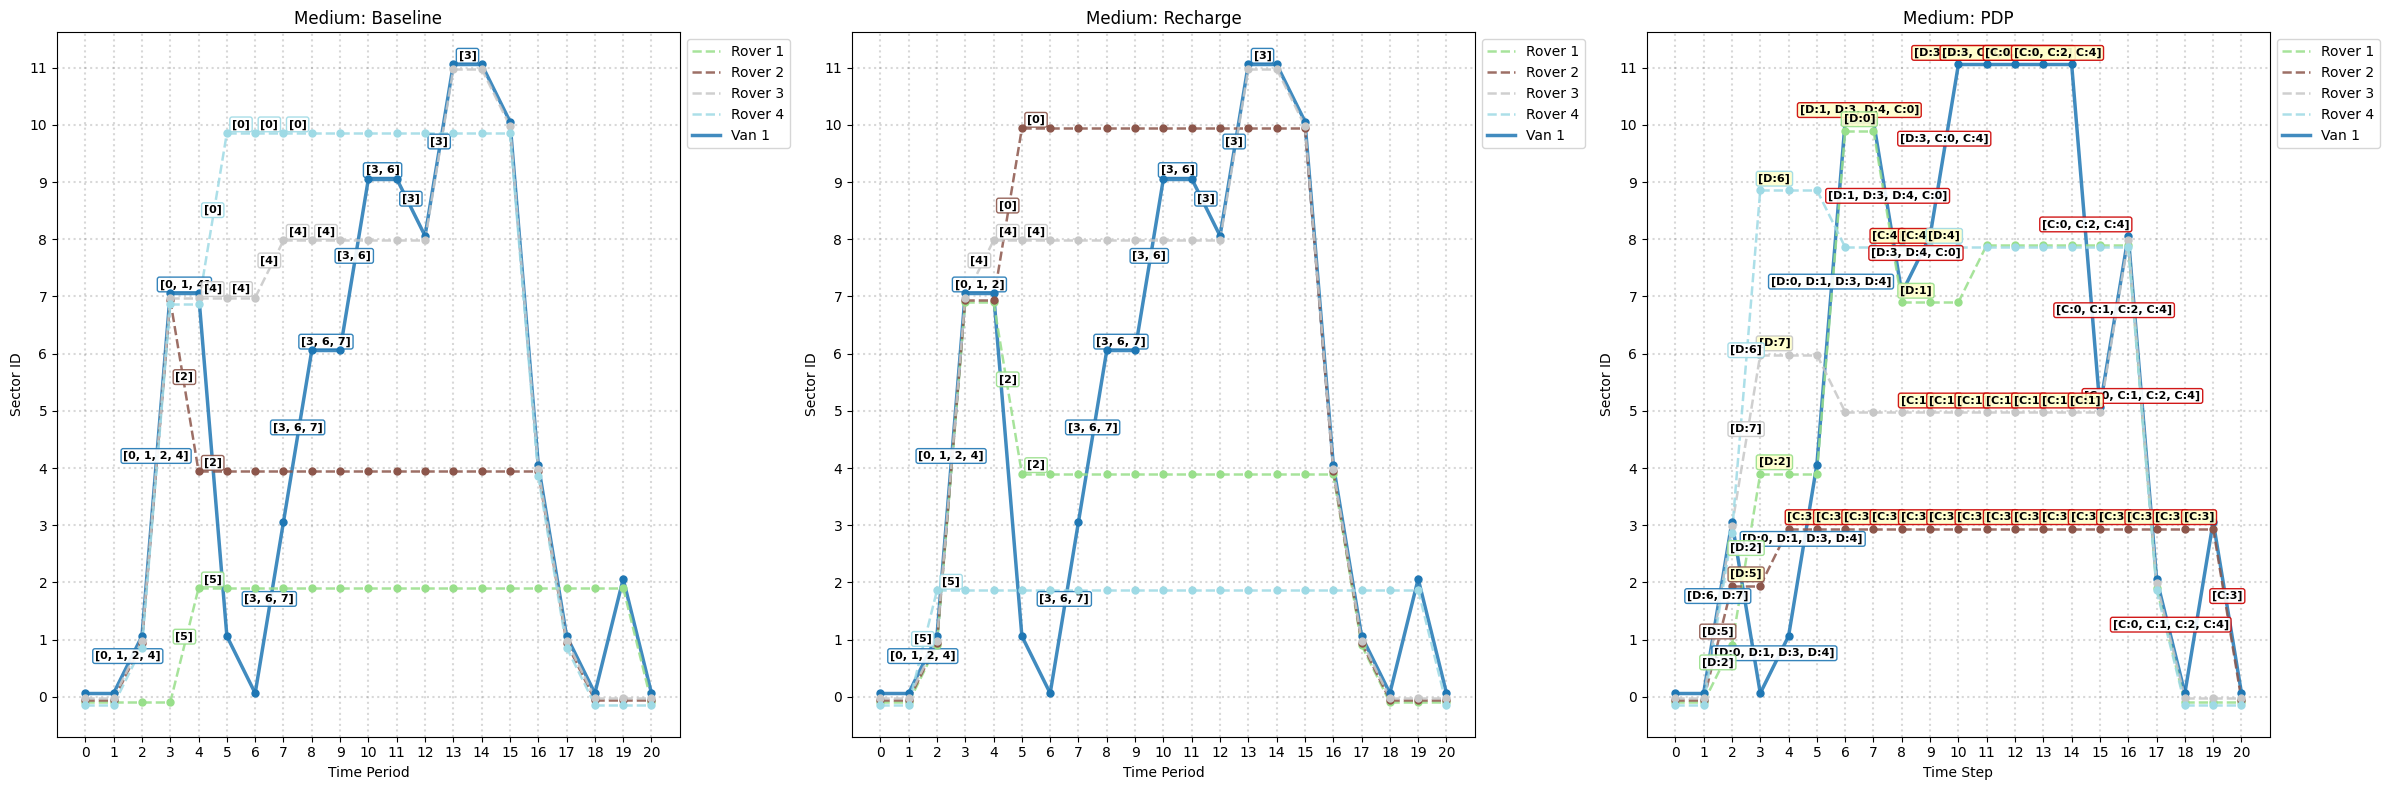

In [62]:
import matplotlib.pyplot as plt

# --- VISUALIZATION: SMALL CASES (SIDE-BY-SIDE) ---
print("\n" + "="*80)
print("VISUALIZING ALL SMALL CASES (SIDE-BY-SIDE)")
print("="*80)

# Create a 1x3 grid of subplots for the Small cases
fig_small, axes_small = plt.subplots(1, 3, figsize=(24, 8)) 

# Plot 1: Baseline
if model_small.SolCount > 0:
    visualize_time_space_solution(model_small, G_small, title="Small: Baseline", ax=axes_small[0])
else:
    axes_small[0].set_title("Small Baseline: No Solution")
    axes_small[0].axis('off')

# Plot 2: Recharge
if model_small_recharge.SolCount > 0:
    visualize_time_space_solution(model_small_recharge, G_small, title="Small: Recharge", ax=axes_small[1])
else:
    axes_small[1].set_title("Small Recharge: No Solution")
    axes_small[1].axis('off')

# Plot 3: PDP (Drop-offs + Collections)
if model_small_case_3.SolCount > 0:
    visualize_time_space_solution_PDP(model_small_case_3, G_small_PDP, drop_offs_S + collections_S, title="Small: PDP", ax=axes_small[2])
else:
    axes_small[2].set_title("Small PDP: No Solution")
    axes_small[2].axis('off')

plt.tight_layout()
plt.show()


# --- VISUALIZATION: MEDIUM CASES (SIDE-BY-SIDE) ---
print("\n" + "="*80)
print("VISUALIZING ALL MEDIUM CASES (SIDE-BY-SIDE)")
print("="*80)

# Create a 1x3 grid of subplots for the Medium cases
fig_med, axes_med = plt.subplots(1, 3, figsize=(24, 8))

# Plot 1: Baseline
if model_medium.SolCount > 0:
    visualize_time_space_solution(model_medium, G_medium, title="Medium: Baseline", ax=axes_med[0])
else:
    axes_med[0].set_title("Medium Baseline: No Solution")
    axes_med[0].axis('off')

# Plot 2: Recharge
if model_medium_recharge.SolCount > 0:
    visualize_time_space_solution(model_medium_recharge, G_medium, title="Medium: Recharge", ax=axes_med[1])
else:
    axes_med[1].set_title("Medium Recharge: No Solution")
    axes_med[1].axis('off')

# Plot 3: PDP (Drop-offs + Collections)
if model_medium_case_3.SolCount > 0:
    visualize_time_space_solution_PDP(model_medium_case_3, G_medium_PDP, drop_offs_M + collections_M, title="Medium: PDP", ax=axes_med[2])
else:
    axes_med[2].set_title("Medium PDP: No Solution")
    axes_med[2].axis('off')

plt.tight_layout()
plt.show()

## 4.3 Discussion

Discuss the differences between the three scenarios. Address the following questions:

1. How does allowing recharging (Scenario 2) impact the solution compared to Scenario 1?
2. What is the benefit of parcel transfers in Scenario 3?
3. How do solve times differ between scenarios? Why?
4. What are the key trade-offs between model complexity and solution quality?

**Your discussion:**

The comparison of the three scenarios highlights the tension in optimization modeling: gaining operational efficiency usually requires increasing mathematical complexity.

**1. Impact of Recharging (Scenario 2 vs Scenario 1)**

-) Identical Objectives: In both the Small (Objective 73.0) and Medium (Objective 83.5) datasets, allowing droids to recharge (Scenario 2) did not improve the final solution cost compared to the baseline (Scenario 1). This indicates the physical size of the network and the time horizon in these instances are compact enough that the droids do not exhaust their base battery limits, or they natively catch enough rides on vans to complete their routes without requiring dedicated recharging detours.

-) Comparable Runtimes: The solve times between Baseline and Recharge were highly similar for both instance sizes. Interestingly, the Medium Recharge scenario (2094s) solved slightly faster than the Medium Baseline (2250s), despite having slightly fewer constraints (11,592 vs 11,595). Both models successfully reached a guaranteed 0.00% optimality gap.

**2. What is the benefit of parcel transfers in Scenario 3?**

-) Expanded Service Capabilities (Pickups): The primary benefit of Scenario 3 is the ability to service an entirely new class of demand (collections/pickups) in addition to drop-offs. It treats packages as independent commodities that can change hands at intermediate nodes or wait on a hub shelf.

-) Workload vs. Objective Cost: The objective value represents the operational cost (energy and movement). Because Scenario 3 introduces new tasks (collections), the objective value naturally increases in both the Small (from 73.0 to 82.5) and Medium (from 83.5 to 105.0) datasets. The model is doing more physical work.

-) The Cost of Flexibility: This decoupled logistics model allows for complex routing strategies, but it comes at a severe computational cost. In the Medium dataset, the flexibility prevents the solver from proving optimality within the given time limit.

**3. How do solve times differ between scenarios? Why?**

-) Small Instances: All scenarios solved in a matter of seconds (6–11s). The state space is small enough that the added complexity of tracking collections and drop-offs independently (Scenario 3) barely impacts the branch-and-bound tree.

-) Medium Instances: The computational jump is exponential. Scenarios 1 and 2 took around 35 to 37 minutes to prove optimality. Scenario 3 (PDP) hit the 3600-second (1-hour) time limit.

-) The "Why" (Combinatorial Explosion): Scenario 3 dramatically increases the state space. The Medium Baseline uses 21,424 variables, and the Medium PDP uses 38,226. Tracking the exact energy state of every rover, the location of every individual package independently of the vehicles, and permitting intermediate waiting states introduces heavy symmetry into the mathematical model. The solver explores thousands of fractional branches that represent identical physical realities, stalling the lower bound progression and leaving an 11.43% optimality gap.

**4. What are the key trade-offs between model complexity and solution quality?**

The core trade-off is between guaranteed optimality and operational flexibility:

-) Scenarios 1 & 2 (Deliveries Only): These represent a manageable level of complexity. They are computationally heavy for medium maps (~35 mins), but they can be solved to guaranteed optimality (0.00% gap). The trade-off is absolute confidence in the solution quality (cost of 83.5) at the expense of ignoring pickup requests and relay logic.

-) Scenario 3 (PDP & Transfers): This model offers maximum operational flexibility by handling bi-directional logistics (pickups and drop-offs). The trade-off is that for anything larger than a trivial map, the model becomes too mathematically dense for exact solving in practical timeframes. We accept a heuristic solution (an incumbent of 105.0 with an 11.43% uncertainty gap) because the extreme flexibility makes proving optimality computationally expensive.